# Comparing structural features to confidence scores

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
import statsmodels.api as sm

In [2]:
SIGNIFICANCE_LEVEL = 0.05

In [3]:
entries = pd.read_csv('../data/interim/sequences_sample_1500.csv')

In [4]:
entries['type'] = entries['label'].map(lambda label: 'binder' if label else 'decoy')

In [5]:
confidence_scores = pd.read_csv('../data/processed/confidence_scores_af3_tcrmodel2_1500.csv')
af3_structural_features = pd.read_csv('../data/processed/predicted_af3_tcrmodel2_structural_features_1500.csv')

structure_scores = entries.merge(
    confidence_scores,
    how='left',
    left_on='index',
    right_on='structure_name',
).merge(
    af3_structural_features,
    how='inner',
    left_on=['index', 'sample', 'seed'],
    right_on=['name', 'sample', 'seed'],
)

In [6]:
structural_features = pd.read_csv('../data/processed/tcr_pmhc_structural_features.csv')

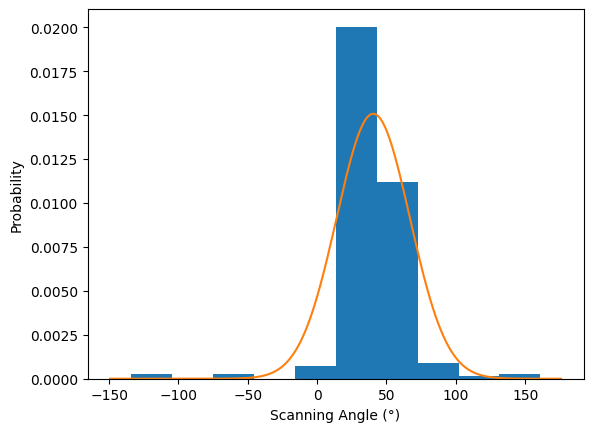

In [7]:
loc, scale = scipy.stats.norm.fit(structural_features['scanning_angle'])
scanning_angle = scipy.stats.norm(loc=loc, scale=scale)

ax = structural_features['scanning_angle'].plot.hist(density=True)

x = np.linspace(*ax.get_xlim(), 1000)
y = scanning_angle.pdf(x)

plt.plot(x, y, '-')

plt.xlabel('Scanning Angle (°)')
plt.ylabel('Probability')

plt.show()

In [8]:
structure_scores['scanning_angle_probability'] = structure_scores['scanning_angle'].apply(scanning_angle.pdf)

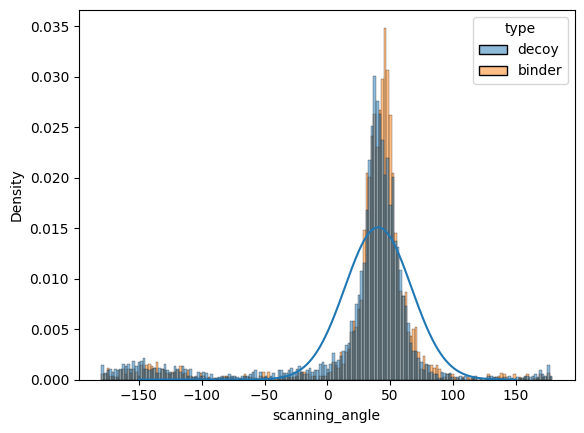

In [9]:
x = np.linspace(-150, 150, 1000)
plt.plot(x, scanning_angle.pdf(x))

sns.histplot(structure_scores, hue='type', x='scanning_angle', stat='density', common_norm=False)

plt.show()

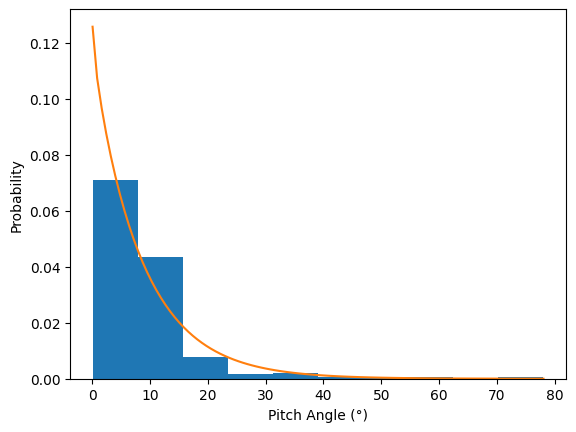

In [10]:
a, loc, scale = scipy.stats.gamma.fit(structural_features['pitch_angle'], floc=0)
pitch_angle = scipy.stats.gamma(a=a, loc=loc, scale=scale)

ax = structural_features['pitch_angle'].plot.hist(density=True)

x = np.linspace(structural_features['pitch_angle'].min(), structural_features['pitch_angle'].max(), 100)
y = pitch_angle.pdf(x)

plt.plot(x, y, '-')


plt.xlabel('Pitch Angle (°)')
plt.ylabel('Probability')

plt.show()

In [11]:
structure_scores['pitch_angle_probability'] = structure_scores['pitch_angle'].apply(pitch_angle.pdf).replace(np.inf, 1)

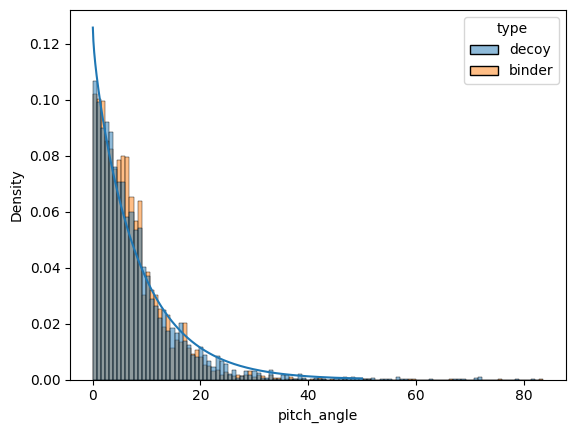

In [12]:
x = np.linspace(0, 50, 1000)
plt.plot(x, pitch_angle.pdf(x))

sns.histplot(structure_scores, x='pitch_angle', hue='type', stat='density', common_norm=False)

plt.show()

In [13]:
def z_score(x: float | np.ndarray, means: np.ndarray, variances: np.ndarray, weights: np.ndarray) -> float | np.ndarray:
    pdfs = [
        w * scipy.stats.norm.pdf(x, loc=mu, scale=np.sqrt(var))
        for w, mu, var in zip(weights, means, variances, strict=True)
    ]

    return np.sum(pdfs, axis=0)

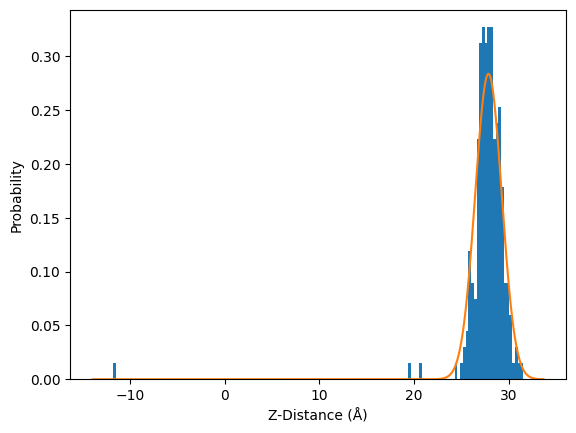

In [14]:
gmm = sklearn.mixture.GaussianMixture(n_components=2)
gmm.fit(structural_features['z_score'].to_numpy().reshape(-1, 1))

ax = structural_features['z_score'].plot.hist(bins=150, density=True)

x = np.linspace(*ax.get_xlim(), 1000)
y = z_score(x, gmm.means_.flatten(), gmm.covariances_.flatten(), gmm.weights_.flatten())

plt.plot(x, y, '-')

plt.xlabel('Z-Distance (Å)')
plt.ylabel('Probability')

plt.show()

In [15]:
structure_scores['z_score_probability'] = structure_scores['z_score'].apply(
    z_score, means=gmm.means_.flatten(), variances=gmm.covariances_.flatten(), weights=gmm.weights_.flatten()
)

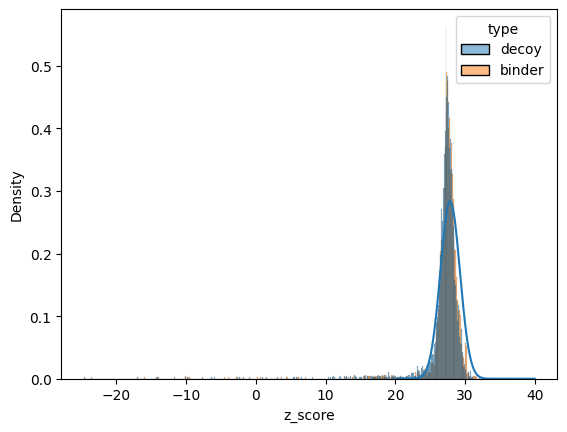

In [16]:
x = np.linspace(20, 40, 1000)
plt.plot(x, z_score(x, gmm.means_.flatten(), gmm.covariances_.flatten(), gmm.weights_.flatten()))

sns.histplot(structure_scores, x='z_score', hue='type', stat='density', common_norm=False)

plt.show()

In [17]:
contact_probabilities = pd.read_csv('../data/external/tcr_pmhc_contacts.csv')

contact_probabilities['proportion'] = contact_probabilities.groupby('mhc_type')['proportion'].transform(
    lambda group: group / group.sum()
)

contact_maps = pd.read_csv('../data/processed/predicted_af3_tcrmodel2_contact_maps_1500.csv')

contact_scores = (
    contact_maps.merge(
        contact_probabilities,
        how='left',
        on=[col for col in contact_probabilities if col != 'proportion'],
    )
    .groupby(['name', 'seed', 'sample'])['proportion']
    .aggregate(['sum', 'mean'])
)
contact_scores.columns = ['contact_map_probability_' + column_name for column_name in contact_scores.columns]

structure_scores = structure_scores.merge(
    contact_scores, how='left', left_on=['name', 'seed', 'sample'], right_index=True
)

<Axes: xlabel='score', ylabel='probability'>

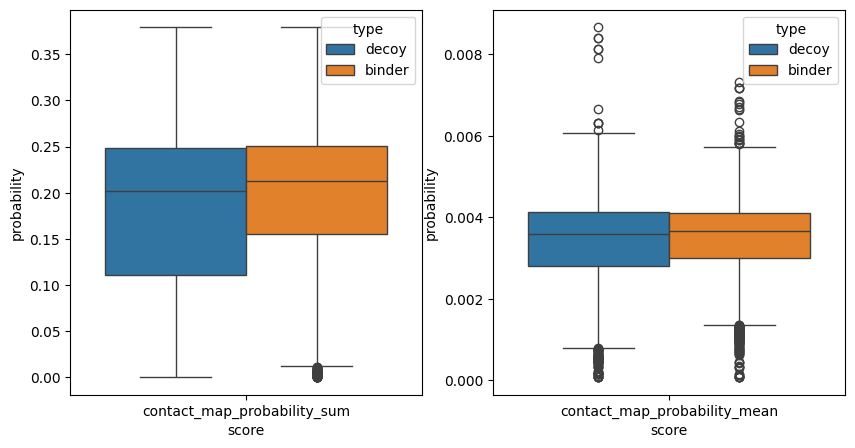

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.boxplot(
    structure_scores.melt(
        id_vars=['type', 'label'],
        value_vars='contact_map_probability_sum',
        var_name='score',
        value_name='probability',
    ),
    x='score',
    y='probability',
    hue='type',
    ax=axes[0],
)

sns.boxplot(
    structure_scores.melt(
        id_vars=['type', 'label'],
        value_vars='contact_map_probability_mean',
        var_name='score',
        value_name='probability',
    ),
    x='score',
    y='probability',
    hue='type',
    ax=axes[1],
)

In [19]:
structure_scores['contact_map_probability'] = structure_scores['contact_map_probability_mean']

In [20]:
interactions = pd.read_csv('../data/processed/tcr_pmhc_interactions.csv')

In [21]:
num_interactions = interactions.groupby('name').size()

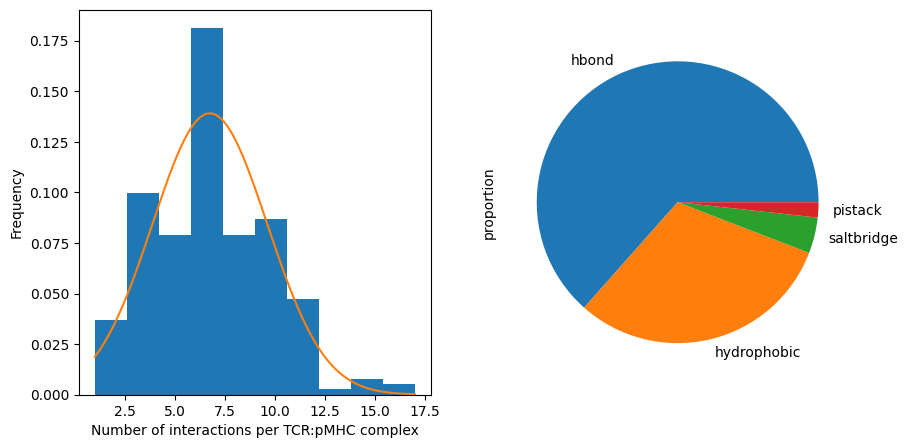

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

num_interactions.plot.hist(ax=axes[0], density=True)
x = np.linspace(num_interactions.min(), num_interactions.max(), 1000)
y = scipy.stats.norm.pdf(x, loc=num_interactions.mean(), scale=num_interactions.std())

axes[0].plot(x, y, '-')

axes[0].set_xlabel('Number of interactions per TCR:pMHC complex')

interactions.value_counts('type', normalize=True).plot.pie(ax=axes[1])

plt.show()

In [23]:
interaction_types = interactions.value_counts(['type', 'name'])

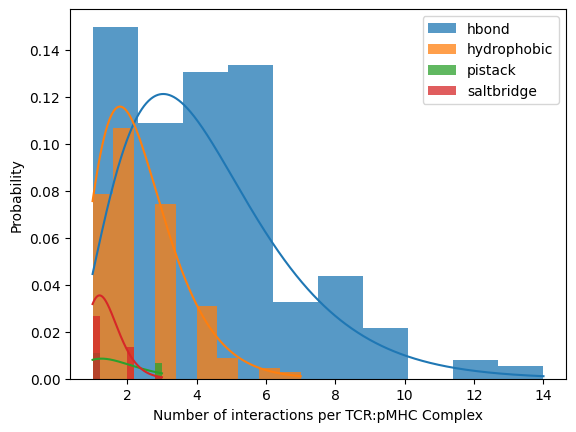

In [24]:
colours = plt.rcParams['axes.prop_cycle'].by_key()['color']

total_count = interaction_types.sum()

interaction_types_parameters = {}

for i, (interaction_type, group) in enumerate(interaction_types.reset_index().groupby('type')):
    interaction_types_parameters[interaction_type] = {}

    colour = colours[i % len(colours)]

    count = group['count']
    group_count = count.sum()

    weight = group_count / total_count

    a, loc, scale = scipy.stats.gamma.fit(group['count'], floc=0)

    interaction_types_parameters[interaction_type]['weight'] = weight
    interaction_types_parameters[interaction_type]['a'] = a
    interaction_types_parameters[interaction_type]['loc'] = loc
    interaction_types_parameters[interaction_type]['scale'] = scale

    x = np.linspace(count.min(), count.max(), 1000)
    y = scipy.stats.gamma.pdf(x, a=a, loc=loc, scale=scale) * weight

    plt.plot(x, y, '-', color=colour)

    counts, bins = np.histogram(count)
    probabilities = (counts / counts.sum()) * weight

    plt.stairs(
        probabilities,
        bins,
        fill=True,
        color=colour,
        alpha=0.75,
        label=interaction_type,
    )

plt.legend()
plt.ylabel('Probability')
plt.xlabel('Number of interactions per TCR:pMHC Complex')
plt.show()

In [25]:
af3_interactions = pd.read_csv('../data/processed/predicted_af3_af3_interactions_50.csv')
af3_interactions = af3_interactions.merge(
    entries, how='left', left_on='name', right_on='index', suffixes=('_interaction', '')
)

ROC-AUC: 0.6427692307692308


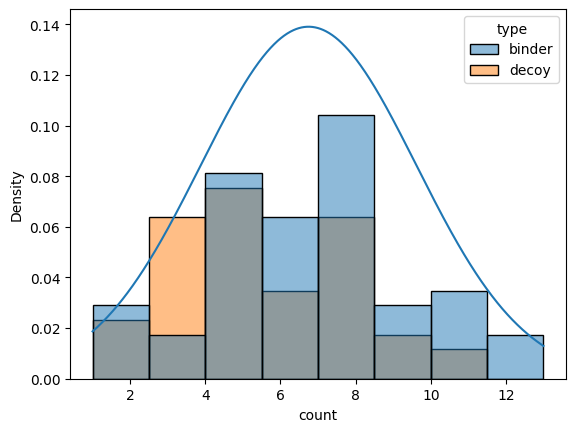

In [26]:
af3_interaction_counts = af3_interactions.groupby(['type', 'label', 'name', 'seed', 'sample']).size()
af3_interaction_counts.name = 'count'
af3_interaction_counts = af3_interaction_counts.reset_index()

sns.histplot(af3_interaction_counts, x='count', hue='type', stat='density')

x = np.linspace(af3_interaction_counts['count'].min(), af3_interaction_counts['count'].max(), 1000)
y = scipy.stats.norm.pdf(x, loc=num_interactions.mean(), scale=num_interactions.std())
plt.plot(x, y, '-')

print('ROC-AUC:', sklearn.metrics.roc_auc_score(af3_interaction_counts['label'], af3_interaction_counts['count']))

plt.show()

In [27]:
af3_interaction_counts['num_interactions_probability'] = scipy.stats.norm.pdf(
    af3_interaction_counts['count'], loc=num_interactions.mean(), scale=num_interactions.std()
)
structure_scores = structure_scores.merge(
    af3_interaction_counts[['name', 'seed', 'sample', 'num_interactions_probability']],
    how='left',
    left_on=['name', 'seed', 'sample'],
    right_on=['name', 'seed', 'sample'],
)
structure_scores['num_interactions_probability'] = structure_scores['num_interactions_probability'].fillna(0.0)

hbond ROC-AUC: 0.652834699453552
hydrophobic ROC-AUC: 0.5290423861852434
pistack ROC-AUC: nan
saltbridge ROC-AUC: 0.4615384615384615


/ceph/project/koohylab/bmcmaste/projects/tcr-pmhc-predicted-structures/.venv/lib/python3.11/site-packages/sklearn/metrics/_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


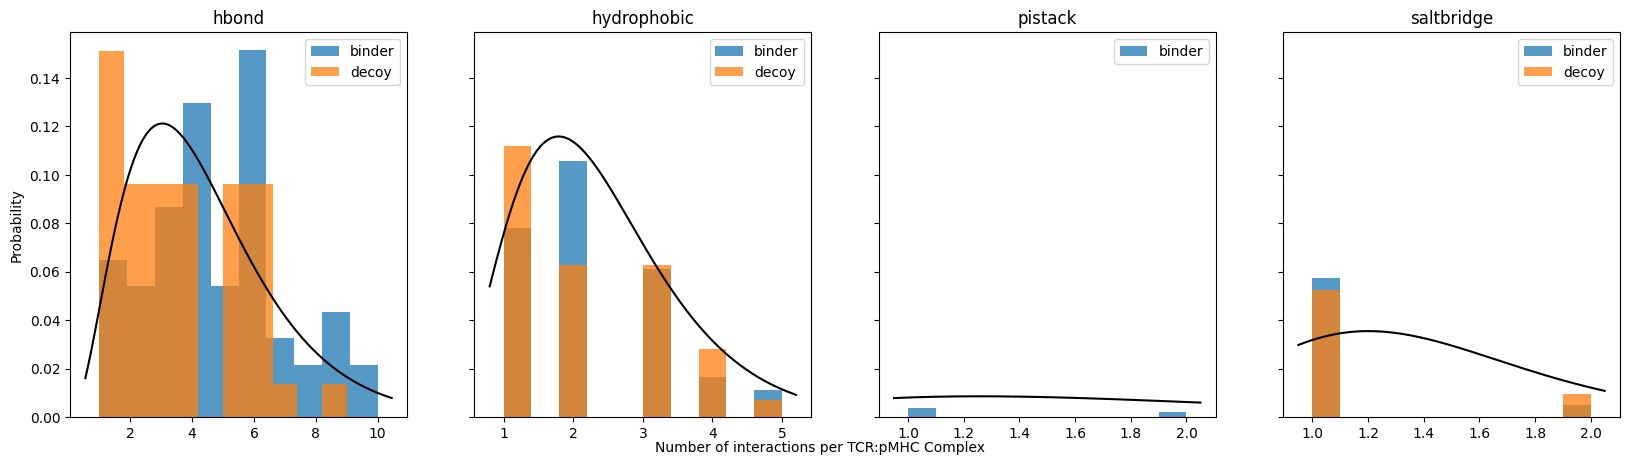

In [28]:
af3_interaction_types = af3_interactions.value_counts(
    ['name', 'seed', 'sample', 'type', 'label', 'type_interaction']
).reset_index()

total_count = af3_interaction_types['count'].sum()

number_of_interaction_types = len(interaction_types_parameters)

fig, axes = plt.subplots(1, number_of_interaction_types, figsize=(5 * number_of_interaction_types, 5), sharey=True)

for i, (interaction_type, group) in enumerate(af3_interaction_types.groupby('type_interaction')):
    group_count = group['count'].sum()

    weight = group_count / total_count

    for complex_type, sub_group in group.groupby('type'):
        counts, bins = np.histogram(sub_group['count'])
        probabilities = (counts / counts.sum()) * weight

        axes[i].stairs(
            probabilities,
            bins,
            fill=True,
            alpha=0.75,
            label=complex_type,
        )

    x = np.linspace(*axes[i].get_xlim(), 1000)
    y = (
        scipy.stats.gamma.pdf(
            x,
            a=interaction_types_parameters[interaction_type]['a'],
            loc=interaction_types_parameters[interaction_type]['loc'],
            scale=interaction_types_parameters[interaction_type]['scale'],
        )
        * interaction_types_parameters[interaction_type]['weight']
    )

    axes[i].plot(x, y, '-', color='black')

    axes[i].set_title(interaction_type)
    axes[i].legend()

    print(interaction_type, 'ROC-AUC:', sklearn.metrics.roc_auc_score(group['label'], group['count']))

axes[0].set_ylabel('Probability')
fig.text(0.5, 0.04, 'Number of interactions per TCR:pMHC Complex', ha='center')

plt.show()

In [29]:
index = pd.MultiIndex.from_frame(structure_scores[['name', 'seed', 'sample']])
probabilities = pd.Series(np.zeros(len(index)), index=index)
probabilities.name = 'interaction_type_probability'
for interaction_type, params in interaction_types_parameters.items():
    interaction_type_counts = af3_interaction_types[
        af3_interaction_types['type_interaction'] == interaction_type
    ].set_index(['name', 'seed', 'sample'])['count']

    interaction_type_probabilities = interaction_type_counts.apply(
        lambda counts, params=params: params['weight']
        * scipy.stats.gamma.pdf(counts, a=params['a'], loc=params['loc'], scale=params['scale']),
    )
    interaction_type_probabilities.name = 'interaction_type_probability'

    probabilities = probabilities.add(interaction_type_probabilities, fill_value=0.0)

structure_scores = structure_scores.merge(probabilities.reset_index(), how='left', on=['name', 'seed', 'sample'])

In [30]:
structure_probability_names = [
    'scanning_angle_probability',
    'pitch_angle_probability',
    'z_score_probability',
    'contact_map_probability',
    'num_interactions_probability',
    'interaction_type_probability',
]

In [31]:
structure_scores = structure_scores.dropna().copy()

In [32]:
with np.errstate(divide='ignore'):
    structure_scores['log_probability'] = structure_scores[structure_probability_names].apply(
        lambda row: np.sum(np.log(row)), axis=1
    )

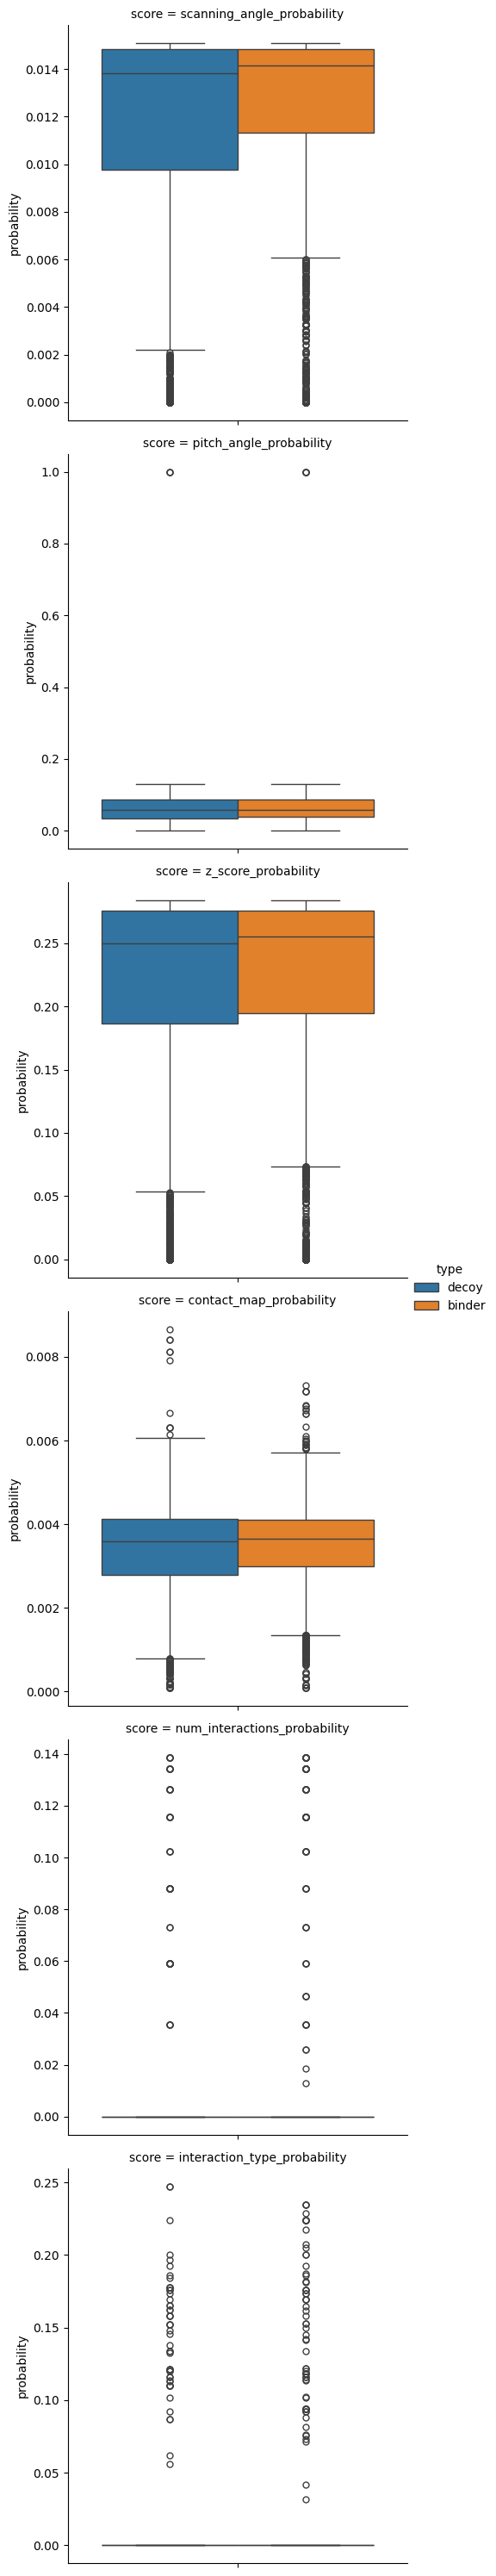

In [33]:
score_probabilities = structure_scores.melt(
    id_vars=['type', 'label'],
    value_vars=structure_probability_names,
    var_name='score',
    value_name='probability',
)
sns.catplot(score_probabilities, row='score', y='probability', hue='type', sharey=False, kind='box')

In [34]:
for score_name, group in score_probabilities.groupby('score'):
    print(score_name)
    print(sklearn.metrics.roc_auc_score(group['label'], group['probability']))

contact_map_probability
0.5239544227328592
interaction_type_probability
0.5020334387044354
num_interactions_probability
0.5020478161824361
pitch_angle_probability
0.5133149419282265
scanning_angle_probability
0.5293892932723111
z_score_probability
0.5189455815031649


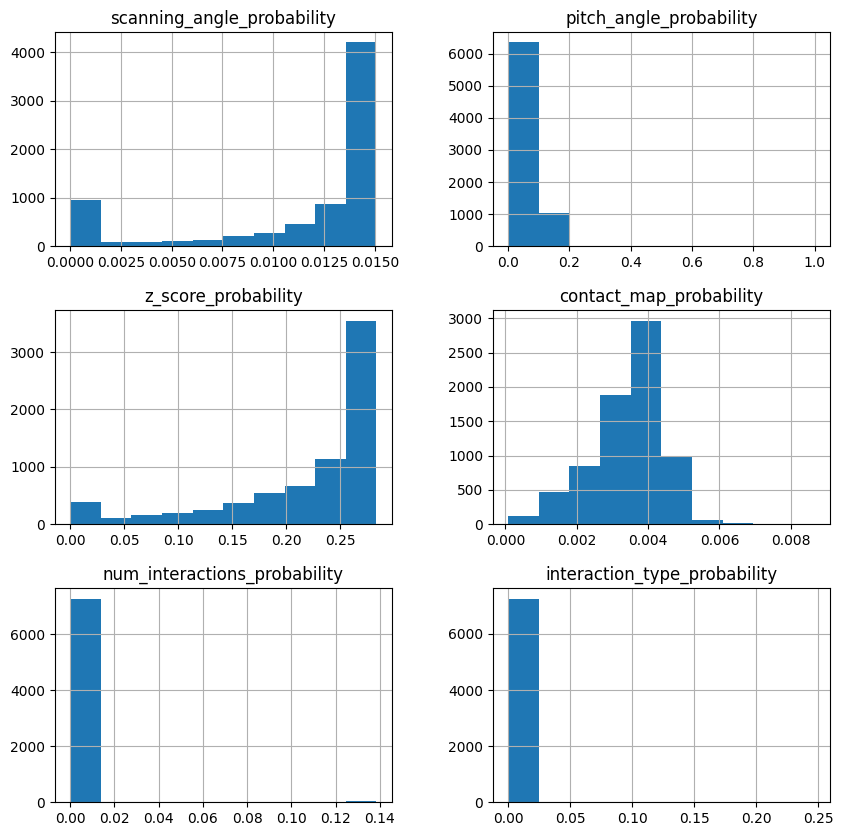

In [35]:
structure_scores[structure_probability_names].hist(figsize=(10, 10))
plt.show()

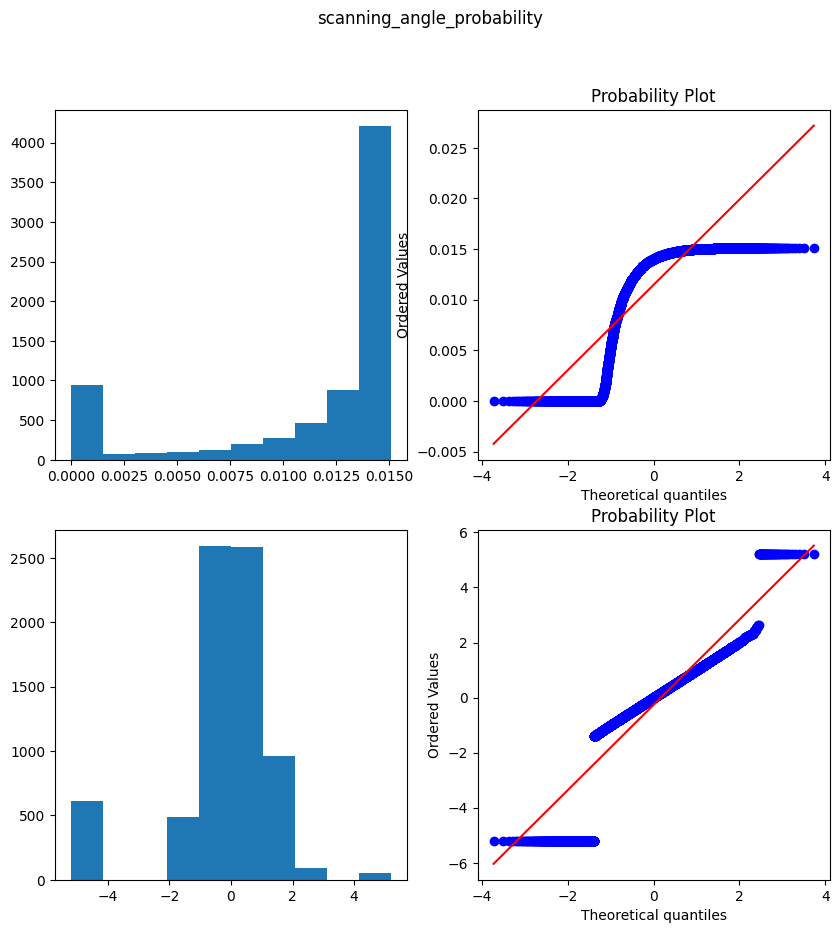

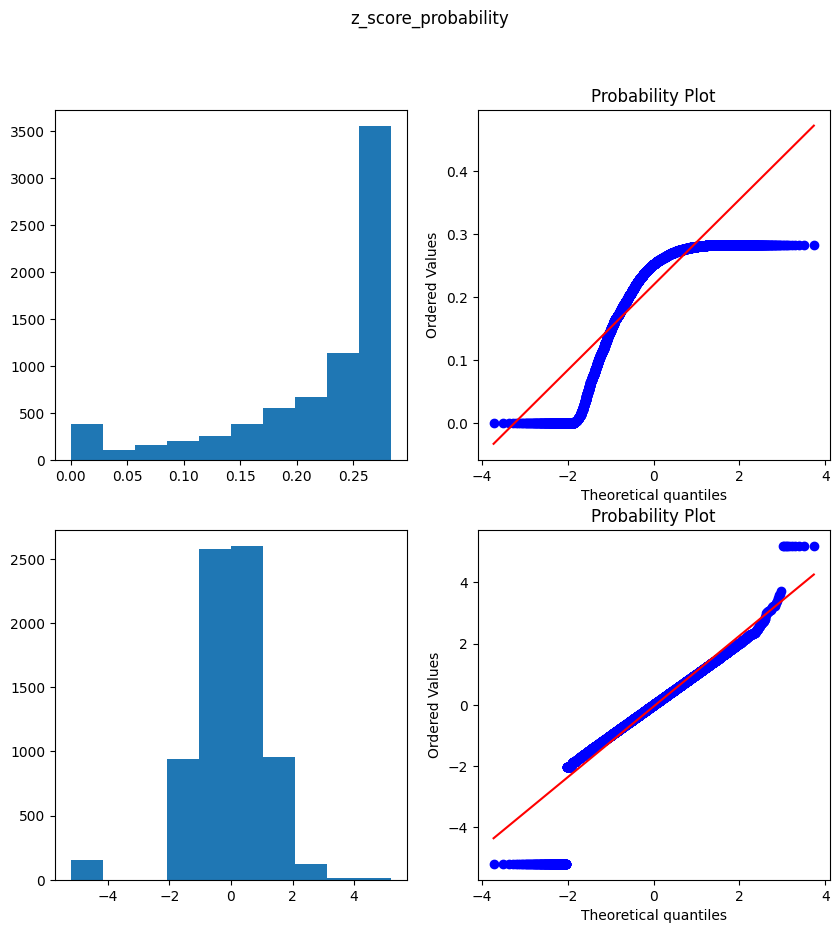

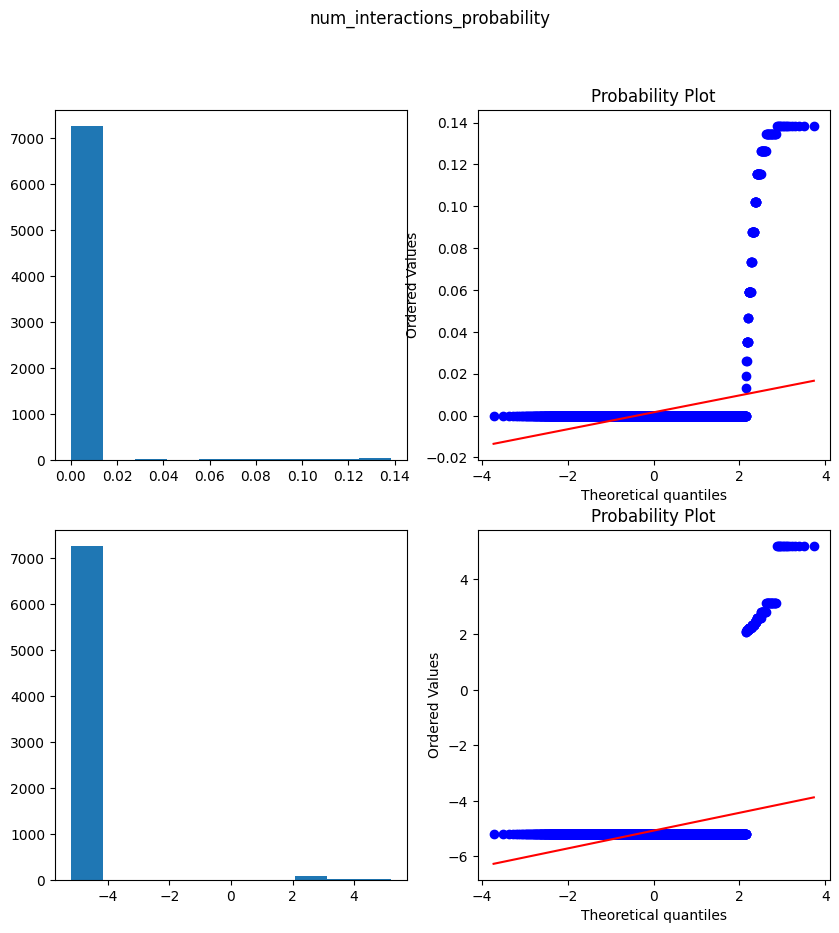

In [36]:
for selected_column in ('scanning_angle_probability', 'z_score_probability', 'num_interactions_probability'):
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))

    fig.suptitle(selected_column)
    x = structure_scores[selected_column].to_numpy()

    qt = sklearn.preprocessing.QuantileTransformer(output_distribution='normal', n_quantiles=100)
    x_transformed = qt.fit_transform(x.reshape(-1, 1)).squeeze()

    structure_scores[selected_column + '_transformed'] = x_transformed

    axes[0, 0].hist(x)
    scipy.stats.probplot(x, dist=scipy.stats.norm, plot=axes[0, 1])

    axes[1, 0].hist(x_transformed)
    scipy.stats.probplot(x_transformed, dist=scipy.stats.norm, plot=axes[1, 1])

    structure_probability_names = [
        column if column != selected_column else selected_column + '_transformed'
        for column in structure_probability_names
    ]

    plt.show()

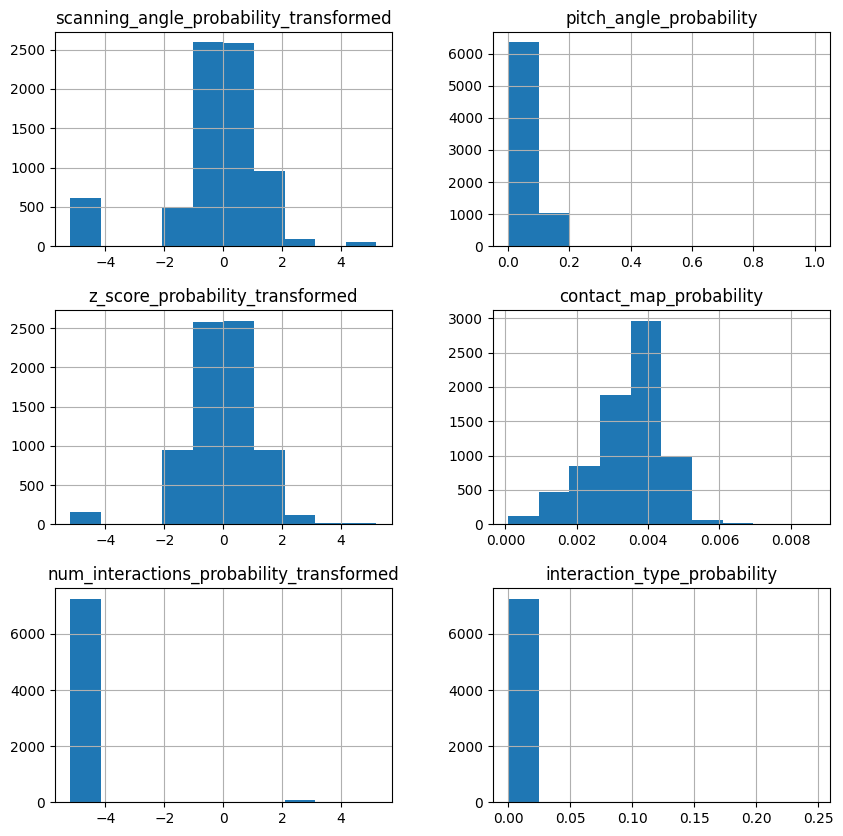

In [37]:
structure_scores[structure_probability_names].hist(figsize=(10, 10))
plt.show()

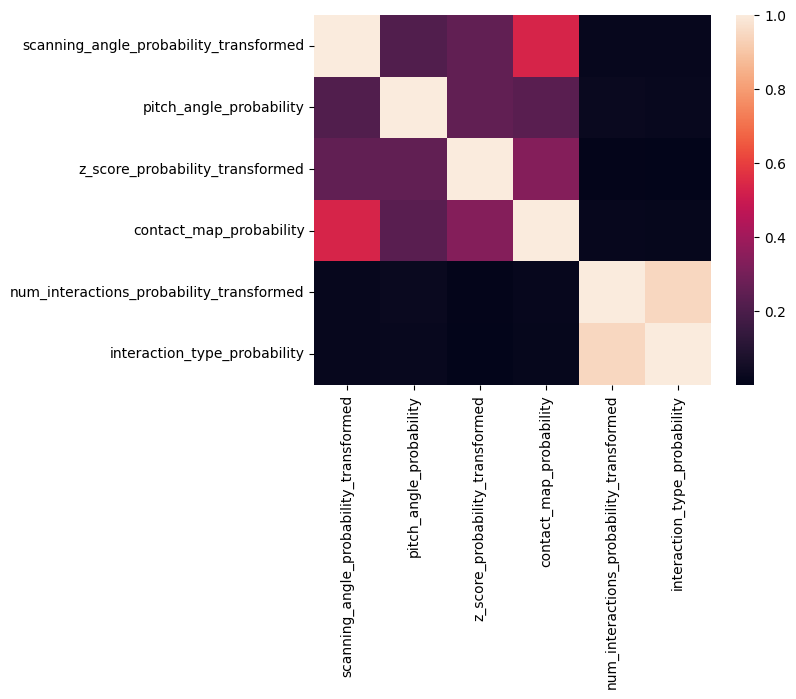

In [38]:
sns.heatmap(structure_scores[structure_probability_names].corr())

plt.show()

In [39]:
structure_probability_names = [
    column for column in structure_probability_names if column not in {'scanning_angle_probability_transformed'}
]

Skipping alpha_chain_alpha_chain_pae_min
alpha_chain_antigen_chain_pae_min
Pearson's correlation: 0.37
                                    OLS Regression Results                                   
Dep. Variable:     alpha_chain_antigen_chain_pae_min   R-squared:                       0.137
Model:                                           OLS   Adj. R-squared:                  0.136
Method:                                Least Squares   F-statistic:                     233.7
Date:                               Wed, 24 Sep 2025   Prob (F-statistic):          2.33e-232
Time:                                       12:33:15   Log-Likelihood:                -21190.
No. Observations:                               7375   AIC:                         4.239e+04
Df Residuals:                                   7369   BIC:                         4.243e+04
Df Model:                                          5                                         
Covariance Type:                           nonrobus

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-7.464053,1.217601,-6.130132,4.616619e-10,True
z_score_probability_transformed,-0.620117,0.044400,-13.966562,4.491730e-44,True
contact_map_probability,-1149.410461,53.396692,-21.525874,5.000021e-100,True
num_interactions_probability_transformed,-0.140501,0.156157,-0.899744,1.841430e-01,False
interaction_type_probability,1.770377,8.230865,0.215090,5.851485e-01,False


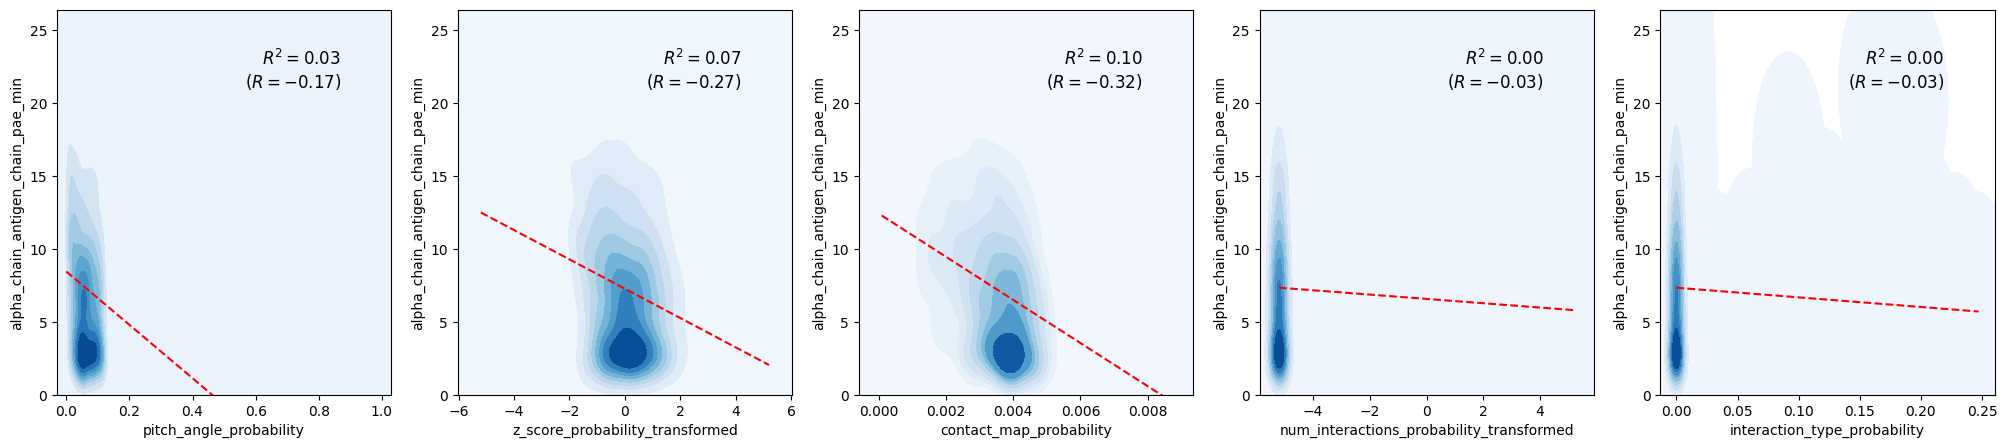

alpha_chain_beta_chain_pae_min
Pearson's correlation: 0.07
                                  OLS Regression Results                                  
Dep. Variable:     alpha_chain_beta_chain_pae_min   R-squared:                       0.005
Model:                                        OLS   Adj. R-squared:                  0.004
Method:                             Least Squares   F-statistic:                     7.482
Date:                            Wed, 24 Sep 2025   Prob (F-statistic):           5.16e-07
Time:                                    12:33:34   Log-Likelihood:                 5253.9
No. Observations:                            7375   AIC:                        -1.050e+04
Df Residuals:                                7369   BIC:                        -1.045e+04
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.004397,0.033753,-0.130285,0.448172,False
z_score_probability_transformed,0.005664,0.001231,4.601730,0.999998,False
contact_map_probability,-2.706820,1.480200,-1.828686,0.033744,True
num_interactions_probability_transformed,-0.012044,0.004329,-2.782280,0.002706,True
interaction_type_probability,0.398016,0.228166,1.744414,0.959436,False


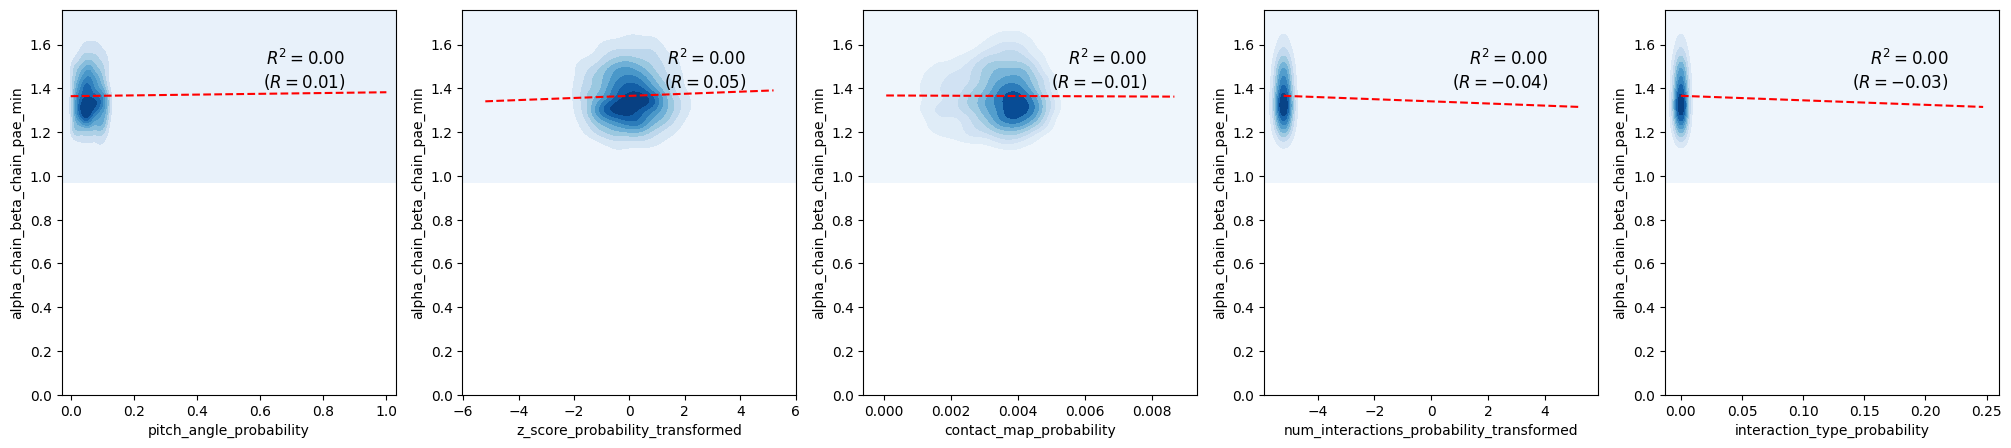

alpha_chain_mhc_chain_1_pae_min
Pearson's correlation: 0.35
                                   OLS Regression Results                                  
Dep. Variable:     alpha_chain_mhc_chain_1_pae_min   R-squared:                       0.125
Model:                                         OLS   Adj. R-squared:                  0.124
Method:                              Least Squares   F-statistic:                     210.0
Date:                             Wed, 24 Sep 2025   Prob (F-statistic):          5.29e-210
Time:                                     12:33:52   Log-Likelihood:                -20660.
No. Observations:                             7375   AIC:                         4.133e+04
Df Residuals:                                 7369   BIC:                         4.137e+04
Df Model:                                        5                                         
Covariance Type:                         nonrobust                                         
                    

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-6.494505,1.133246,-5.730888,5.192329e-09,True
z_score_probability_transformed,-0.478445,0.041324,-11.577873,4.915984e-31,True
contact_map_probability,-1080.337535,49.697390,-21.738315,6.581574e-102,True
num_interactions_probability_transformed,-0.095069,0.145339,-0.654119,2.565277e-01,False
interaction_type_probability,-0.738102,7.660634,-0.096350,4.616226e-01,False


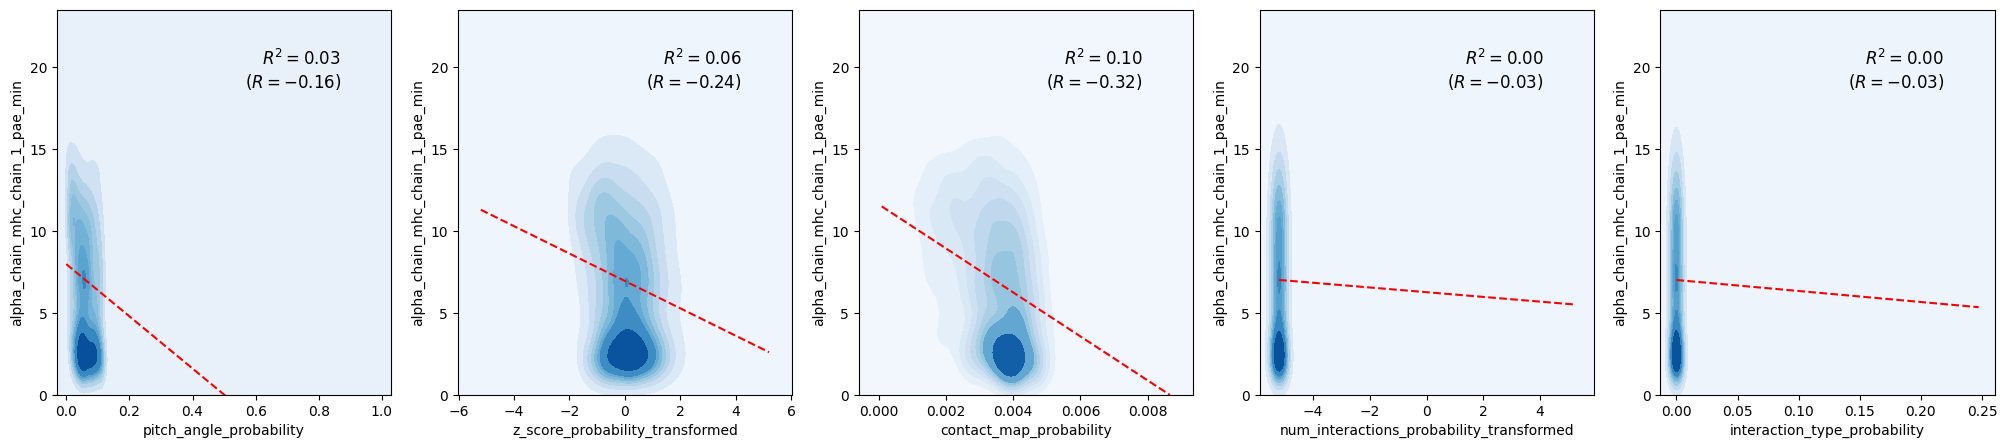

alpha_chain_mhc_chain_2_pae_min
Pearson's correlation: 0.38
                                   OLS Regression Results                                  
Dep. Variable:     alpha_chain_mhc_chain_2_pae_min   R-squared:                       0.145
Model:                                         OLS   Adj. R-squared:                  0.145
Method:                              Least Squares   F-statistic:                     250.2
Date:                             Wed, 24 Sep 2025   Prob (F-statistic):          1.23e-247
Time:                                     12:34:11   Log-Likelihood:                -19817.
No. Observations:                             7375   AIC:                         3.965e+04
Df Residuals:                                 7369   BIC:                         3.969e+04
Df Model:                                        5                                         
Covariance Type:                         nonrobust                                         
                    

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-7.333051,1.010846,-7.254372,2.223250e-13,True
z_score_probability_transformed,-0.453032,0.036861,-12.290364,1.106152e-34,True
contact_map_probability,-1042.442274,44.329645,-23.515692,2.862883e-118,True
num_interactions_probability_transformed,-0.121996,0.129641,-0.941034,1.733591e-01,False
interaction_type_probability,2.042337,6.833220,0.298884,6.174813e-01,False


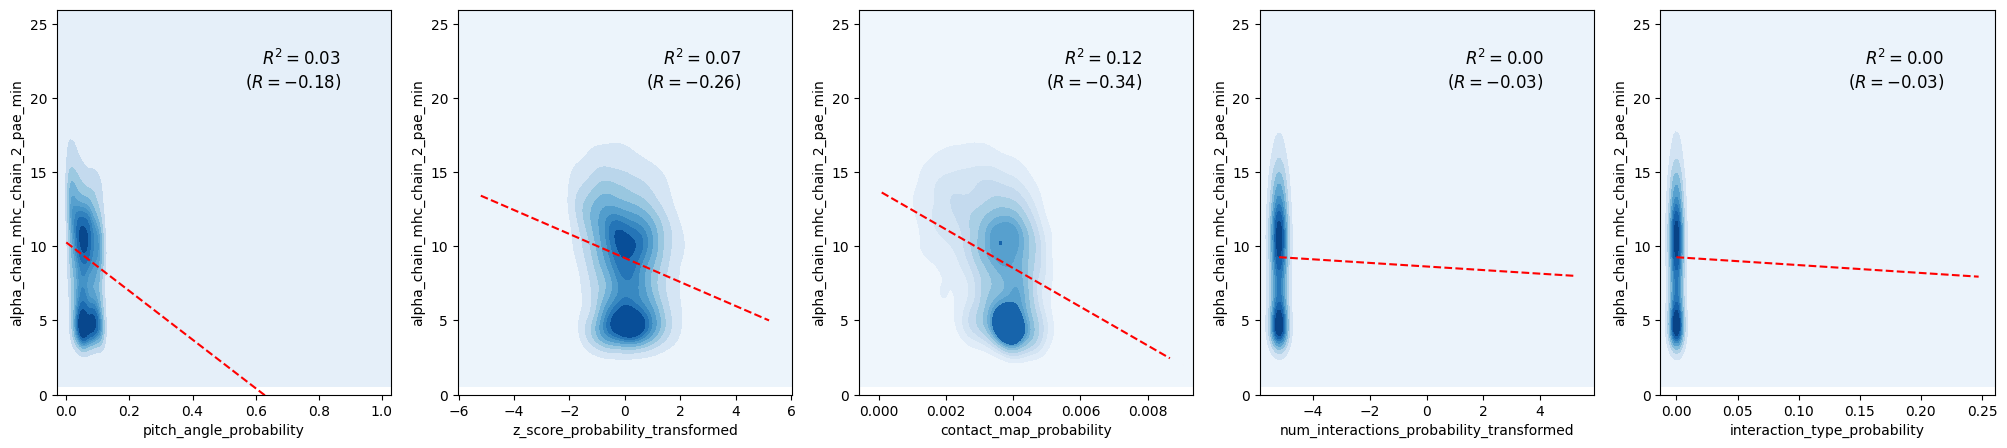

antigen_chain_alpha_chain_pae_min
Pearson's correlation: 0.38
                                    OLS Regression Results                                   
Dep. Variable:     antigen_chain_alpha_chain_pae_min   R-squared:                       0.144
Model:                                           OLS   Adj. R-squared:                  0.143
Method:                                Least Squares   F-statistic:                     247.2
Date:                               Wed, 24 Sep 2025   Prob (F-statistic):          6.45e-245
Time:                                       12:34:29   Log-Likelihood:                -22837.
No. Observations:                               7375   AIC:                         4.569e+04
Df Residuals:                                   7369   BIC:                         4.573e+04
Df Model:                                          5                                         
Covariance Type:                           nonrobust                                        

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-9.424505,1.522424,-6.190461,3.160201e-10,True
z_score_probability_transformed,-0.872325,0.055516,-15.713161,4.723577e-55,True
contact_map_probability,-1404.520932,66.764400,-21.036974,9.231636e-96,True
num_interactions_probability_transformed,-0.175102,0.195251,-0.896806,1.849259e-01,False
interaction_type_probability,1.595342,10.291439,0.155016,5.615937e-01,False


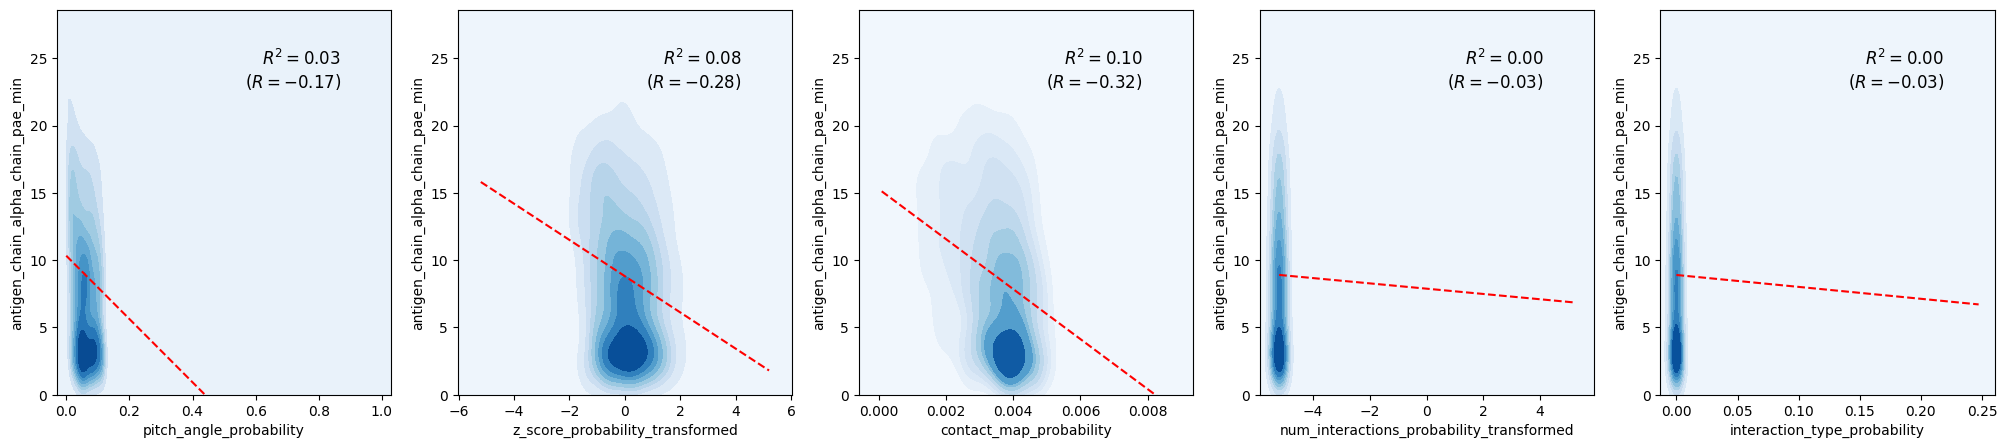

Skipping antigen_chain_antigen_chain_pae_min
antigen_chain_beta_chain_pae_min
Pearson's correlation: 0.37
                                   OLS Regression Results                                   
Dep. Variable:     antigen_chain_beta_chain_pae_min   R-squared:                       0.138
Model:                                          OLS   Adj. R-squared:                  0.138
Method:                               Least Squares   F-statistic:                     236.1
Date:                              Wed, 24 Sep 2025   Prob (F-statistic):          1.37e-234
Time:                                      12:34:48   Log-Likelihood:                -22407.
No. Observations:                              7375   AIC:                         4.483e+04
Df Residuals:                                  7369   BIC:                         4.487e+04
Df Model:                                         5                                         
Covariance Type:                          nonrobust      

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-7.339227,1.436057,-5.110679,1.645372e-07,True
z_score_probability_transformed,-0.758850,0.052366,-14.491211,3.031242e-47,True
contact_map_probability,-1377.551599,62.976879,-21.873926,4.068016e-103,True
num_interactions_probability_transformed,-0.055596,0.184174,-0.301865,3.813818e-01,False
interaction_type_probability,-0.537803,9.707609,-0.055400,4.779106e-01,False


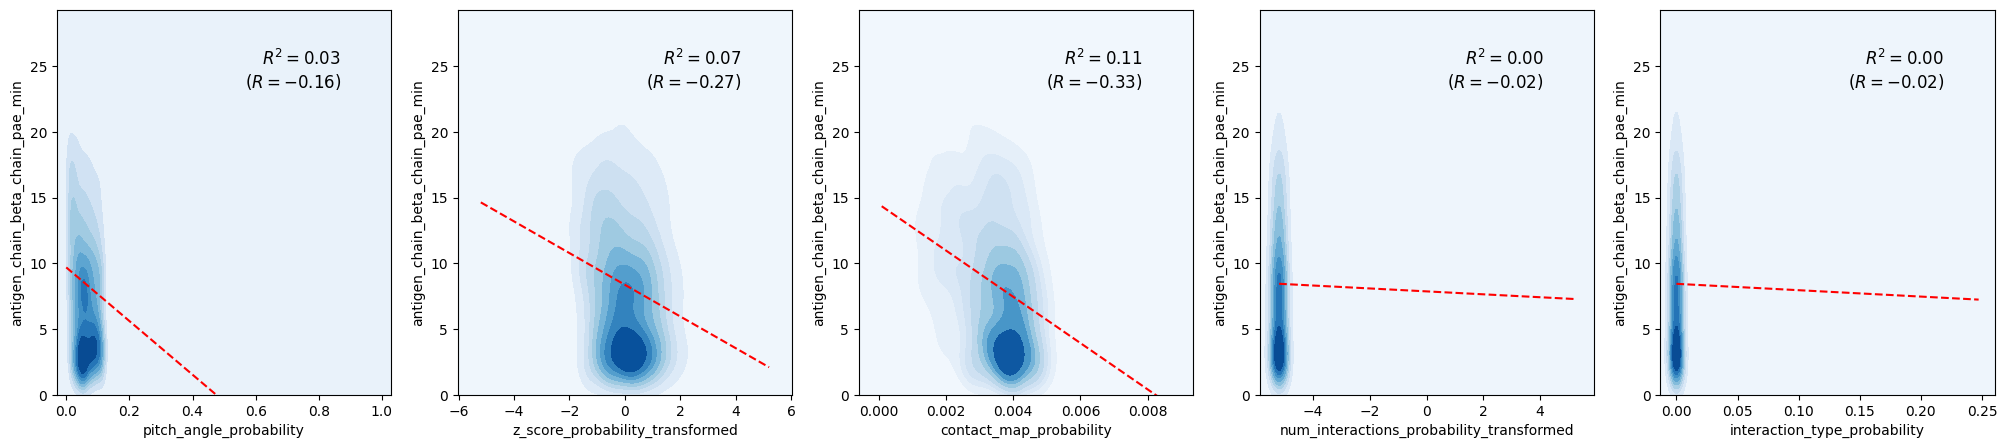

antigen_chain_mhc_chain_1_pae_min
Pearson's correlation: 0.05
                                    OLS Regression Results                                   
Dep. Variable:     antigen_chain_mhc_chain_1_pae_min   R-squared:                       0.003
Model:                                           OLS   Adj. R-squared:                  0.002
Method:                                Least Squares   F-statistic:                     4.030
Date:                               Wed, 24 Sep 2025   Prob (F-statistic):            0.00118
Time:                                       12:35:06   Log-Likelihood:                -4761.8
No. Observations:                               7375   AIC:                             9536.
Df Residuals:                                   7369   BIC:                             9577.
Df Model:                                          5                                         
Covariance Type:                           nonrobust                                        

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.239702,0.131254,1.826253,0.966074,False
z_score_probability_transformed,-0.011485,0.004786,-2.399619,0.008218,True
contact_map_probability,-7.011258,5.755996,-1.218079,0.111616,False
num_interactions_probability_transformed,-0.013383,0.016833,-0.795009,0.213317,False
interaction_type_probability,1.493793,0.887261,1.683600,0.953849,False


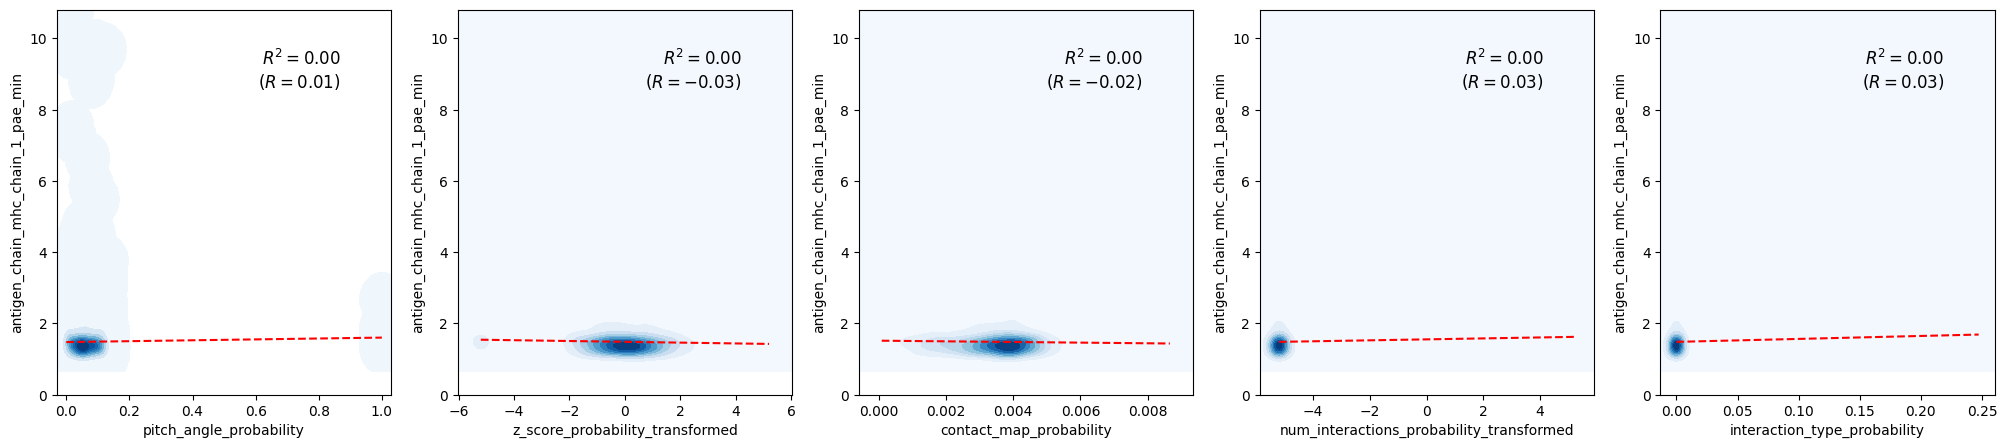

antigen_chain_mhc_chain_2_pae_min
Pearson's correlation: 0.05
                                    OLS Regression Results                                   
Dep. Variable:     antigen_chain_mhc_chain_2_pae_min   R-squared:                       0.003
Model:                                           OLS   Adj. R-squared:                  0.002
Method:                                Least Squares   F-statistic:                     3.937
Date:                               Wed, 24 Sep 2025   Prob (F-statistic):            0.00144
Time:                                       12:35:31   Log-Likelihood:                -10065.
No. Observations:                               7375   AIC:                         2.014e+04
Df Residuals:                                   7369   BIC:                         2.018e+04
Df Model:                                          5                                         
Covariance Type:                           nonrobust                                        

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.516200,0.269414,1.916010,0.972299,False
z_score_probability_transformed,-0.009582,0.009824,-0.975320,0.164717,False
contact_map_probability,-30.521458,11.814898,-2.583303,0.004903,True
num_interactions_probability_transformed,-0.046879,0.034552,-1.356740,0.087453,False
interaction_type_probability,3.816497,1.821215,2.095578,0.981923,False


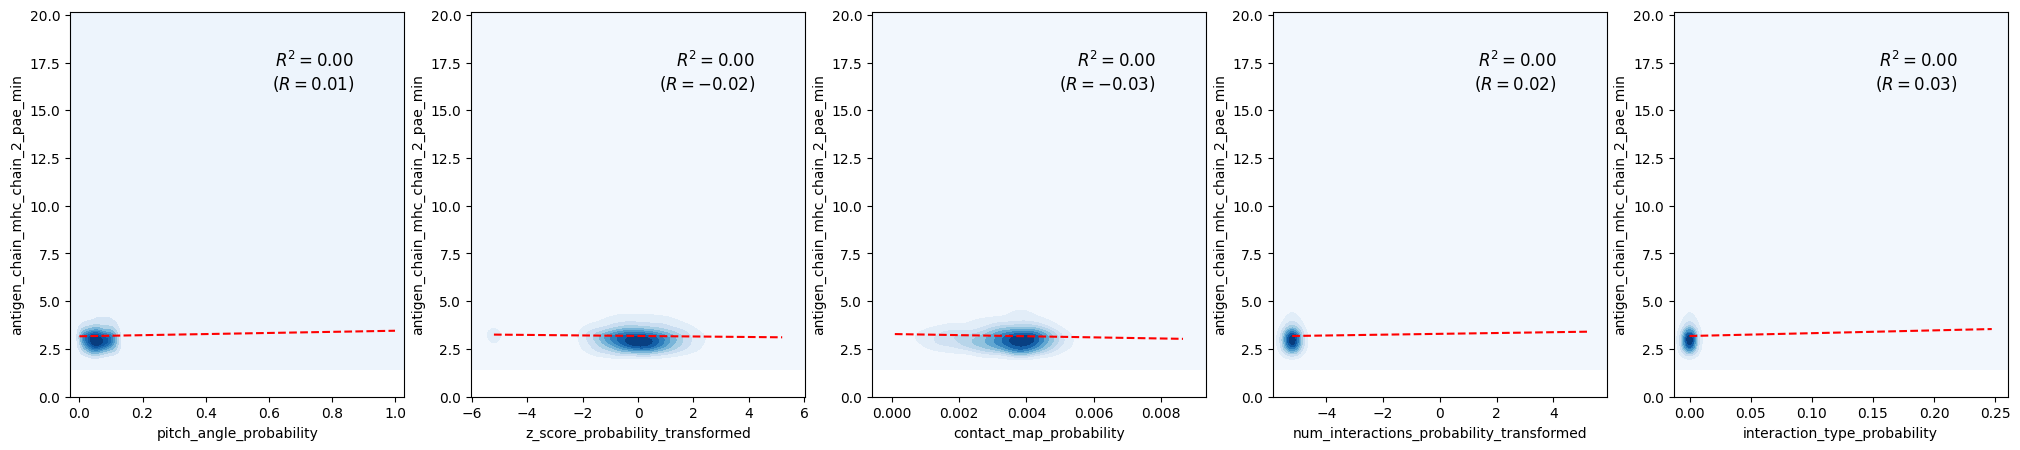

beta_chain_alpha_chain_pae_min
Pearson's correlation: 0.08
                                  OLS Regression Results                                  
Dep. Variable:     beta_chain_alpha_chain_pae_min   R-squared:                       0.006
Model:                                        OLS   Adj. R-squared:                  0.005
Method:                             Least Squares   F-statistic:                     8.509
Date:                            Wed, 24 Sep 2025   Prob (F-statistic):           4.82e-08
Time:                                    12:35:55   Log-Likelihood:                 5924.7
No. Observations:                            7375   AIC:                        -1.184e+04
Df Residuals:                                7369   BIC:                        -1.180e+04
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.029912,0.030818,0.970587,0.834107,False
z_score_probability_transformed,0.005832,0.001124,5.189512,1.000000,False
contact_map_probability,-4.212048,1.351507,-3.116556,0.000918,True
num_interactions_probability_transformed,-0.009821,0.003952,-2.484874,0.006491,True
interaction_type_probability,0.357130,0.208329,1.714259,0.956738,False


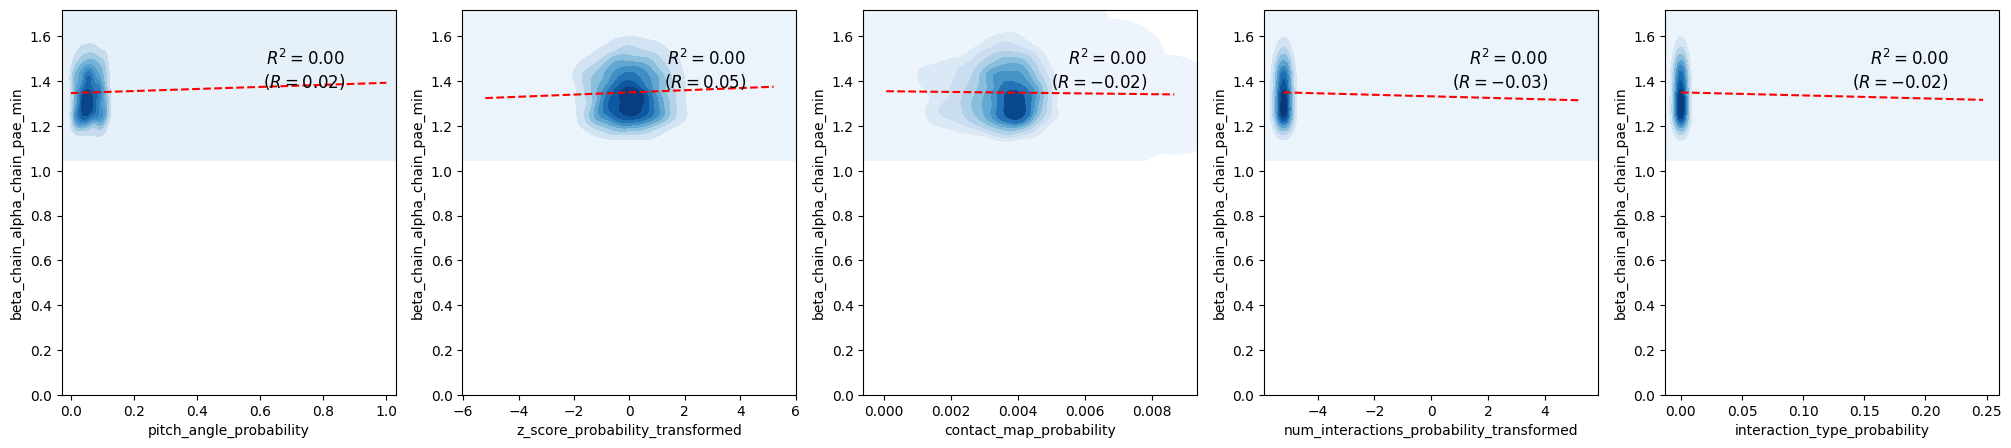

beta_chain_antigen_chain_pae_min
Pearson's correlation: 0.36
                                   OLS Regression Results                                   
Dep. Variable:     beta_chain_antigen_chain_pae_min   R-squared:                       0.133
Model:                                          OLS   Adj. R-squared:                  0.133
Method:                               Least Squares   F-statistic:                     226.5
Date:                              Wed, 24 Sep 2025   Prob (F-statistic):          1.38e-225
Time:                                      12:36:14   Log-Likelihood:                -21101.
No. Observations:                              7375   AIC:                         4.221e+04
Df Residuals:                                  7369   BIC:                         4.226e+04
Df Model:                                         5                                         
Covariance Type:                          nonrobust                                         
         

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-6.607601,1.203107,-5.492115,2.051956e-08,True
z_score_probability_transformed,-0.622397,0.043872,-14.186779,2.161923e-45,True
contact_map_probability,-1115.301053,52.761071,-21.138711,1.215049e-96,True
num_interactions_probability_transformed,-0.097083,0.154298,-0.629188,2.646227e-01,False
interaction_type_probability,0.558389,8.132887,0.068658,5.273682e-01,False


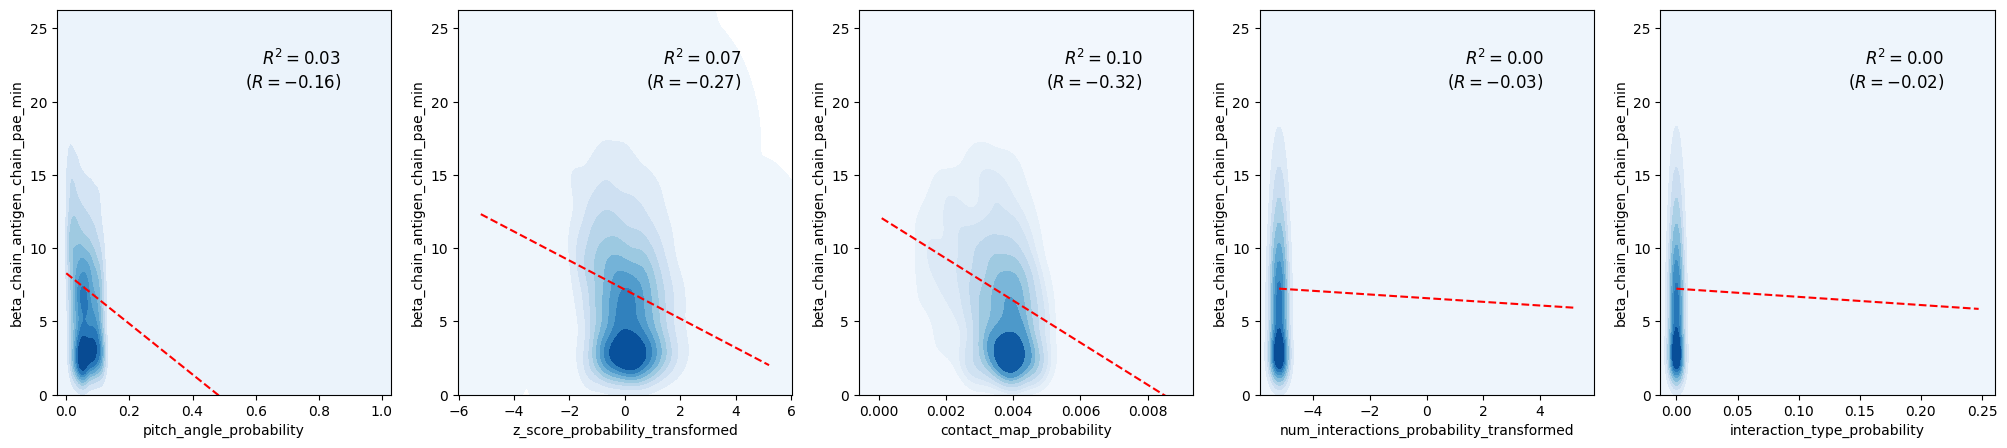

Skipping beta_chain_beta_chain_pae_min
beta_chain_mhc_chain_1_pae_min
Pearson's correlation: 0.35
                                  OLS Regression Results                                  
Dep. Variable:     beta_chain_mhc_chain_1_pae_min   R-squared:                       0.123
Model:                                        OLS   Adj. R-squared:                  0.122
Method:                             Least Squares   F-statistic:                     206.7
Date:                            Wed, 24 Sep 2025   Prob (F-statistic):          7.70e-207
Time:                                    12:36:32   Log-Likelihood:                -20560.
No. Observations:                            7375   AIC:                         4.113e+04
Df Residuals:                                7369   BIC:                         4.117e+04
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-5.332102,1.117992,-4.769356,9.418381e-07,True
z_score_probability_transformed,-0.485072,0.040768,-11.898389,1.191808e-32,True
contact_map_probability,-1064.537107,49.028449,-21.712641,1.112949e-101,True
num_interactions_probability_transformed,-0.060438,0.143382,-0.421515,3.366958e-01,False
interaction_type_probability,-2.041882,7.557520,-0.270179,3.935151e-01,False


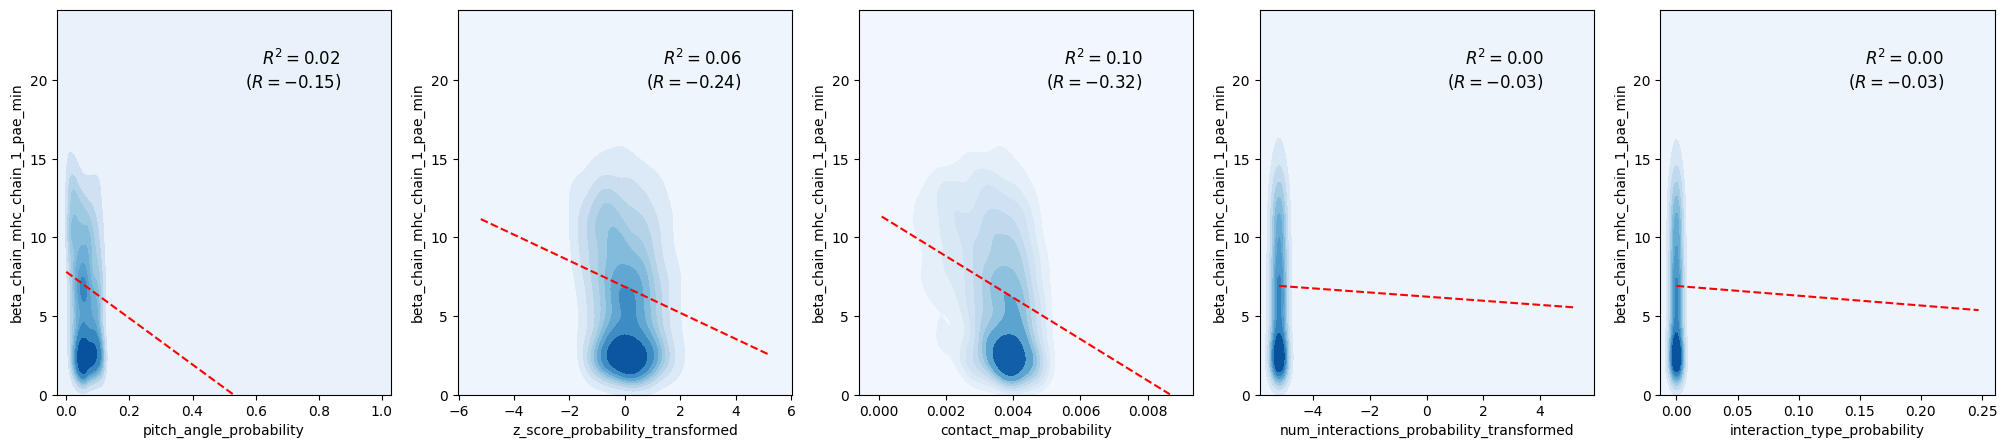

beta_chain_mhc_chain_2_pae_min
Pearson's correlation: 0.37
                                  OLS Regression Results                                  
Dep. Variable:     beta_chain_mhc_chain_2_pae_min   R-squared:                       0.137
Model:                                        OLS   Adj. R-squared:                  0.137
Method:                             Least Squares   F-statistic:                     234.2
Date:                            Wed, 24 Sep 2025   Prob (F-statistic):          9.36e-233
Time:                                    12:36:51   Log-Likelihood:                -19940.
No. Observations:                            7375   AIC:                         3.989e+04
Df Residuals:                                7369   BIC:                         3.993e+04
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-6.736600,1.027884,-6.553850,2.992576e-11,True
z_score_probability_transformed,-0.464624,0.037482,-12.395904,3.061485e-35,True
contact_map_probability,-1019.965628,45.076864,-22.627254,5.948839e-110,True
num_interactions_probability_transformed,-0.085708,0.131826,-0.650162,2.578038e-01,False
interaction_type_probability,0.465634,6.948400,0.067013,5.267135e-01,False


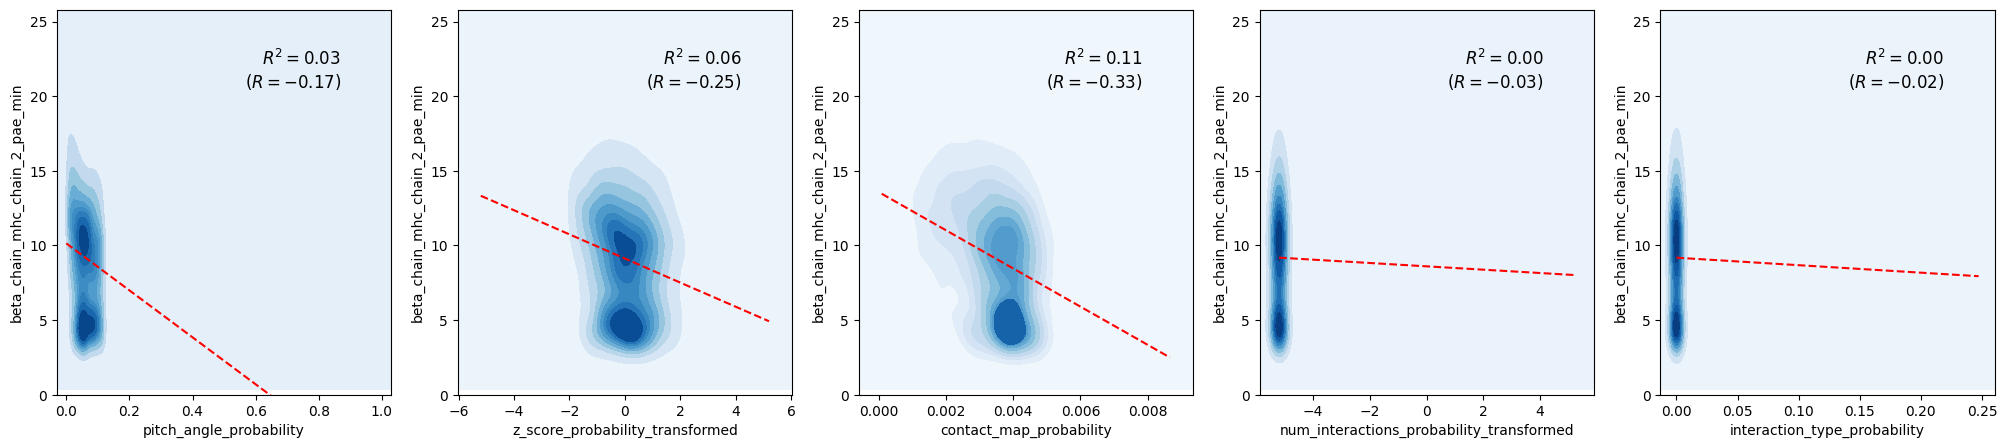

cdr_pmhc_pae_score
Pearson's correlation: 0.41
                            OLS Regression Results                            
Dep. Variable:     cdr_pmhc_pae_score   R-squared:                       0.168
Model:                            OLS   Adj. R-squared:                  0.167
Method:                 Least Squares   F-statistic:                     296.8
Date:                Wed, 24 Sep 2025   Prob (F-statistic):          3.23e-290
Time:                        12:37:09   Log-Likelihood:                -22597.
No. Observations:                7375   AIC:                         4.521e+04
Df Residuals:                    7369   BIC:                         4.525e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-9.523497,1.473533,-6.463037,5.458062e-11,True
z_score_probability_transformed,-0.762061,0.053733,-14.182425,2.296553e-45,True
contact_map_probability,-1661.250394,64.620341,-25.707855,5.920823e-140,True
num_interactions_probability_transformed,-0.143285,0.188980,-0.758199,2.241780e-01,False
interaction_type_probability,-0.874105,9.960941,-0.087753,4.650376e-01,False


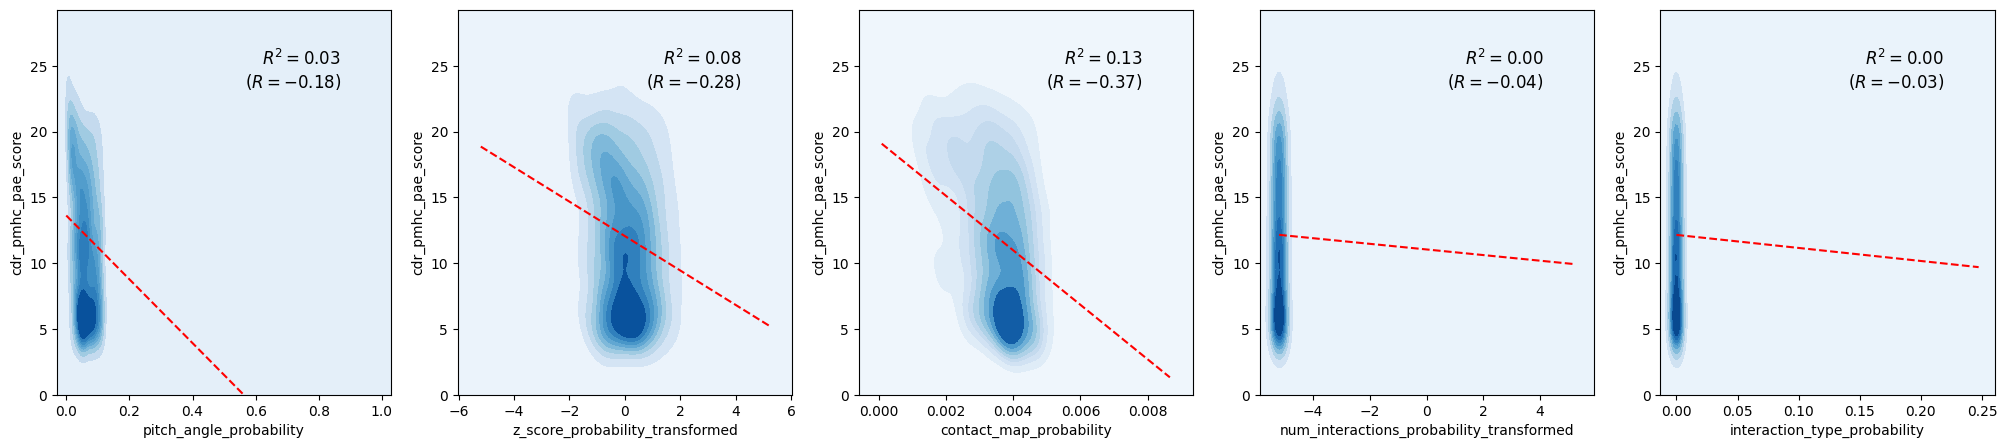

combined_pae_min
Pearson's correlation: 0.37
                            OLS Regression Results                            
Dep. Variable:       combined_pae_min   R-squared:                       0.138
Model:                            OLS   Adj. R-squared:                  0.138
Method:                 Least Squares   F-statistic:                     236.8
Date:                Wed, 24 Sep 2025   Prob (F-statistic):          3.33e-235
Time:                        12:37:28   Log-Likelihood:                -18607.
No. Observations:                7375   AIC:                         3.723e+04
Df Residuals:                    7369   BIC:                         3.727e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-4.992153,0.857876,-5.819201,3.080359e-09,True
z_score_probability_transformed,-0.449222,0.031283,-14.360098,1.924343e-46,True
contact_map_probability,-813.056961,37.621308,-21.611608,8.748989e-101,True
num_interactions_probability_transformed,-0.068872,0.110022,-0.625977,2.656748e-01,False
interaction_type_probability,-0.210568,5.799159,-0.036310,4.855180e-01,False


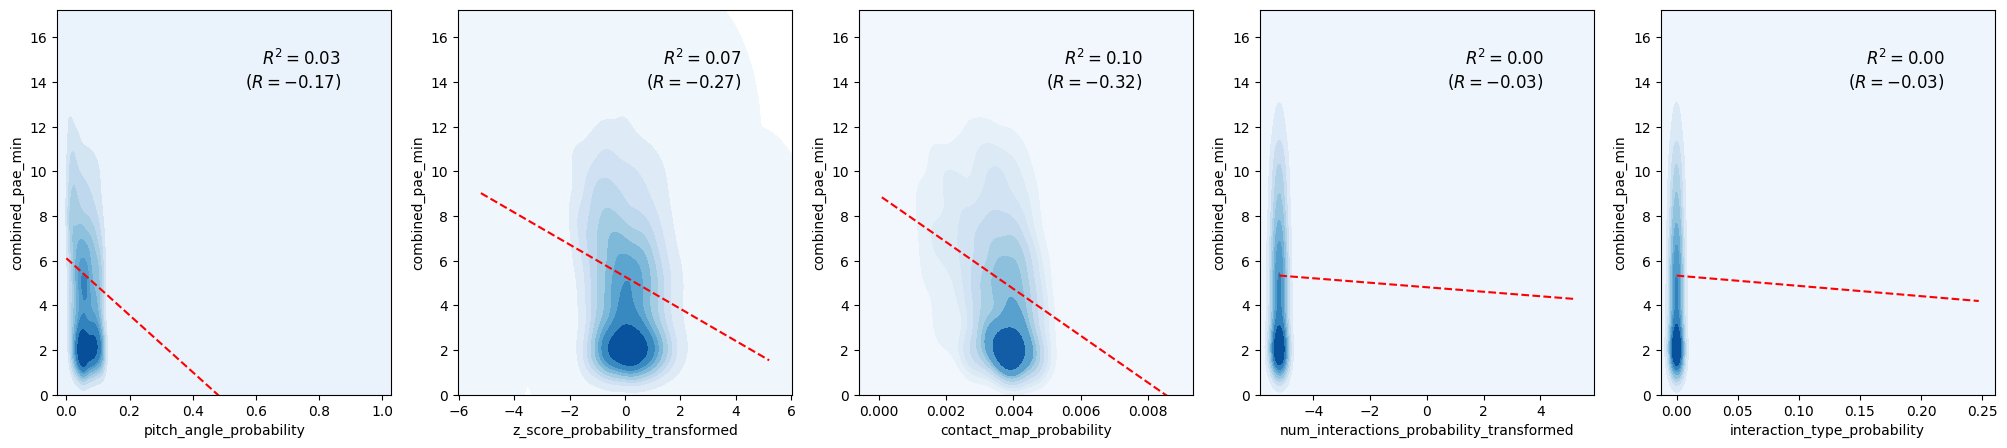

mhc_chain_1_alpha_chain_pae_min
Pearson's correlation: 0.38
                                   OLS Regression Results                                  
Dep. Variable:     mhc_chain_1_alpha_chain_pae_min   R-squared:                       0.143
Model:                                         OLS   Adj. R-squared:                  0.143
Method:                              Least Squares   F-statistic:                     246.5
Date:                             Wed, 24 Sep 2025   Prob (F-statistic):          2.90e-244
Time:                                     12:37:46   Log-Likelihood:                -22944.
No. Observations:                             7375   AIC:                         4.590e+04
Df Residuals:                                 7369   BIC:                         4.594e+04
Df Model:                                        5                                         
Covariance Type:                         nonrobust                                         
                    

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-9.850964,1.544560,-6.377847,9.522205e-11,True
z_score_probability_transformed,-0.880052,0.056323,-15.625144,1.804075e-54,True
contact_map_probability,-1419.070996,67.735150,-20.950289,5.160561e-95,True
num_interactions_probability_transformed,-0.128440,0.198090,-0.648391,2.583761e-01,False
interaction_type_probability,-1.734670,10.441075,-0.166139,4.340260e-01,False


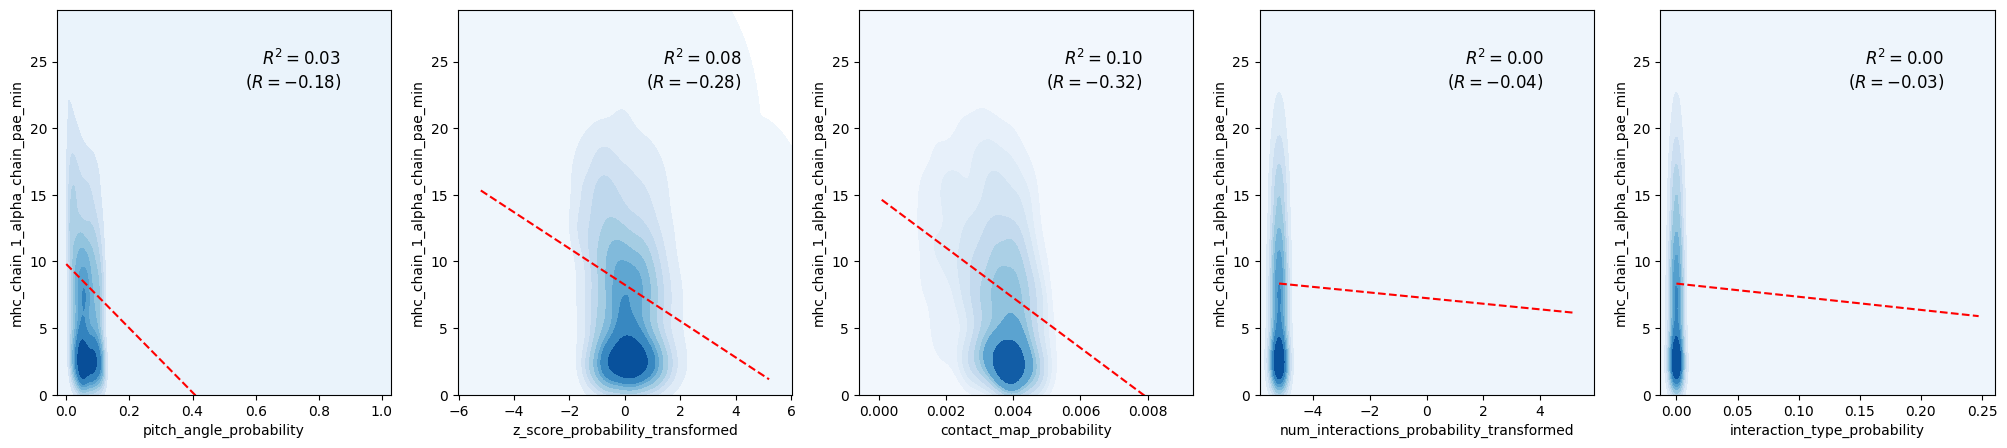

mhc_chain_1_antigen_chain_pae_min
Pearson's correlation: 0.04
                                    OLS Regression Results                                   
Dep. Variable:     mhc_chain_1_antigen_chain_pae_min   R-squared:                       0.002
Model:                                           OLS   Adj. R-squared:                  0.001
Method:                                Least Squares   F-statistic:                     2.327
Date:                               Wed, 24 Sep 2025   Prob (F-statistic):             0.0403
Time:                                       12:38:04   Log-Likelihood:                -2362.4
No. Observations:                               7375   AIC:                             4737.
Df Residuals:                                   7369   BIC:                             4778.
Df Model:                                          5                                         
Covariance Type:                           nonrobust                                        

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.126668,0.094802,1.336139,0.909228,False
z_score_probability_transformed,-0.002358,0.003457,-0.682121,0.247592,False
contact_map_probability,-10.410630,4.157437,-2.504098,0.006149,True
num_interactions_probability_transformed,-0.009099,0.012158,-0.748413,0.227118,False
interaction_type_probability,0.756347,0.640851,1.180223,0.881025,False


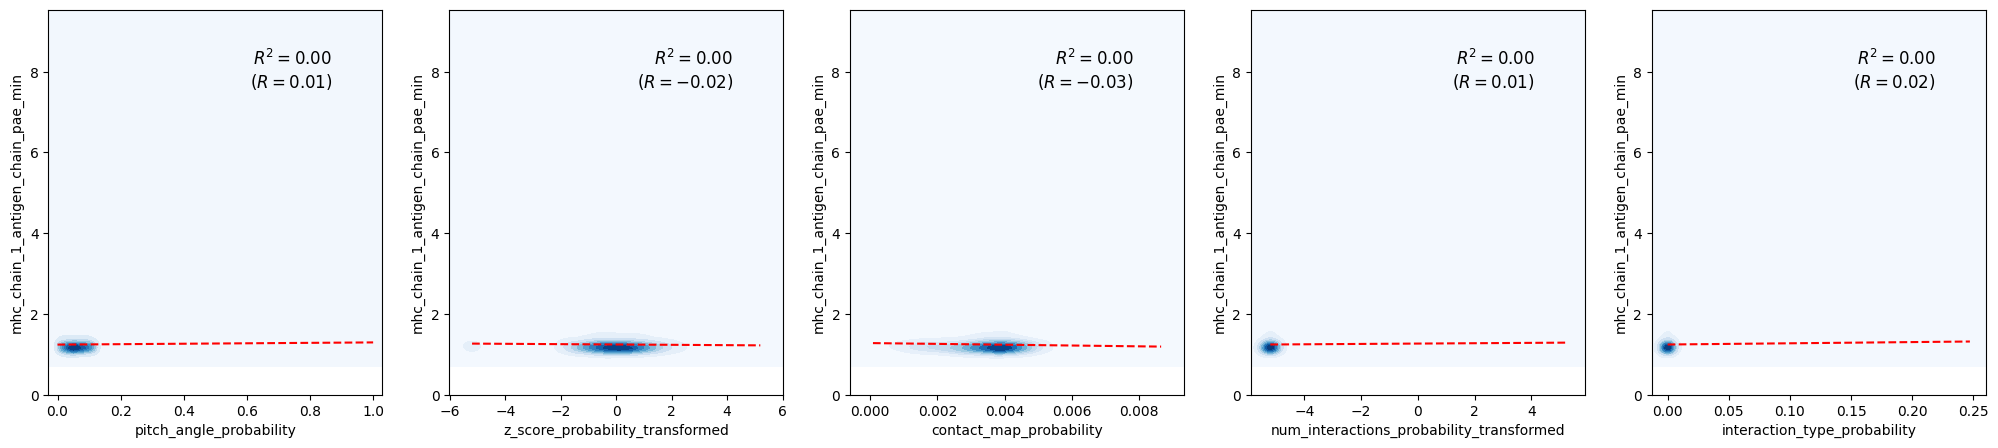

mhc_chain_1_beta_chain_pae_min
Pearson's correlation: 0.37
                                  OLS Regression Results                                  
Dep. Variable:     mhc_chain_1_beta_chain_pae_min   R-squared:                       0.138
Model:                                        OLS   Adj. R-squared:                  0.137
Method:                             Least Squares   F-statistic:                     235.4
Date:                            Wed, 24 Sep 2025   Prob (F-statistic):          6.47e-234
Time:                                    12:38:30   Log-Likelihood:                -22527.
No. Observations:                            7375   AIC:                         4.507e+04
Df Residuals:                                7369   BIC:                         4.511e+04
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-8.793889,1.459662,-6.024607,8.883748e-10,True
z_score_probability_transformed,-0.758672,0.053227,-14.253530,8.543751e-46,True
contact_map_probability,-1376.153430,64.012046,-21.498351,8.738457e-100,True
num_interactions_probability_transformed,-0.098492,0.187201,-0.526131,2.994066e-01,False
interaction_type_probability,-1.093880,9.867175,-0.110861,4.558650e-01,False


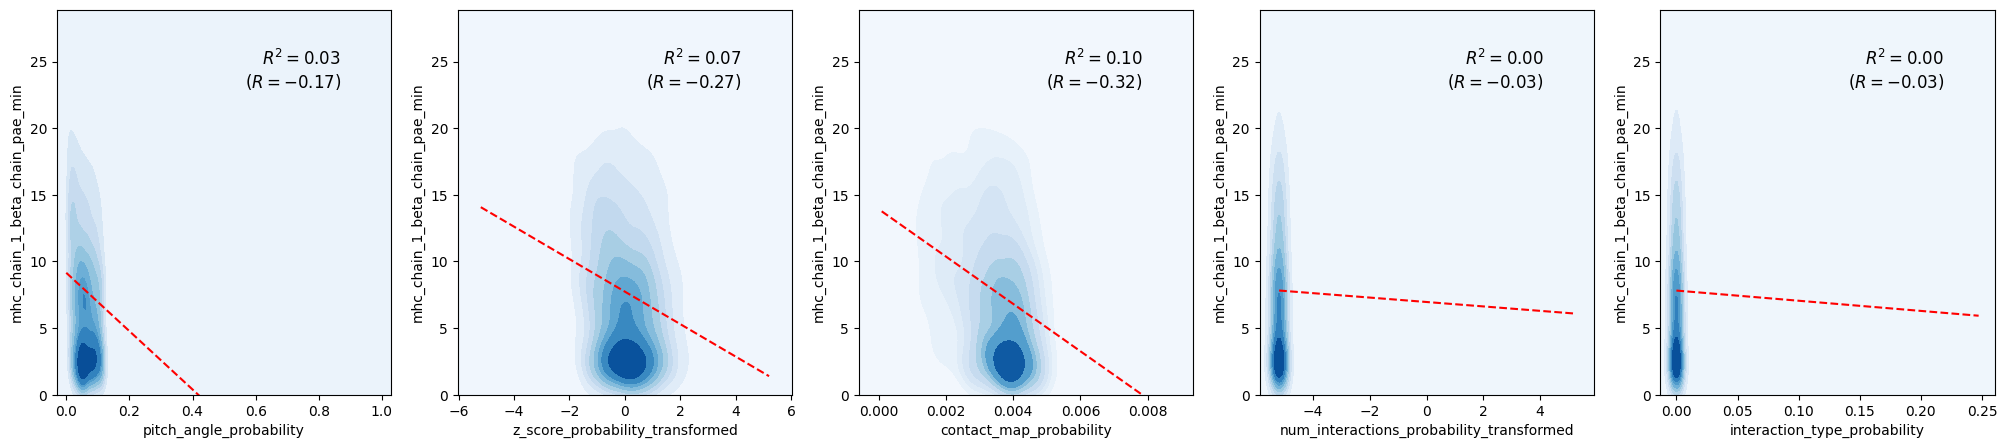

Skipping mhc_chain_1_mhc_chain_1_pae_min
mhc_chain_1_mhc_chain_2_pae_min
Pearson's correlation: 0.08
                                   OLS Regression Results                                  
Dep. Variable:     mhc_chain_1_mhc_chain_2_pae_min   R-squared:                       0.007
Model:                                         OLS   Adj. R-squared:                  0.006
Method:                              Least Squares   F-statistic:                     10.14
Date:                             Wed, 24 Sep 2025   Prob (F-statistic):           1.08e-09
Time:                                     12:38:48   Log-Likelihood:                 11525.
No. Observations:                             7375   AIC:                        -2.304e+04
Df Residuals:                                 7369   BIC:                        -2.300e+04
Df Model:                                        5                                         
Covariance Type:                         nonrobust                     

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.057765,0.014421,4.005508,0.999969,False
z_score_probability_transformed,0.001908,0.000526,3.628033,0.999856,False
contact_map_probability,0.545625,0.632432,0.862740,0.805846,False
num_interactions_probability_transformed,-0.002611,0.001850,-1.411949,0.079004,False
interaction_type_probability,0.076528,0.097487,0.785013,0.783764,False


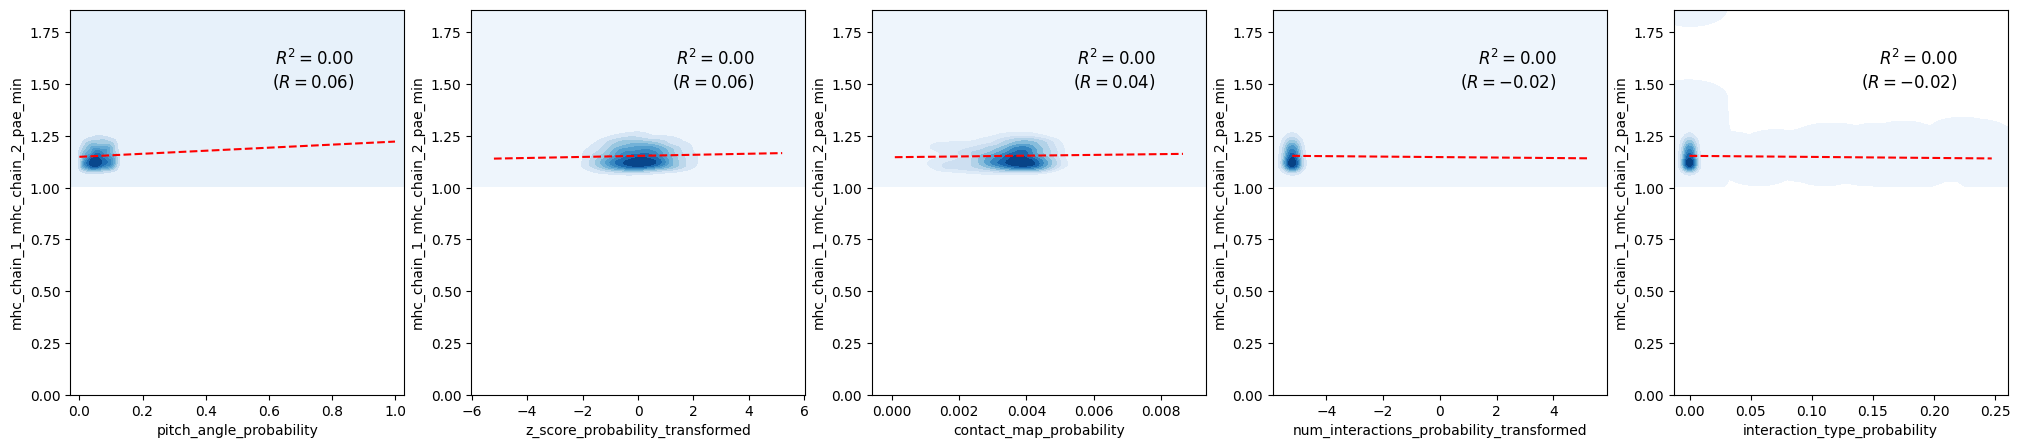

mhc_chain_2_alpha_chain_pae_min
Pearson's correlation: 0.39
                                   OLS Regression Results                                  
Dep. Variable:     mhc_chain_2_alpha_chain_pae_min   R-squared:                       0.149
Model:                                         OLS   Adj. R-squared:                  0.148
Method:                              Least Squares   F-statistic:                     258.2
Date:                             Wed, 24 Sep 2025   Prob (F-statistic):          5.14e-255
Time:                                     12:39:12   Log-Likelihood:                -22530.
No. Observations:                             7375   AIC:                         4.507e+04
Df Residuals:                                 7369   BIC:                         4.511e+04
Df Model:                                        5                                         
Covariance Type:                         nonrobust                                         
                    

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-9.446823,1.460362,-6.468822,5.254281e-11,True
z_score_probability_transformed,-0.843501,0.053252,-15.839652,6.801142e-56,True
contact_map_probability,-1383.370569,64.042753,-21.600735,1.091708e-100,True
num_interactions_probability_transformed,-0.125427,0.187291,-0.669691,2.515379e-01,False
interaction_type_probability,-1.605387,9.871909,-0.162622,4.354104e-01,False


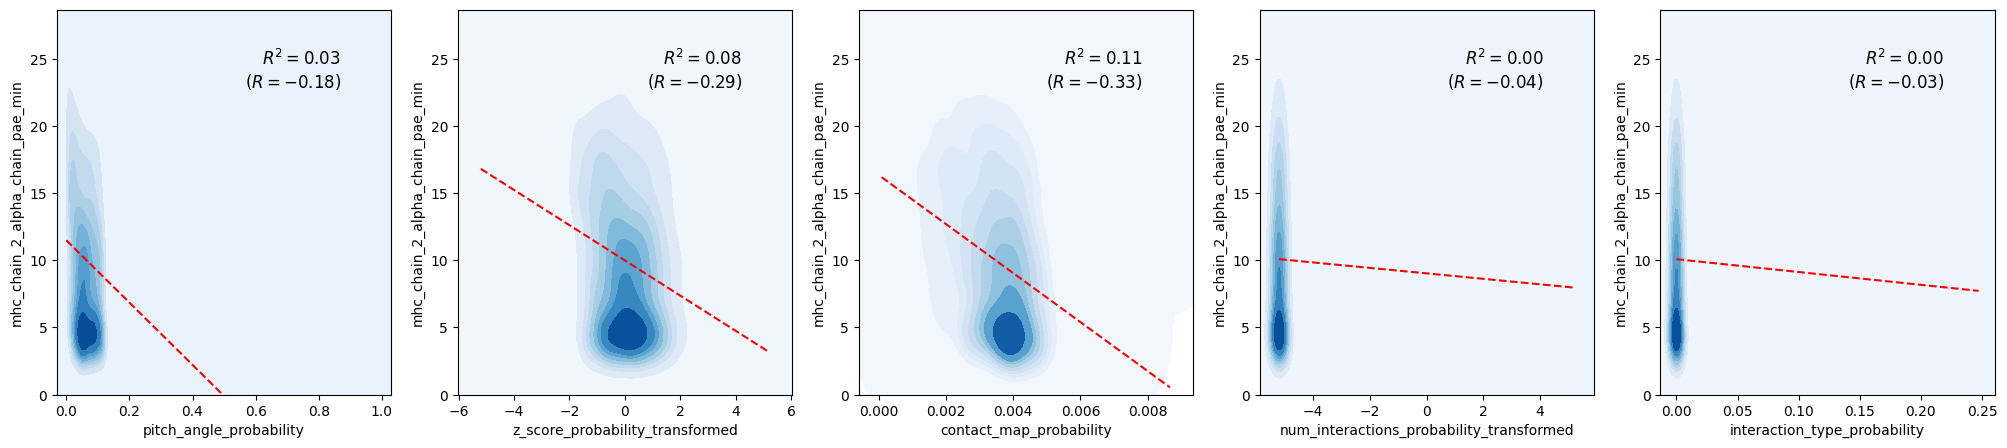

mhc_chain_2_antigen_chain_pae_min
Pearson's correlation: 0.04
                                    OLS Regression Results                                   
Dep. Variable:     mhc_chain_2_antigen_chain_pae_min   R-squared:                       0.001
Model:                                           OLS   Adj. R-squared:                  0.001
Method:                                Least Squares   F-statistic:                     1.996
Date:                               Wed, 24 Sep 2025   Prob (F-statistic):             0.0759
Time:                                       12:39:30   Log-Likelihood:                -2895.5
No. Observations:                               7375   AIC:                             5803.
Df Residuals:                                   7369   BIC:                             5845.
Df Model:                                          5                                         
Covariance Type:                           nonrobust                                        

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.228549,0.101909,2.242678,0.987526,False
z_score_probability_transformed,-0.006768,0.003716,-1.821149,0.034312,True
contact_map_probability,-4.790276,4.469123,-1.071860,0.141909,False
num_interactions_probability_transformed,-0.006359,0.013070,-0.486566,0.313290,False
interaction_type_probability,0.536977,0.688896,0.779475,0.782137,False


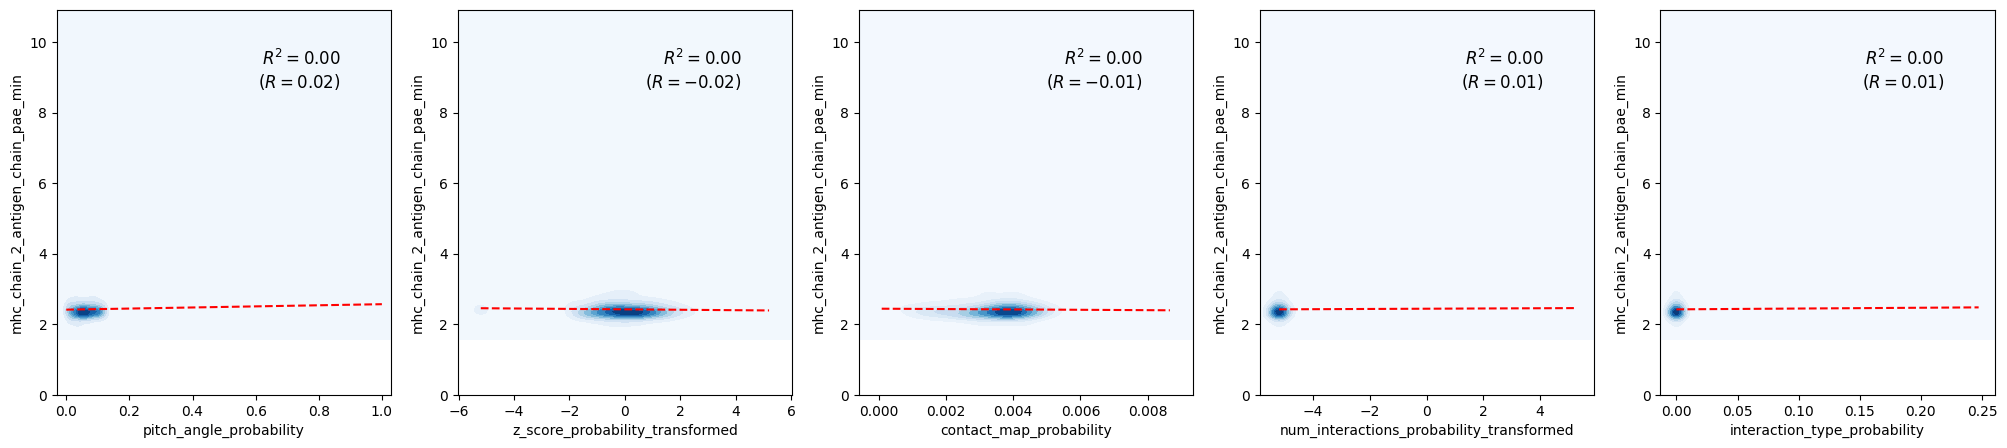

mhc_chain_2_beta_chain_pae_min
Pearson's correlation: 0.38
                                  OLS Regression Results                                  
Dep. Variable:     mhc_chain_2_beta_chain_pae_min   R-squared:                       0.146
Model:                                        OLS   Adj. R-squared:                  0.145
Method:                             Least Squares   F-statistic:                     251.8
Date:                            Wed, 24 Sep 2025   Prob (F-statistic):          3.98e-249
Time:                                    12:39:55   Log-Likelihood:                -22235.
No. Observations:                            7375   AIC:                         4.448e+04
Df Residuals:                                7369   BIC:                         4.452e+04
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-8.532398,1.402928,-6.081848,6.236929e-10,True
z_score_probability_transformed,-0.738291,0.051158,-14.431537,7.043423e-47,True
contact_map_probability,-1389.345773,61.524055,-22.582155,1.546194e-109,True
num_interactions_probability_transformed,-0.078333,0.179925,-0.435365,3.316553e-01,False
interaction_type_probability,-1.550850,9.483662,-0.163529,4.350534e-01,False


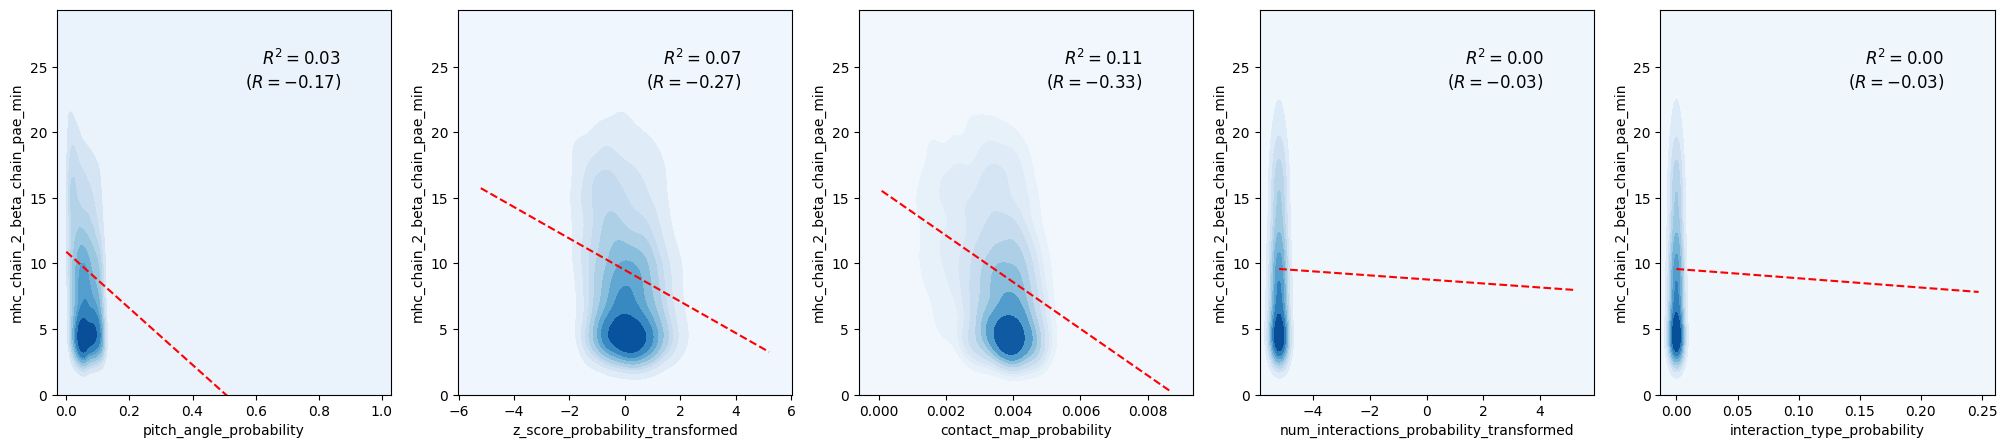

mhc_chain_2_mhc_chain_1_pae_min
Pearson's correlation: 0.08
                                   OLS Regression Results                                  
Dep. Variable:     mhc_chain_2_mhc_chain_1_pae_min   R-squared:                       0.007
Model:                                         OLS   Adj. R-squared:                  0.006
Method:                              Least Squares   F-statistic:                     10.18
Date:                             Wed, 24 Sep 2025   Prob (F-statistic):           9.69e-10
Time:                                     12:40:14   Log-Likelihood:                 11703.
No. Observations:                             7375   AIC:                        -2.339e+04
Df Residuals:                                 7369   BIC:                        -2.335e+04
Df Model:                                        5                                         
Covariance Type:                         nonrobust                                         
                    

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.094429,0.014078,6.707340,1.000000,False
z_score_probability_transformed,0.000198,0.000513,0.385973,0.650236,False
contact_map_probability,-0.089941,0.617395,-0.145679,0.442089,False
num_interactions_probability_transformed,-0.000736,0.001806,-0.407830,0.341705,False
interaction_type_probability,0.048267,0.095169,0.507177,0.693977,False


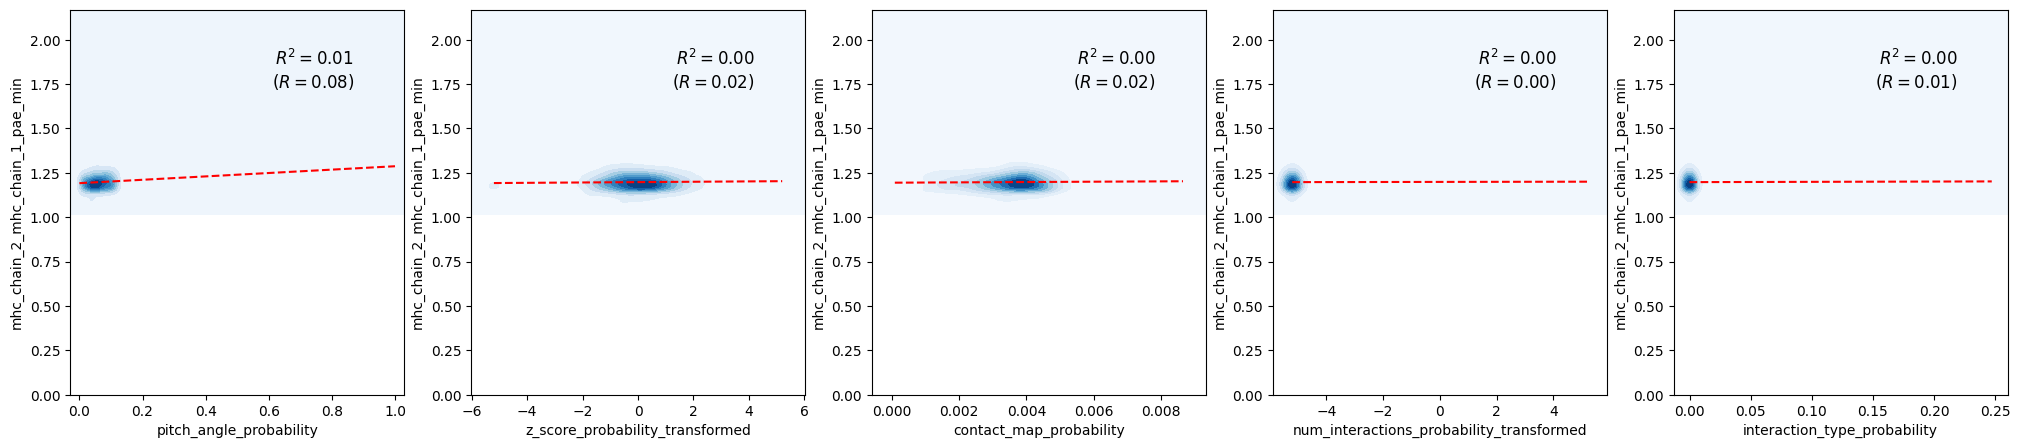

Skipping mhc_chain_2_mhc_chain_2_pae_min
tcr_pmhc_pae_score
Pearson's correlation: 0.39
                            OLS Regression Results                            
Dep. Variable:     tcr_pmhc_pae_score   R-squared:                       0.150
Model:                            OLS   Adj. R-squared:                  0.150
Method:                 Least Squares   F-statistic:                     260.8
Date:                Wed, 24 Sep 2025   Prob (F-statistic):          1.76e-257
Time:                        12:40:39   Log-Likelihood:                -19749.
No. Observations:                7375   AIC:                         3.951e+04
Df Residuals:                    7369   BIC:                         3.955e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
-------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-6.996940,1.001574,-6.985947,1.538244e-12,True
z_score_probability_transformed,-0.462451,0.036523,-12.662020,1.146071e-36,True
contact_map_probability,-1058.841068,43.923027,-24.106742,5.908358e-124,True
num_interactions_probability_transformed,-0.109869,0.128452,-0.855332,1.961977e-01,False
interaction_type_probability,0.201057,6.770541,0.029696,5.118448e-01,False


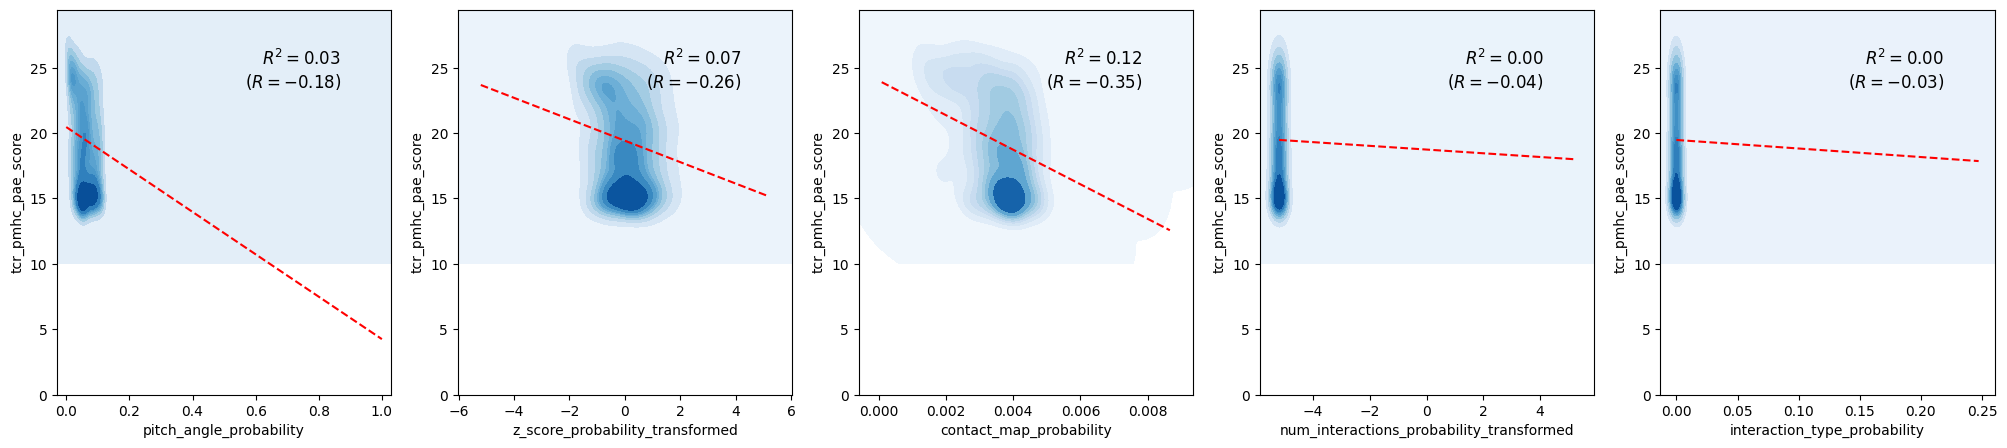

Best results: cdr_pmhc_pae_score R^2: 0.1676093831343365


In [40]:
pae_confidence_columns = sorted(structure_scores.filter(regex='pae').columns.tolist())

best_r_squared = 0
best_reg = None
best_name = None

X = structure_scores[structure_probability_names]
X = sm.add_constant(X)

for confidence_column in pae_confidence_columns:
    y = structure_scores[confidence_column]
    y_max = structure_scores[confidence_column].max()

    model = sm.OLS(y, X)
    reg = model.fit()
    pred_y = reg.fittedvalues

    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', scipy.stats.ConstantInputWarning)
            corr_coef, _ = scipy.stats.pearsonr(y, pred_y)

    except scipy.stats.ConstantInputWarning:
        print('Skipping', confidence_column)
        continue

    print(confidence_column)
    print('==============================================================================================')
    print(f"Pearson's correlation: {corr_coef:.2f}")
    print(reg.summary())
    print('\n\n')

    r_squared = reg.rsquared

    coefficients = pd.concat([reg.params[1:], reg.bse[1:]], axis=1)
    coefficients.columns = ['parameter', 'standard_error']

    coefficients['t_stat'] = coefficients['parameter'] / coefficients['standard_error']

    coefficients['probability'] = coefficients['t_stat'].apply(
        lambda t_stat, dof=reg.df_resid: scipy.stats.t.cdf(t_stat, df=dof)
    )
    coefficients['significant'] = coefficients['probability'] < SIGNIFICANCE_LEVEL

    display(coefficients)

    fig, axes = plt.subplots(1, len(structure_probability_names), figsize=(5 * len(structure_probability_names), 5))

    axes[0].set_ylabel(confidence_column)
    for i, column in enumerate(structure_probability_names):
        x = structure_scores[column]
        sns.kdeplot(x=x, y=y, cmap='Blues', fill=True, thresh=0, levels=10, ax=axes[i])

        reg = scipy.stats.linregress(x, y)
        x = np.linspace(x.min(), x.max())
        y_pred = reg.slope * x + reg.intercept

        axes[i].plot(x, y_pred, 'r--')
        axes[i].text(
            0.85,
            0.90,
            f'$R^2={reg.rvalue**2: .2f}$\n($R={reg.rvalue: .2f}$)',
            transform=axes[i].transAxes,
            horizontalalignment='right',
            verticalalignment='top',
            fontsize=12,
        )

        axes[i].set_xlabel(column)
        axes[i].set_ylim(0, y_max)

    plt.show()

    if r_squared > best_r_squared:
        best_r_squared = r_squared
        best_reg = reg
        best_name = confidence_column

print('==============================================================================================')
print('Best results:', best_name, 'R^2:', best_r_squared)
print('==============================================================================================')

alpha_chain_beta_chain_iptm
Pearson's correlation: 0.19
                                 OLS Regression Results                                
Dep. Variable:     alpha_chain_beta_chain_iptm   R-squared:                       0.035
Model:                                     OLS   Adj. R-squared:                  0.035
Method:                          Least Squares   F-statistic:                     53.86
Date:                         Wed, 24 Sep 2025   Prob (F-statistic):           4.11e-55
Time:                                 12:40:58   Log-Likelihood:                 20433.
No. Observations:                         7375   AIC:                        -4.085e+04
Df Residuals:                             7369   BIC:                        -4.081e+04
Df Model:                                    5                                         
Covariance Type:                     nonrobust                                         
                                               coef    std err  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.018497,0.004310,-4.291618,0.999991,False
z_score_probability_transformed,-0.001129,0.000157,-7.181850,1.000000,False
contact_map_probability,-1.708870,0.189009,-9.041206,1.000000,False
num_interactions_probability_transformed,0.001052,0.000553,1.903720,0.028493,True
interaction_type_probability,-0.067005,0.029135,-2.299834,0.989257,False


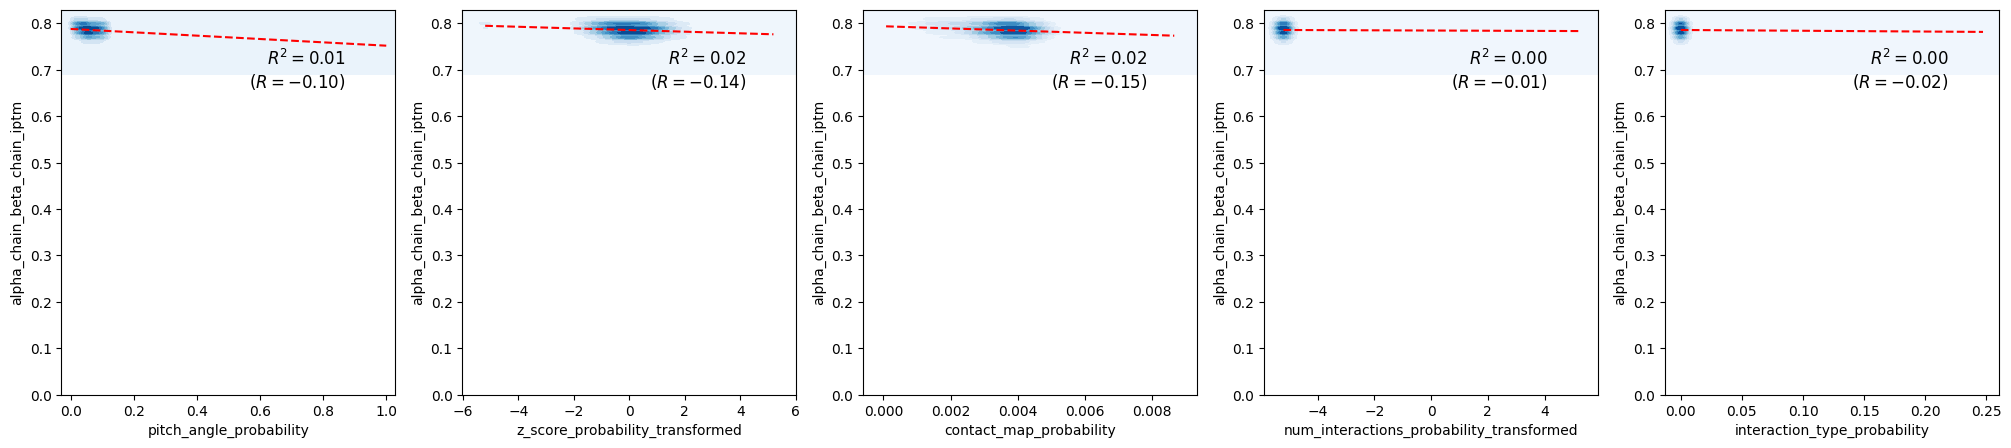

alpha_chain_iptm
Pearson's correlation: 0.36
                            OLS Regression Results                            
Dep. Variable:       alpha_chain_iptm   R-squared:                       0.133
Model:                            OLS   Adj. R-squared:                  0.132
Method:                 Least Squares   F-statistic:                     225.8
Date:                Wed, 24 Sep 2025   Prob (F-statistic):          5.95e-225
Time:                        12:41:16   Log-Likelihood:                 4465.1
No. Observations:                7375   AIC:                            -8918.
Df Residuals:                    7369   BIC:                            -8877.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.254622,0.037563,6.778489,6.540990e-12,True
z_score_probability_transformed,0.012950,0.001370,9.454176,0.000000e+00,True
contact_map_probability,39.501513,1.647301,23.979540,0.000000e+00,True
num_interactions_probability_transformed,0.004832,0.004817,1.003068,1.579305e-01,False
interaction_type_probability,-0.099075,0.253924,-0.390176,6.517912e-01,False


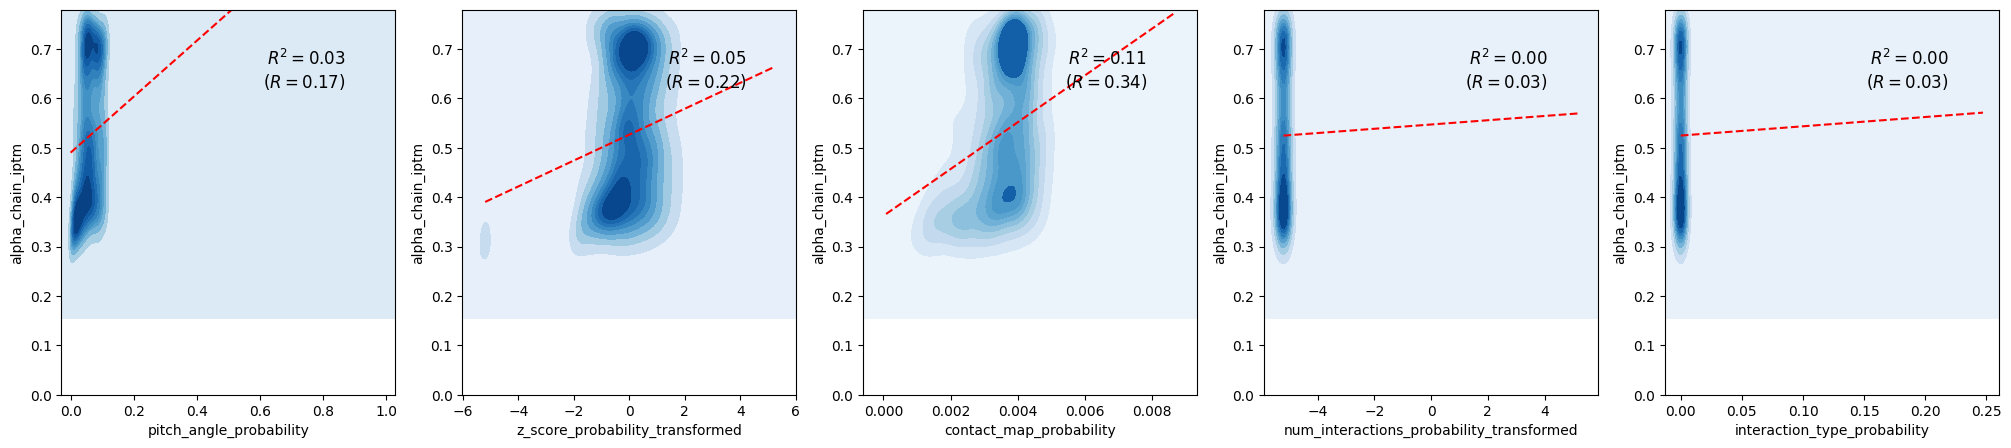

alpha_chain_ptm
Pearson's correlation: 0.17
                            OLS Regression Results                            
Dep. Variable:        alpha_chain_ptm   R-squared:                       0.028
Model:                            OLS   Adj. R-squared:                  0.027
Method:                 Least Squares   F-statistic:                     42.08
Date:                Wed, 24 Sep 2025   Prob (F-statistic):           7.16e-43
Time:                        12:41:35   Log-Likelihood:                 19366.
No. Observations:                7375   AIC:                        -3.872e+04
Df Residuals:                    7369   BIC:                        -3.868e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.018310,0.004980,-3.676291,0.999881,False
z_score_probability_transformed,-0.000850,0.000182,-4.678425,0.999999,False
contact_map_probability,-2.078798,0.218412,-9.517782,1.000000,False
num_interactions_probability_transformed,0.000349,0.000639,0.545740,0.292631,False
interaction_type_probability,-0.029855,0.033667,-0.886760,0.812381,False


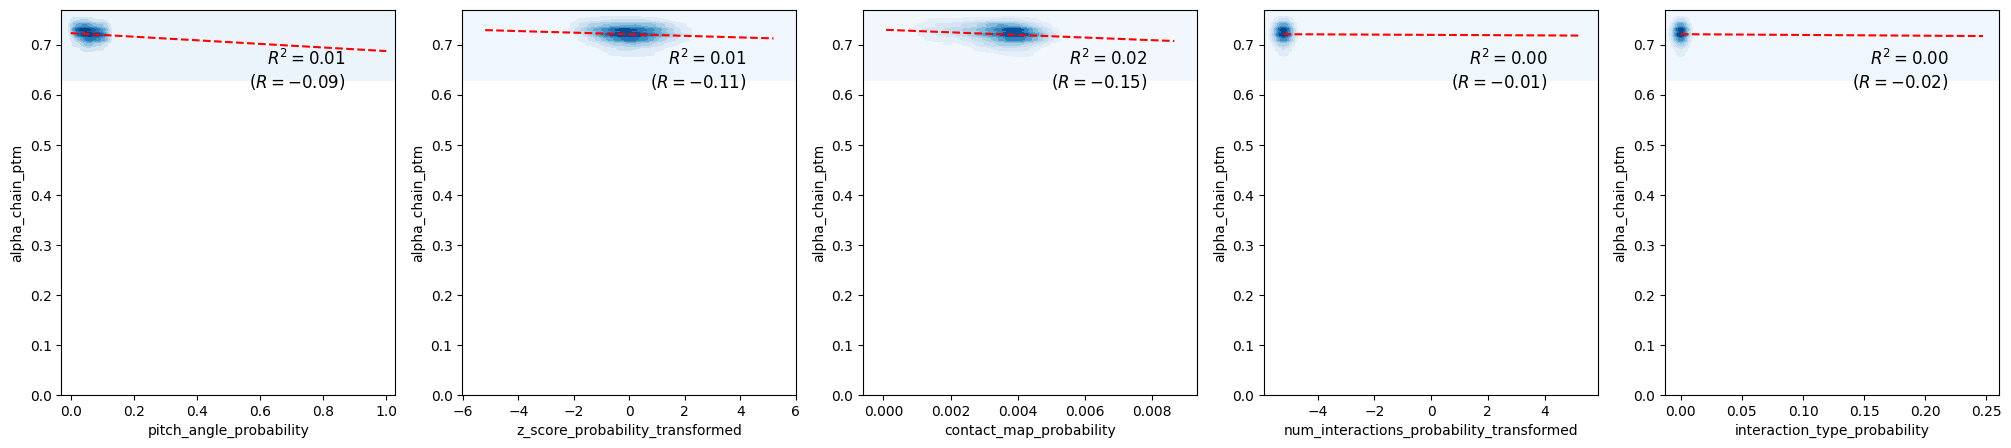

antigen_chain_alpha_chain_iptm
Pearson's correlation: 0.38
                                  OLS Regression Results                                  
Dep. Variable:     antigen_chain_alpha_chain_iptm   R-squared:                       0.143
Model:                                        OLS   Adj. R-squared:                  0.142
Method:                             Least Squares   F-statistic:                     245.9
Date:                            Wed, 24 Sep 2025   Prob (F-statistic):          1.07e-243
Time:                                    12:41:53   Log-Likelihood:                 1328.3
No. Observations:                            7375   AIC:                            -2645.
Df Residuals:                                7369   BIC:                            -2603.
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.369318,0.057475,6.425662,6.973488e-11,True
z_score_probability_transformed,0.022797,0.002096,10.877272,0.000000e+00,True
contact_map_probability,62.174368,2.520530,24.667180,0.000000e+00,True
num_interactions_probability_transformed,0.006884,0.007371,0.933848,1.752065e-01,False
interaction_type_probability,-0.140790,0.388529,-0.362367,6.414560e-01,False


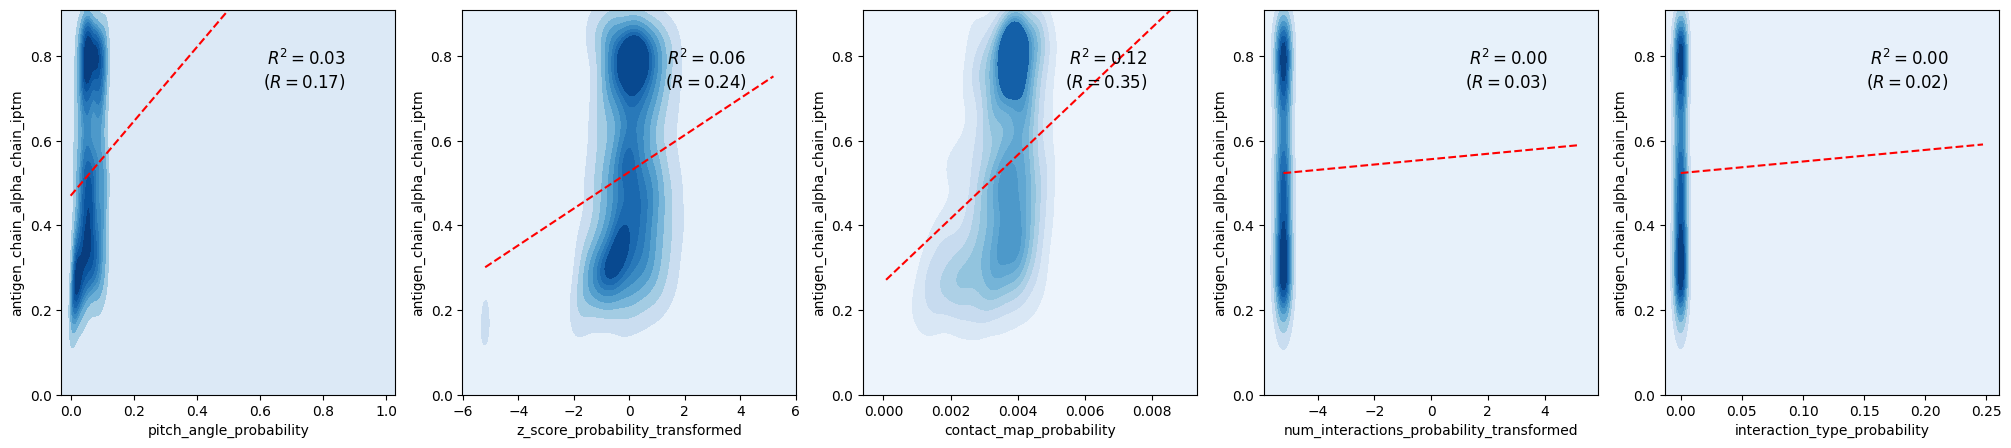

antigen_chain_beta_chain_iptm
Pearson's correlation: 0.38
                                  OLS Regression Results                                 
Dep. Variable:     antigen_chain_beta_chain_iptm   R-squared:                       0.141
Model:                                       OLS   Adj. R-squared:                  0.140
Method:                            Least Squares   F-statistic:                     241.4
Date:                           Wed, 24 Sep 2025   Prob (F-statistic):          1.86e-239
Time:                                   12:42:11   Log-Likelihood:                 1367.4
No. Observations:                           7375   AIC:                            -2723.
Df Residuals:                               7369   BIC:                            -2681.
Df Model:                                      5                                         
Covariance Type:                       nonrobust                                         
                                          

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.324485,0.057172,5.675645,7.170567e-09,True
z_score_probability_transformed,0.025190,0.002085,12.082667,0.000000e+00,True
contact_map_probability,59.771641,2.507201,23.839988,0.000000e+00,True
num_interactions_probability_transformed,0.004854,0.007332,0.662028,2.539870e-01,False
interaction_type_probability,-0.039355,0.386474,-0.101831,5.405530e-01,False


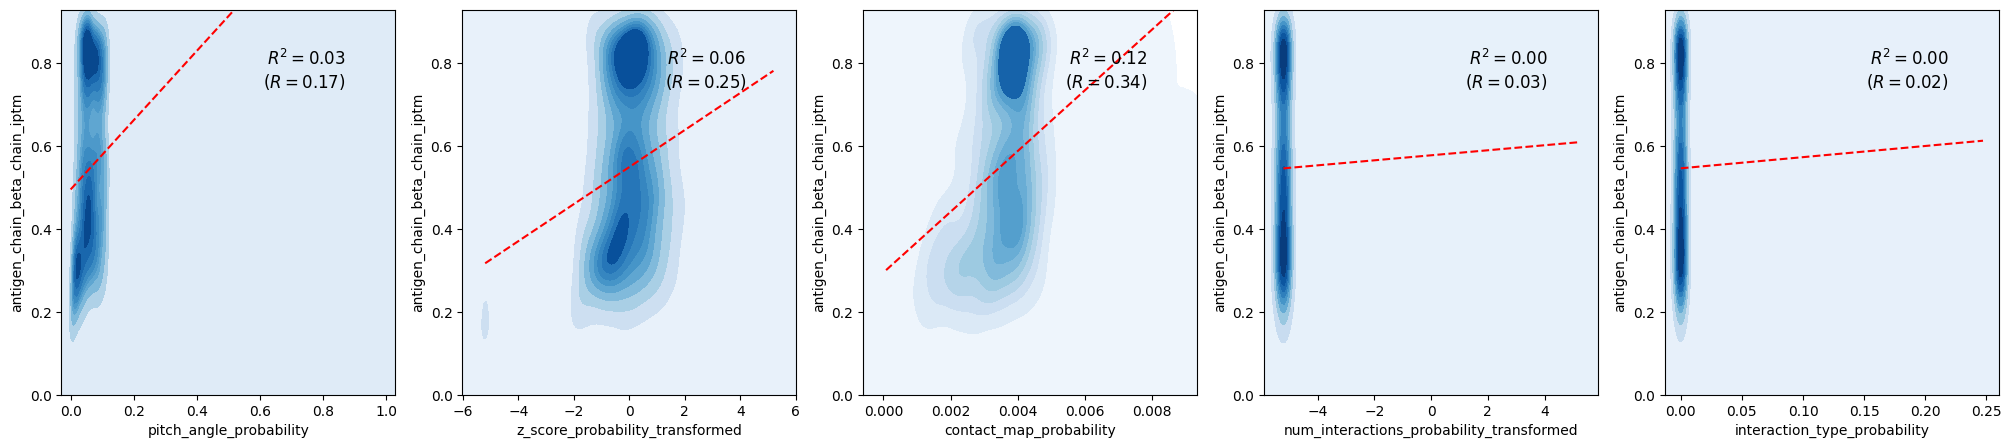

antigen_chain_iptm
Pearson's correlation: 0.36
                            OLS Regression Results                            
Dep. Variable:     antigen_chain_iptm   R-squared:                       0.128
Model:                            OLS   Adj. R-squared:                  0.128
Method:                 Least Squares   F-statistic:                     216.6
Date:                Wed, 24 Sep 2025   Prob (F-statistic):          3.19e-216
Time:                        12:42:29   Log-Likelihood:                 5824.6
No. Observations:                7375   AIC:                        -1.164e+04
Df Residuals:                    7369   BIC:                        -1.160e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.145014,0.031239,4.642007,0.000002,True
z_score_probability_transformed,0.012031,0.001139,10.561642,0.000000,True
contact_map_probability,32.311843,1.369976,23.585708,0.000000,True
num_interactions_probability_transformed,0.003787,0.004006,0.945145,0.172308,False
interaction_type_probability,-0.147964,0.211176,-0.700668,0.758234,False


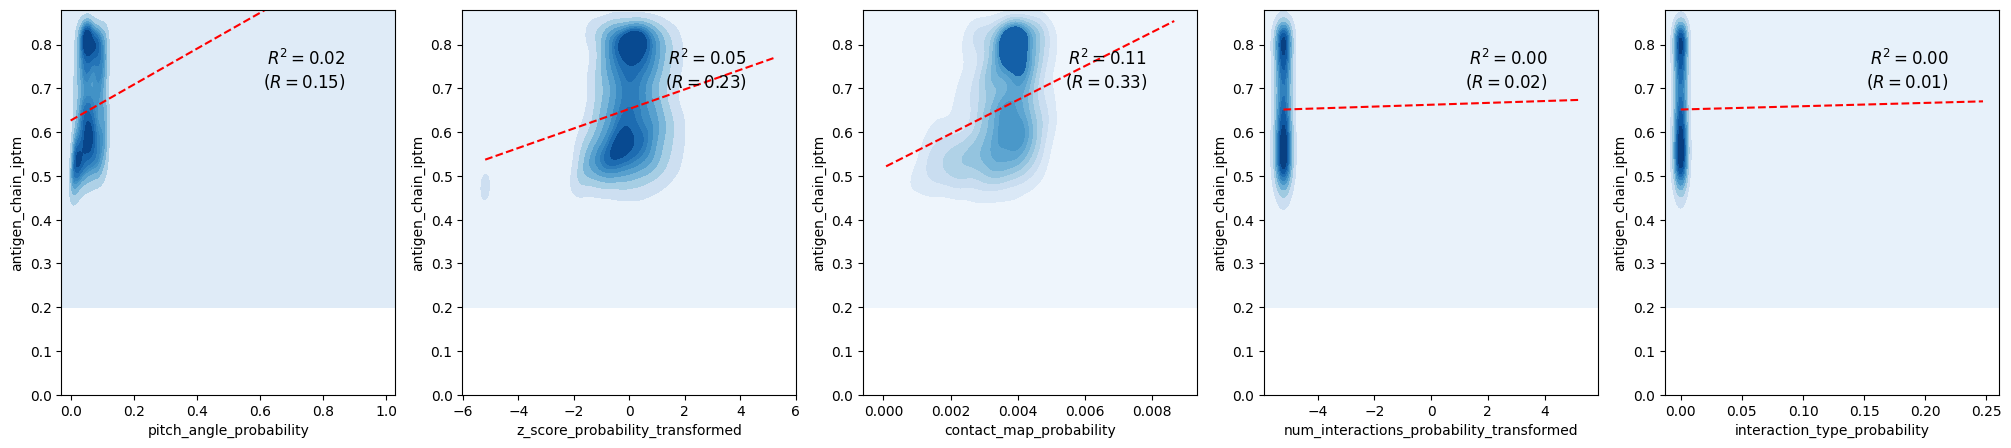

antigen_chain_ptm
Pearson's correlation: 0.05
                            OLS Regression Results                            
Dep. Variable:      antigen_chain_ptm   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                  0.002
Method:                 Least Squares   F-statistic:                     3.984
Date:                Wed, 24 Sep 2025   Prob (F-statistic):            0.00131
Time:                        12:42:47   Log-Likelihood:                 28846.
No. Observations:                7375   AIC:                        -5.768e+04
Df Residuals:                    7369   BIC:                        -5.764e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.003958,0.001377,-2.873847,0.997967,False
z_score_probability_transformed,0.000086,0.000050,1.718058,0.042914,True
contact_map_probability,0.051799,0.060405,0.857521,0.195593,False
num_interactions_probability_transformed,-0.000028,0.000177,-0.159836,0.563493,False
interaction_type_probability,-0.007533,0.009311,-0.808978,0.790723,False


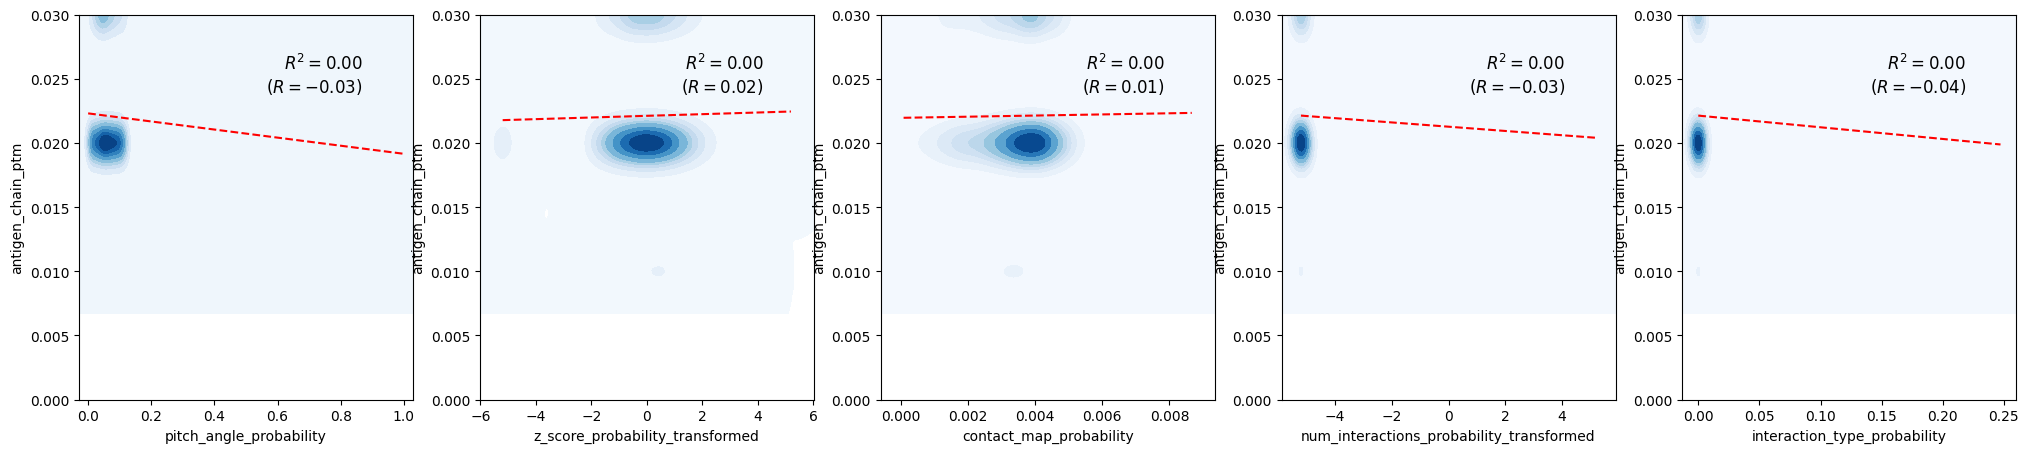

beta_chain_iptm
Pearson's correlation: 0.36
                            OLS Regression Results                            
Dep. Variable:        beta_chain_iptm   R-squared:                       0.130
Model:                            OLS   Adj. R-squared:                  0.130
Method:                 Least Squares   F-statistic:                     220.7
Date:                Wed, 24 Sep 2025   Prob (F-statistic):          4.10e-220
Time:                        12:43:06   Log-Likelihood:                 4384.6
No. Observations:                7375   AIC:                            -8757.
Df Residuals:                    7369   BIC:                            -8716.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.211912,0.037976,5.580212,1.243767e-08,True
z_score_probability_transformed,0.014648,0.001385,10.577650,0.000000e+00,True
contact_map_probability,38.958645,1.665386,23.393169,0.000000e+00,True
num_interactions_probability_transformed,0.003829,0.004870,0.786141,2.159052e-01,False
interaction_type_probability,-0.029041,0.256712,-0.113129,5.450342e-01,False


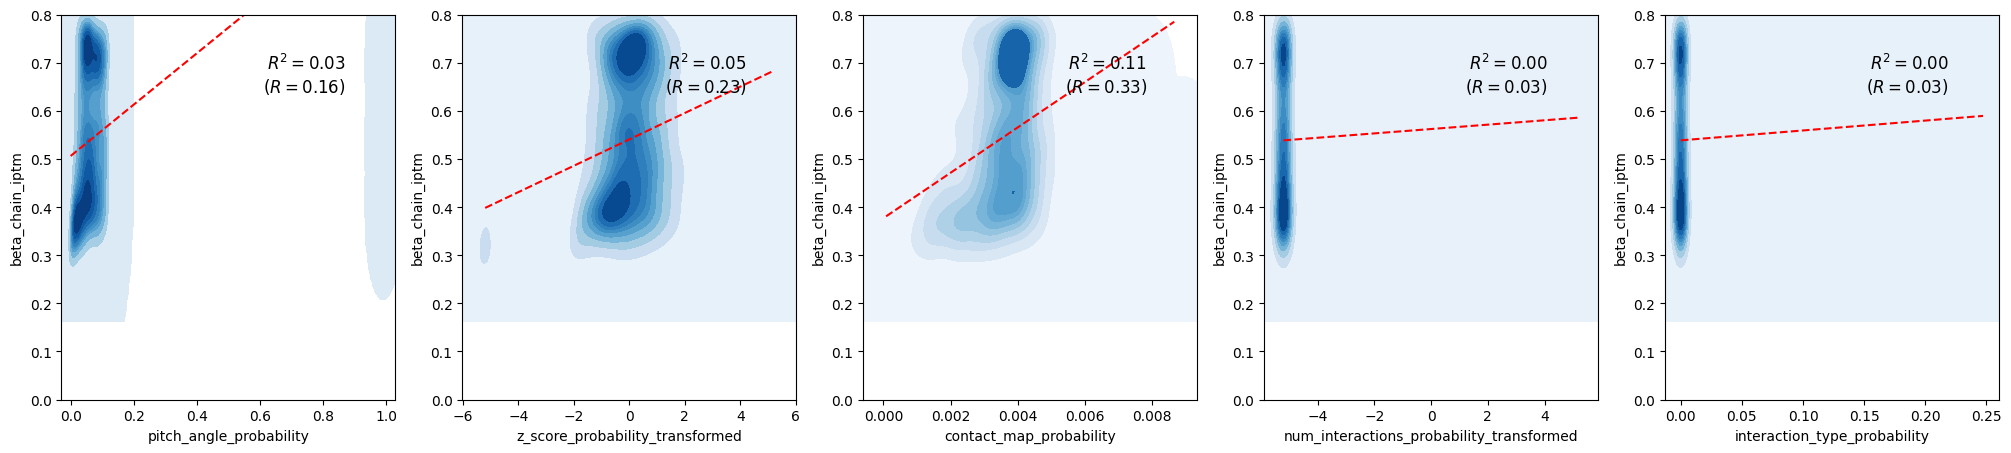

beta_chain_ptm
Pearson's correlation: 0.19
                            OLS Regression Results                            
Dep. Variable:         beta_chain_ptm   R-squared:                       0.035
Model:                            OLS   Adj. R-squared:                  0.035
Method:                 Least Squares   F-statistic:                     53.85
Date:                Wed, 24 Sep 2025   Prob (F-statistic):           4.19e-55
Time:                        12:43:24   Log-Likelihood:                 20697.
No. Observations:                7375   AIC:                        -4.138e+04
Df Residuals:                    7369   BIC:                        -4.134e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.011633,0.004158,-2.797744,0.997420,False
z_score_probability_transformed,-0.001158,0.000152,-7.636935,1.000000,False
contact_map_probability,-1.758747,0.182347,-9.645057,1.000000,False
num_interactions_probability_transformed,0.000666,0.000533,1.249460,0.105768,False
interaction_type_probability,-0.026169,0.028108,-0.931020,0.824063,False


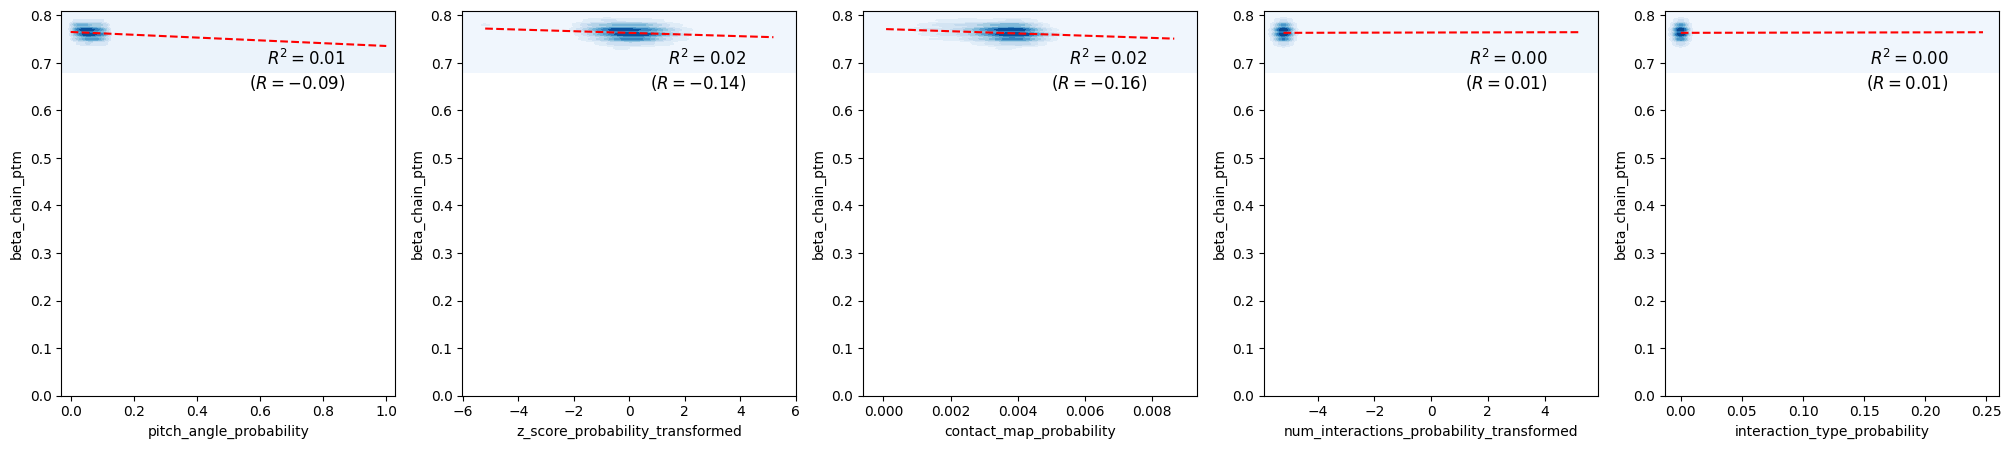

combined_iptm
Pearson's correlation: 0.37
                            OLS Regression Results                            
Dep. Variable:          combined_iptm   R-squared:                       0.137
Model:                            OLS   Adj. R-squared:                  0.136
Method:                 Least Squares   F-statistic:                     234.1
Date:                Wed, 24 Sep 2025   Prob (F-statistic):          1.10e-232
Time:                        12:43:42   Log-Likelihood:                 1680.3
No. Observations:                7375   AIC:                            -3349.
Df Residuals:                    7369   BIC:                            -3307.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.350253,0.054797,6.391867,8.692935e-11,True
z_score_probability_transformed,0.021316,0.001998,10.667632,0.000000e+00,True
contact_map_probability,57.549897,2.403057,23.948620,0.000000e+00,True
num_interactions_probability_transformed,0.006066,0.007028,0.863099,1.940555e-01,False
interaction_type_probability,-0.076147,0.370421,-0.205569,5.814335e-01,False


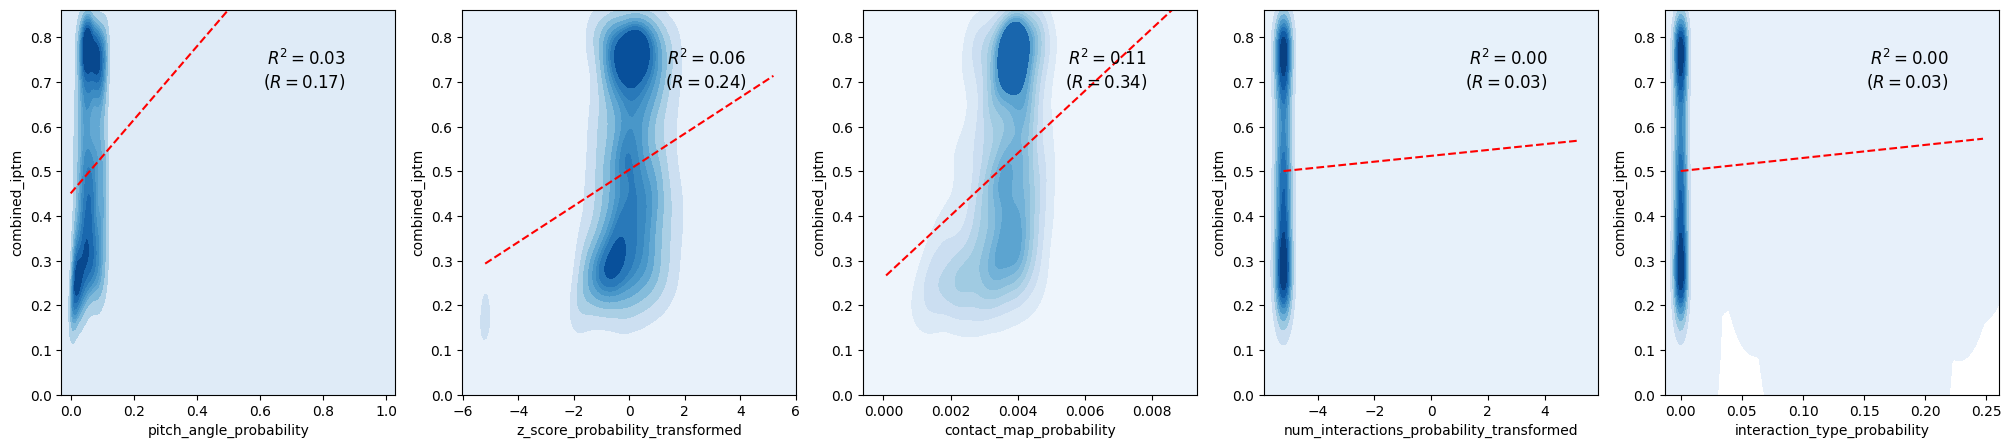

iptm
Pearson's correlation: 0.36
                            OLS Regression Results                            
Dep. Variable:                   iptm   R-squared:                       0.131
Model:                            OLS   Adj. R-squared:                  0.131
Method:                 Least Squares   F-statistic:                     223.1
Date:                Wed, 24 Sep 2025   Prob (F-statistic):          2.27e-222
Time:                        12:44:00   Log-Likelihood:                 6358.4
No. Observations:                7375   AIC:                        -1.270e+04
Df Residuals:                    7369   BIC:                        -1.266e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.192479,0.029058,6.623870,1.872669e-11,True
z_score_probability_transformed,0.010367,0.001060,9.783697,0.000000e+00,True
contact_map_probability,30.057573,1.274330,23.586957,0.000000e+00,True
num_interactions_probability_transformed,0.003519,0.003727,0.944332,1.725154e-01,False
interaction_type_probability,-0.032166,0.196432,-0.163753,5.650351e-01,False


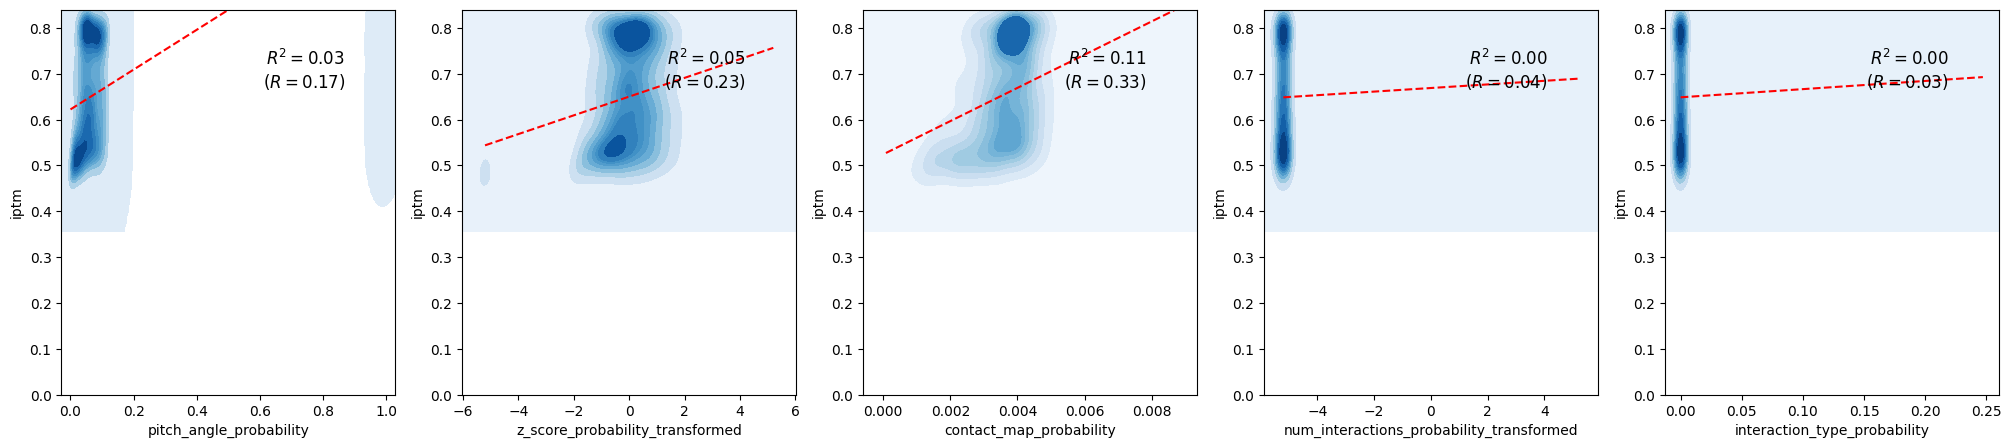

mhc_chain_1_alpha_chain_iptm
Pearson's correlation: 0.36
                                 OLS Regression Results                                 
Dep. Variable:     mhc_chain_1_alpha_chain_iptm   R-squared:                       0.131
Model:                                      OLS   Adj. R-squared:                  0.130
Method:                           Least Squares   F-statistic:                     221.8
Date:                          Wed, 24 Sep 2025   Prob (F-statistic):          4.15e-221
Time:                                  12:44:18   Log-Likelihood:                 1891.1
No. Observations:                          7375   AIC:                            -3770.
Df Residuals:                              7369   BIC:                            -3729.
Df Model:                                     5                                         
Covariance Type:                      nonrobust                                         
                                               coef  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.392197,0.053252,7.364896,9.825474e-14,True
z_score_probability_transformed,0.017705,0.001942,9.117508,0.000000e+00,True
contact_map_probability,55.050838,2.335321,23.573131,0.000000e+00,True
num_interactions_probability_transformed,0.006695,0.006830,0.980352,1.634723e-01,False
interaction_type_probability,-0.092693,0.359980,-0.257495,6.015980e-01,False


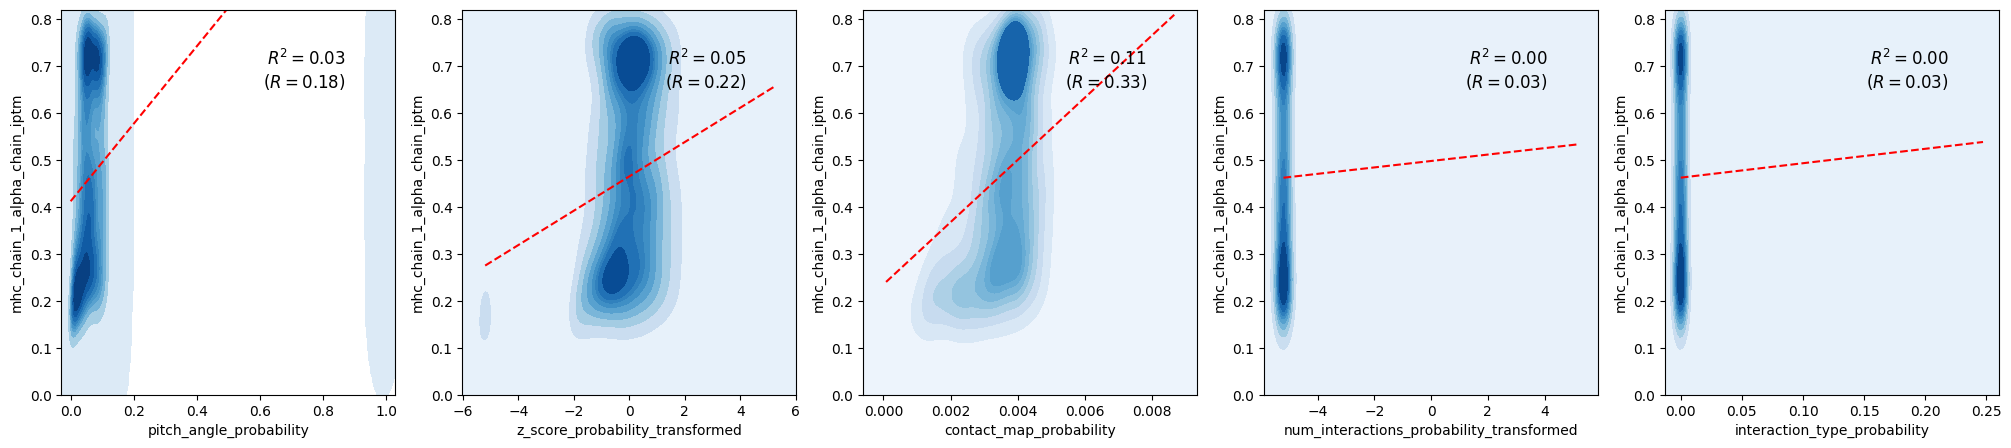

mhc_chain_1_antigen_chain_iptm
Pearson's correlation: 0.09
                                  OLS Regression Results                                  
Dep. Variable:     mhc_chain_1_antigen_chain_iptm   R-squared:                       0.009
Model:                                        OLS   Adj. R-squared:                  0.008
Method:                             Least Squares   F-statistic:                     12.71
Date:                            Wed, 24 Sep 2025   Prob (F-statistic):           2.54e-12
Time:                                    12:44:37   Log-Likelihood:                 11855.
No. Observations:                            7375   AIC:                        -2.370e+04
Df Residuals:                                7369   BIC:                        -2.366e+04
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.039621,0.013790,-2.873081,9.979617e-01,False
z_score_probability_transformed,-0.000212,0.000503,-0.421107,6.631554e-01,False
contact_map_probability,3.997937,0.604765,6.610726,2.045653e-11,True
num_interactions_probability_transformed,0.001803,0.001769,1.019649,1.539642e-01,False
interaction_type_probability,-0.201235,0.093222,-2.158664,9.845458e-01,False


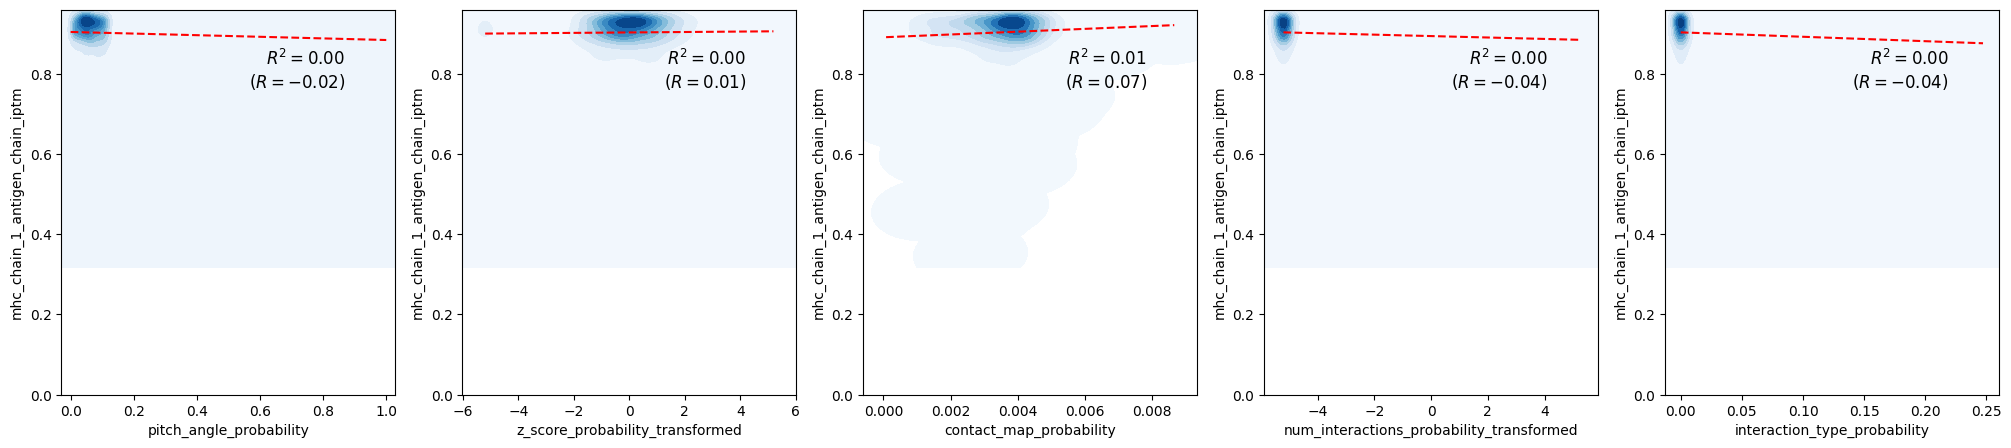

mhc_chain_1_beta_chain_iptm
Pearson's correlation: 0.36
                                 OLS Regression Results                                
Dep. Variable:     mhc_chain_1_beta_chain_iptm   R-squared:                       0.128
Model:                                     OLS   Adj. R-squared:                  0.127
Method:                          Least Squares   F-statistic:                     215.4
Date:                         Wed, 24 Sep 2025   Prob (F-statistic):          3.86e-215
Time:                                 12:45:00   Log-Likelihood:                 1973.5
No. Observations:                         7375   AIC:                            -3935.
Df Residuals:                             7369   BIC:                            -3894.
Df Model:                                    5                                         
Covariance Type:                     nonrobust                                         
                                               coef    std err  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.315014,0.052661,5.981942,1.154008e-09,True
z_score_probability_transformed,0.019572,0.001920,10.191977,0.000000e+00,True
contact_map_probability,53.202740,2.309388,23.037591,0.000000e+00,True
num_interactions_probability_transformed,0.005829,0.006754,0.863103,1.940544e-01,False
interaction_type_probability,-0.031751,0.355982,-0.089192,5.355343e-01,False


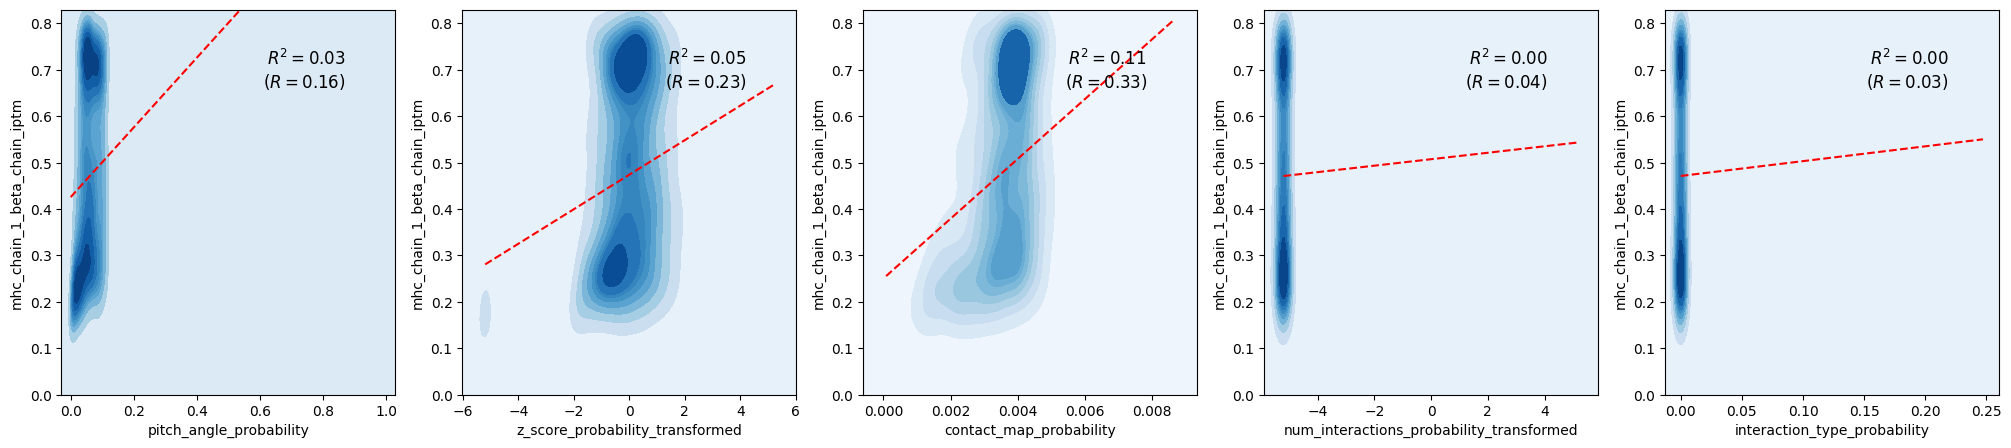

mhc_chain_1_iptm
Pearson's correlation: 0.35
                            OLS Regression Results                            
Dep. Variable:       mhc_chain_1_iptm   R-squared:                       0.123
Model:                            OLS   Adj. R-squared:                  0.122
Method:                 Least Squares   F-statistic:                     206.4
Date:                Wed, 24 Sep 2025   Prob (F-statistic):          1.32e-206
Time:                        12:45:18   Log-Likelihood:                 6656.6
No. Observations:                7375   AIC:                        -1.330e+04
Df Residuals:                    7369   BIC:                        -1.326e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.159779,0.027907,5.725418,5.361681e-09,True
z_score_probability_transformed,0.009336,0.001018,9.174378,0.000000e+00,True
contact_map_probability,28.394516,1.223830,23.201357,0.000000e+00,True
num_interactions_probability_transformed,0.003738,0.003579,1.044380,1.481718e-01,False
interaction_type_probability,-0.091203,0.188648,-0.483458,6.856074e-01,False


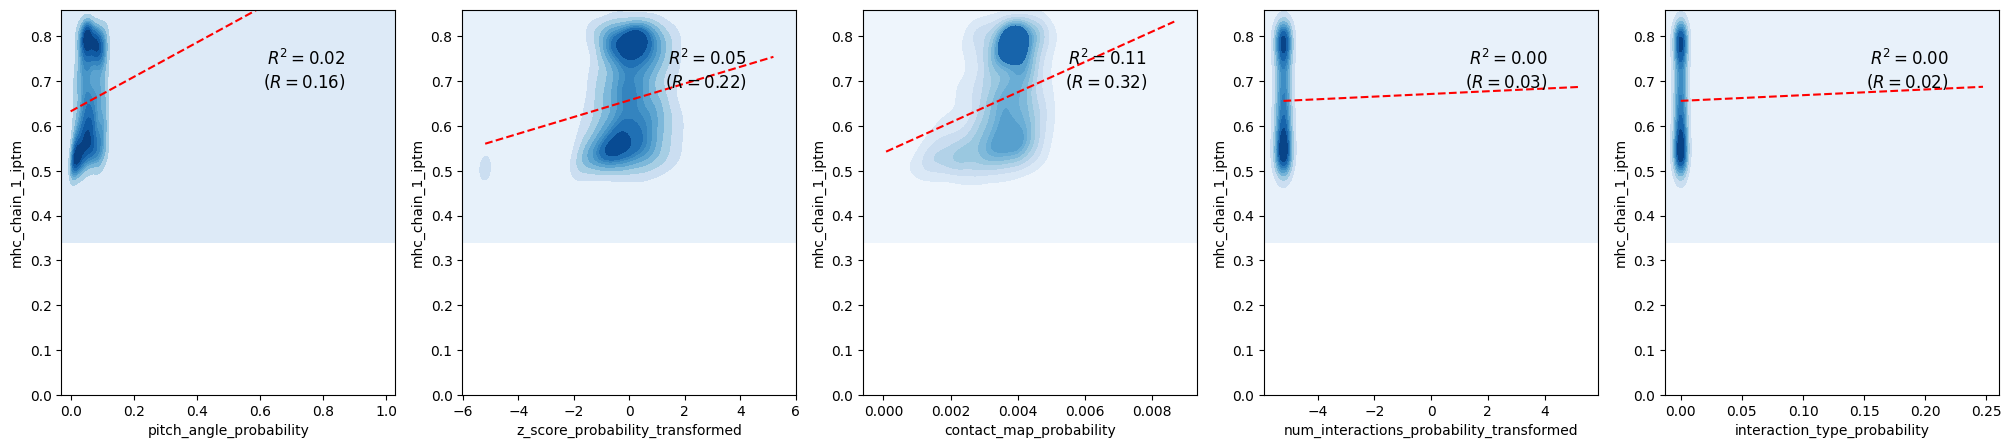

mhc_chain_1_mhc_chain_2_iptm
Pearson's correlation: 0.07
                                 OLS Regression Results                                 
Dep. Variable:     mhc_chain_1_mhc_chain_2_iptm   R-squared:                       0.005
Model:                                      OLS   Adj. R-squared:                  0.004
Method:                           Least Squares   F-statistic:                     6.663
Date:                          Wed, 24 Sep 2025   Prob (F-statistic):           3.36e-06
Time:                                  12:45:37   Log-Likelihood:                 16350.
No. Observations:                          7375   AIC:                        -3.269e+04
Df Residuals:                              7369   BIC:                        -3.265e+04
Df Model:                                     5                                         
Covariance Type:                      nonrobust                                         
                                               coef  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.033514,0.007497,-4.470074,0.999996,False
z_score_probability_transformed,0.000438,0.000273,1.600833,0.054728,False
contact_map_probability,1.214986,0.328787,3.695356,0.000111,True
num_interactions_probability_transformed,0.000797,0.000962,0.829138,0.203527,False
interaction_type_probability,-0.040969,0.050681,-0.808368,0.790548,False


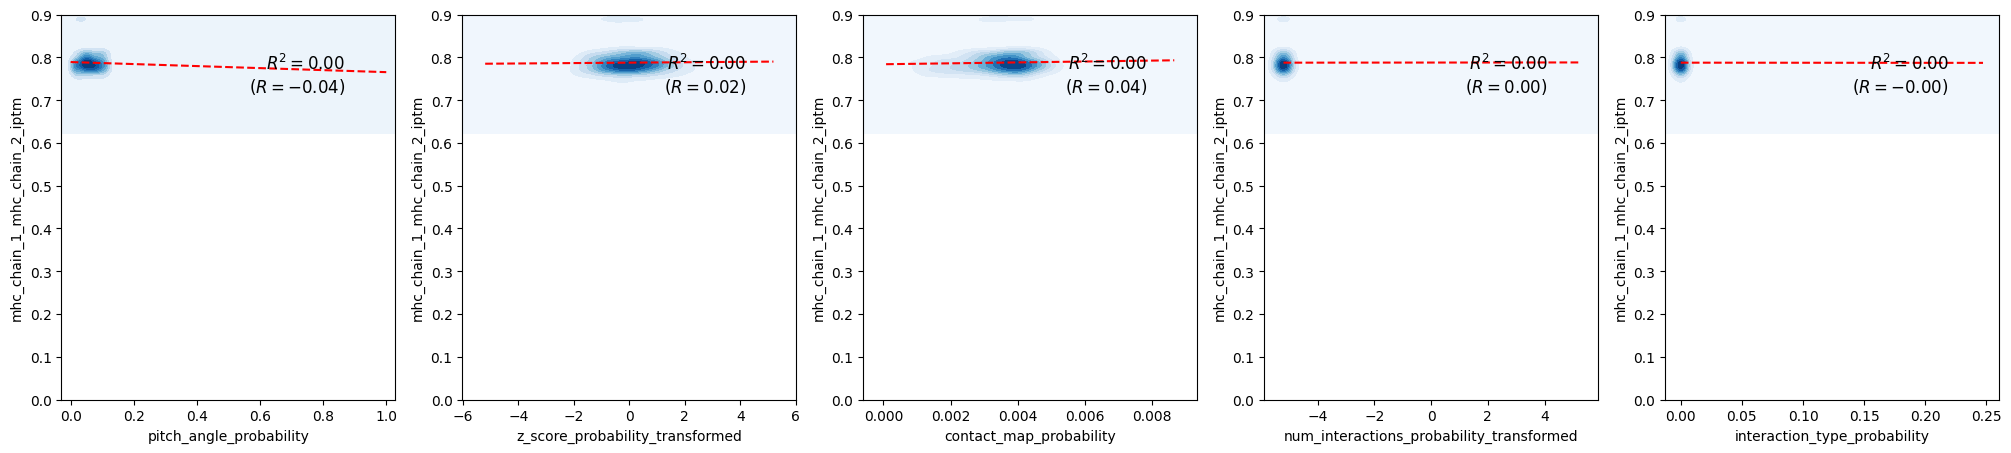

mhc_chain_1_ptm
Pearson's correlation: 0.11
                            OLS Regression Results                            
Dep. Variable:        mhc_chain_1_ptm   R-squared:                       0.012
Model:                            OLS   Adj. R-squared:                  0.012
Method:                 Least Squares   F-statistic:                     18.28
Date:                Wed, 24 Sep 2025   Prob (F-statistic):           4.39e-18
Time:                        12:45:55   Log-Likelihood:                 19170.
No. Observations:                7375   AIC:                        -3.833e+04
Df Residuals:                    7369   BIC:                        -3.829e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.006423,0.005115,-1.255759,8.953785e-01,False
z_score_probability_transformed,0.000407,0.000187,2.180055,1.464246e-02,True
contact_map_probability,1.726765,0.224301,7.698434,7.771561e-15,True
num_interactions_probability_transformed,0.001038,0.000656,1.582271,5.681527e-02,False
interaction_type_probability,-0.026447,0.034575,-0.764919,7.778278e-01,False


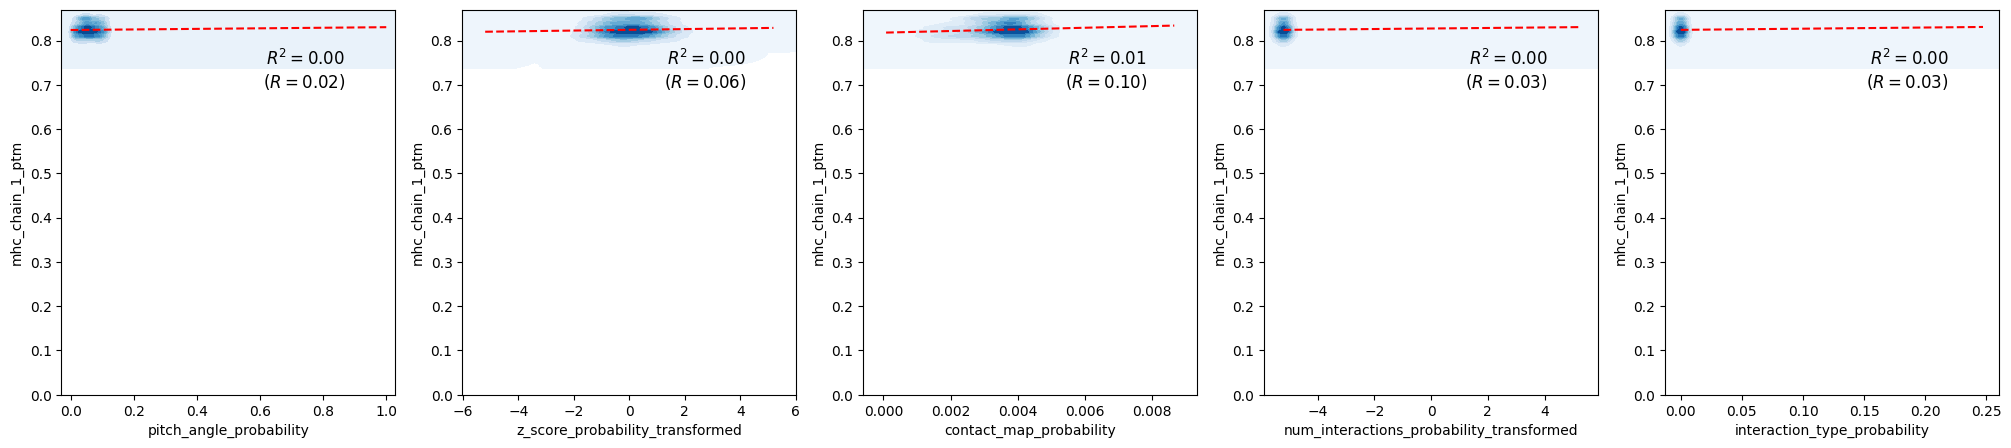

mhc_chain_2_alpha_chain_iptm
Pearson's correlation: 0.35
                                 OLS Regression Results                                 
Dep. Variable:     mhc_chain_2_alpha_chain_iptm   R-squared:                       0.125
Model:                                      OLS   Adj. R-squared:                  0.124
Method:                           Least Squares   F-statistic:                     210.6
Date:                          Wed, 24 Sep 2025   Prob (F-statistic):          1.44e-210
Time:                                  12:46:14   Log-Likelihood:                 3800.6
No. Observations:                          7375   AIC:                            -7589.
Df Residuals:                              7369   BIC:                            -7548.
Df Model:                                     5                                         
Covariance Type:                      nonrobust                                         
                                               coef  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.274328,0.041105,6.673814,1.336575e-11,True
z_score_probability_transformed,0.012343,0.001499,8.234388,1.110223e-16,True
contact_map_probability,42.708589,1.802622,23.692479,0.000000e+00,True
num_interactions_probability_transformed,0.004102,0.005272,0.778119,2.182618e-01,False
interaction_type_probability,-0.057701,0.277866,-0.207658,5.822489e-01,False


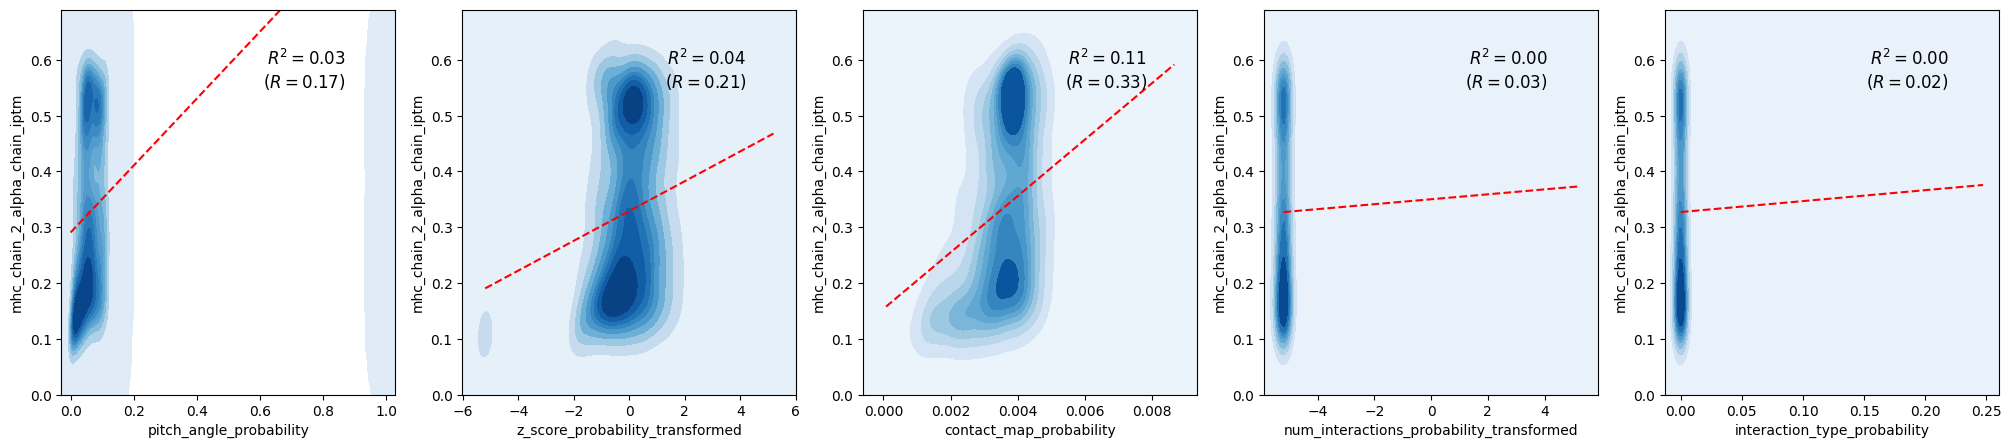

mhc_chain_2_antigen_chain_iptm
Pearson's correlation: 0.09
                                  OLS Regression Results                                  
Dep. Variable:     mhc_chain_2_antigen_chain_iptm   R-squared:                       0.008
Model:                                        OLS   Adj. R-squared:                  0.007
Method:                             Least Squares   F-statistic:                     11.91
Date:                            Wed, 24 Sep 2025   Prob (F-statistic):           1.67e-11
Time:                                    12:46:32   Log-Likelihood:                 11005.
No. Observations:                            7375   AIC:                        -2.200e+04
Df Residuals:                                7369   BIC:                        -2.196e+04
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.077902,0.015476,-5.033826,9.999998e-01,False
z_score_probability_transformed,0.000124,0.000564,0.219389,4.131767e-01,False
contact_map_probability,3.492979,0.678671,5.146789,1.359156e-07,True
num_interactions_probability_transformed,0.001565,0.001985,0.788707,2.151543e-01,False
interaction_type_probability,-0.199758,0.104614,-1.909470,9.718798e-01,False


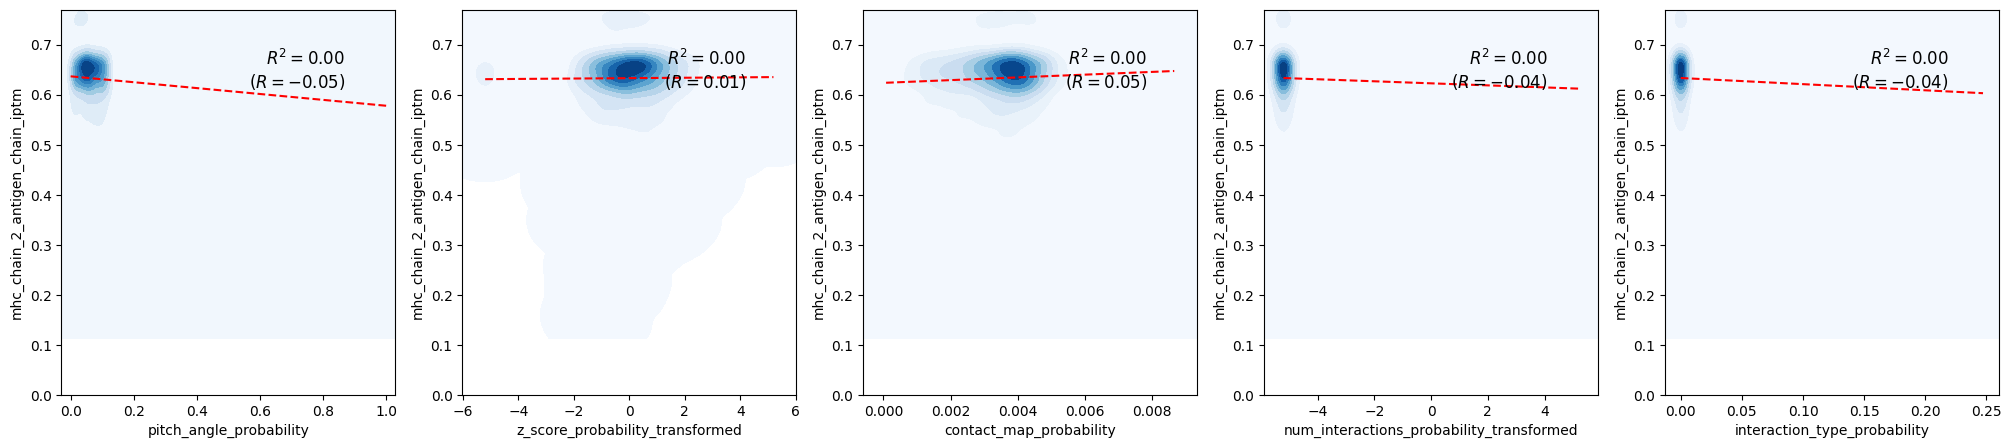

mhc_chain_2_beta_chain_iptm
Pearson's correlation: 0.35
                                 OLS Regression Results                                
Dep. Variable:     mhc_chain_2_beta_chain_iptm   R-squared:                       0.123
Model:                                     OLS   Adj. R-squared:                  0.123
Method:                          Least Squares   F-statistic:                     207.7
Date:                         Wed, 24 Sep 2025   Prob (F-statistic):          8.68e-208
Time:                                 12:46:54   Log-Likelihood:                 3344.1
No. Observations:                         7375   AIC:                            -6676.
Df Residuals:                             7369   BIC:                            -6635.
Df Model:                                    5                                         
Covariance Type:                     nonrobust                                         
                                               coef    std err  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.231274,0.043730,5.288728,6.335541e-08,True
z_score_probability_transformed,0.014955,0.001595,9.378435,0.000000e+00,True
contact_map_probability,44.791703,1.917719,23.356756,0.000000e+00,True
num_interactions_probability_transformed,0.003839,0.005608,0.684588,2.468128e-01,False
interaction_type_probability,-0.005517,0.295608,-0.018662,5.074443e-01,False


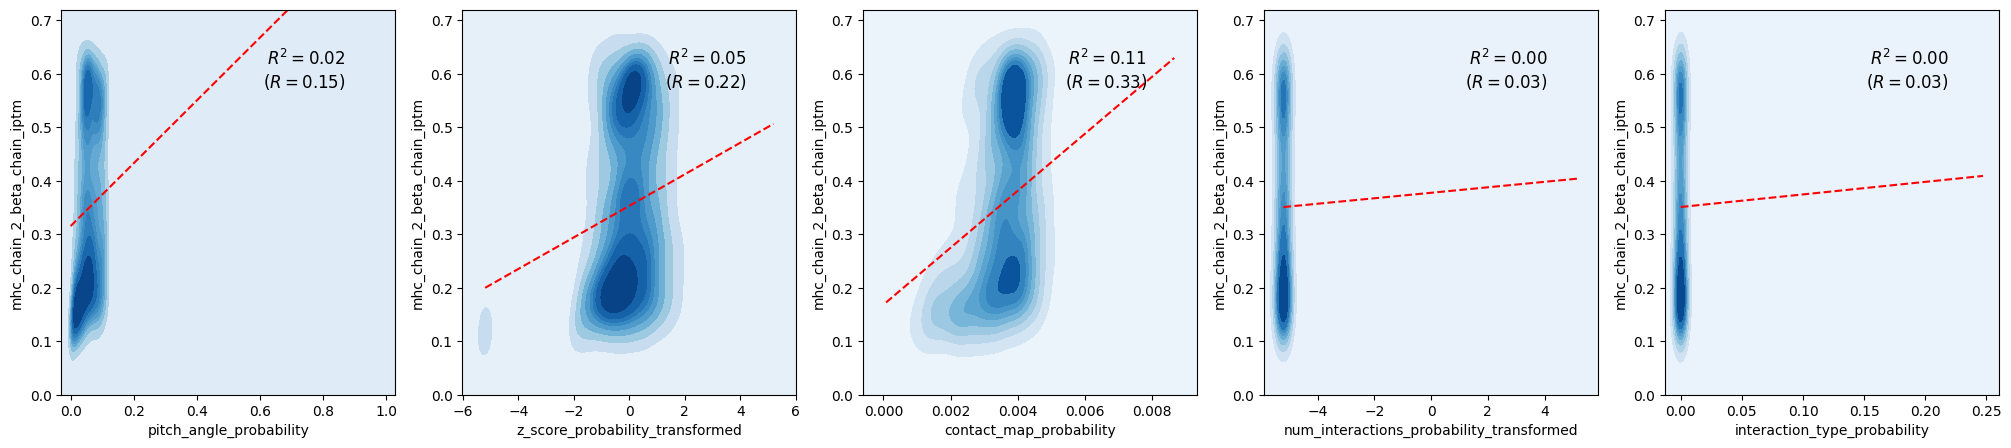

mhc_chain_2_iptm
Pearson's correlation: 0.34
                            OLS Regression Results                            
Dep. Variable:       mhc_chain_2_iptm   R-squared:                       0.114
Model:                            OLS   Adj. R-squared:                  0.113
Method:                 Least Squares   F-statistic:                     189.4
Date:                Wed, 24 Sep 2025   Prob (F-statistic):          2.21e-190
Time:                        12:47:12   Log-Likelihood:                 8151.4
No. Observations:                7375   AIC:                        -1.629e+04
Df Residuals:                    7369   BIC:                        -1.625e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.098570,0.022787,4.325739,0.000008,True
z_score_probability_transformed,0.006978,0.000831,8.397616,0.000000,True
contact_map_probability,23.023218,0.999296,23.039446,0.000000,True
num_interactions_probability_transformed,0.002438,0.002922,0.834197,0.202099,False
interaction_type_probability,-0.068655,0.154037,-0.445703,0.672088,False


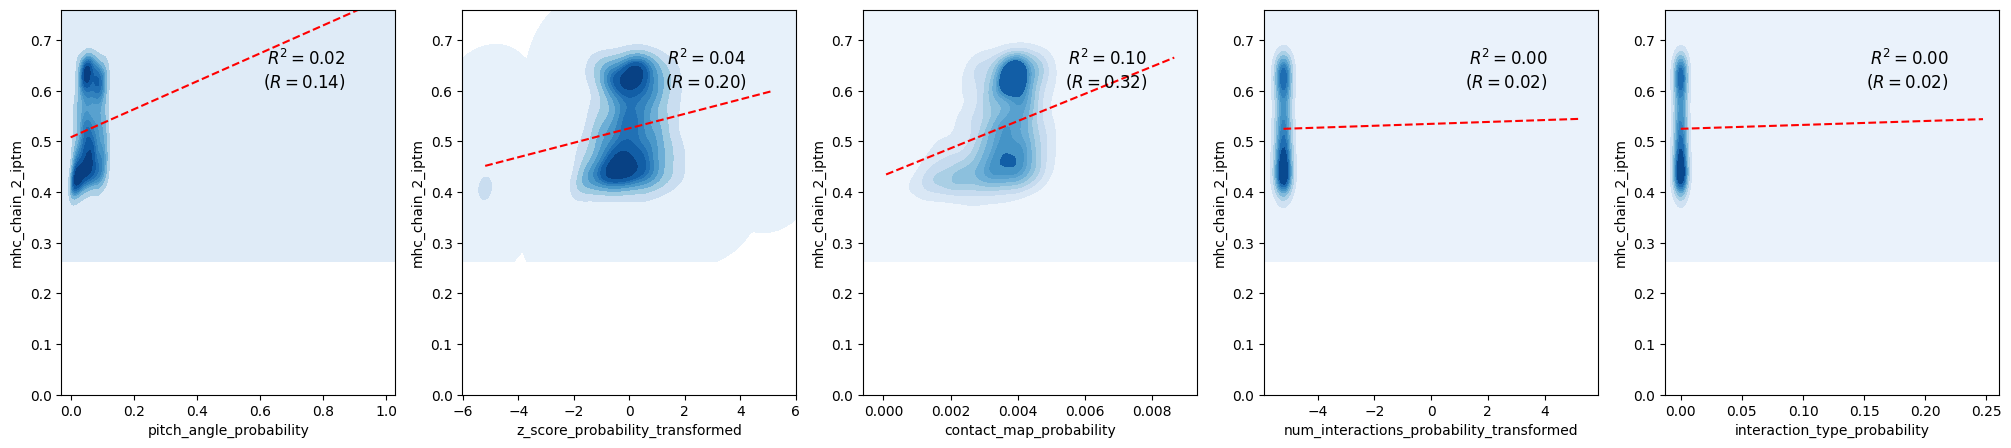

mhc_chain_2_ptm
Pearson's correlation: 0.10
                            OLS Regression Results                            
Dep. Variable:        mhc_chain_2_ptm   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     14.24
Date:                Wed, 24 Sep 2025   Prob (F-statistic):           6.69e-14
Time:                        12:47:30   Log-Likelihood:                 11859.
No. Observations:                7375   AIC:                        -2.371e+04
Df Residuals:                    7369   BIC:                        -2.367e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.096886,0.013783,-7.029445,1.000000,False
z_score_probability_transformed,-0.001031,0.000503,-2.052130,0.979904,False
contact_map_probability,1.091229,0.604433,1.805376,0.035528,True
num_interactions_probability_transformed,-0.002730,0.001768,-1.544536,0.938749,False
interaction_type_probability,0.063778,0.093171,0.684529,0.246831,False


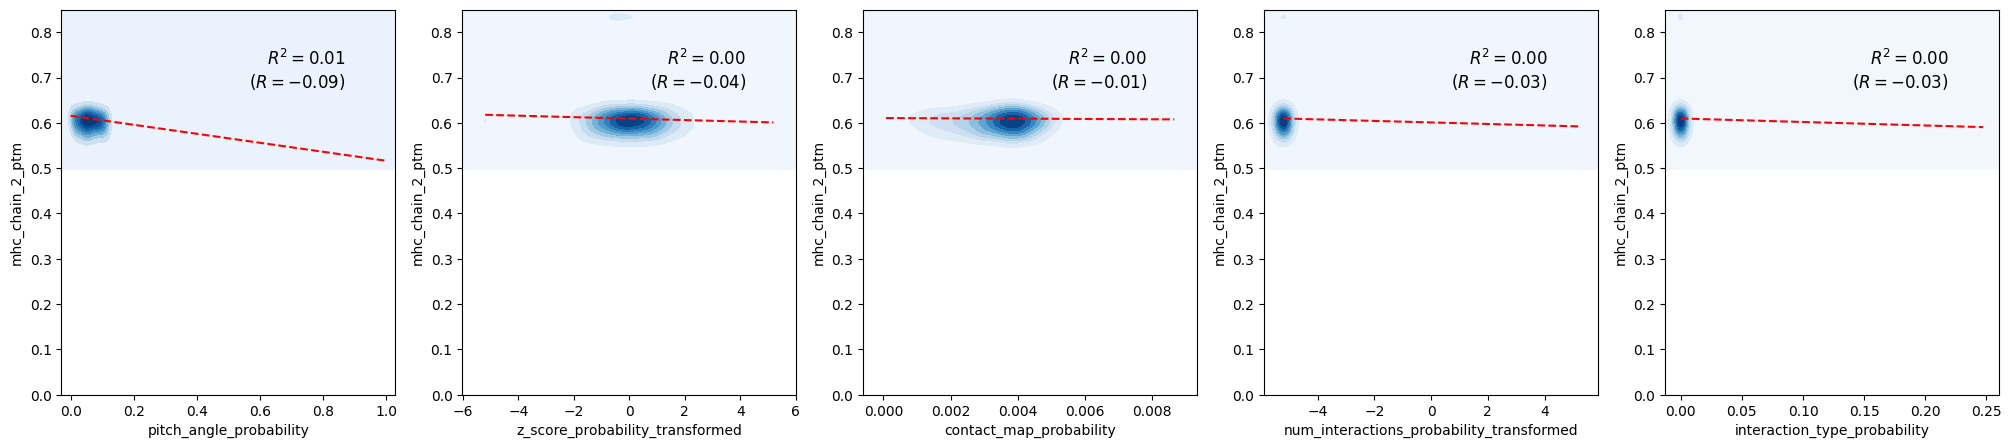

ptm
Pearson's correlation: 0.35
                            OLS Regression Results                            
Dep. Variable:                    ptm   R-squared:                       0.125
Model:                            OLS   Adj. R-squared:                  0.124
Method:                 Least Squares   F-statistic:                     210.5
Date:                Wed, 24 Sep 2025   Prob (F-statistic):          1.76e-210
Time:                        12:47:49   Log-Likelihood:                 8882.9
No. Observations:                7375   AIC:                        -1.775e+04
Df Residuals:                    7369   BIC:                        -1.771e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.126876,0.020635,6.148506,4.114811e-10,True
z_score_probability_transformed,0.007238,0.000752,9.618408,0.000000e+00,True
contact_map_probability,20.784480,0.904941,22.967781,0.000000e+00,True
num_interactions_probability_transformed,0.002371,0.002646,0.896040,1.851305e-01,False
interaction_type_probability,-0.015765,0.139493,-0.113017,5.449898e-01,False


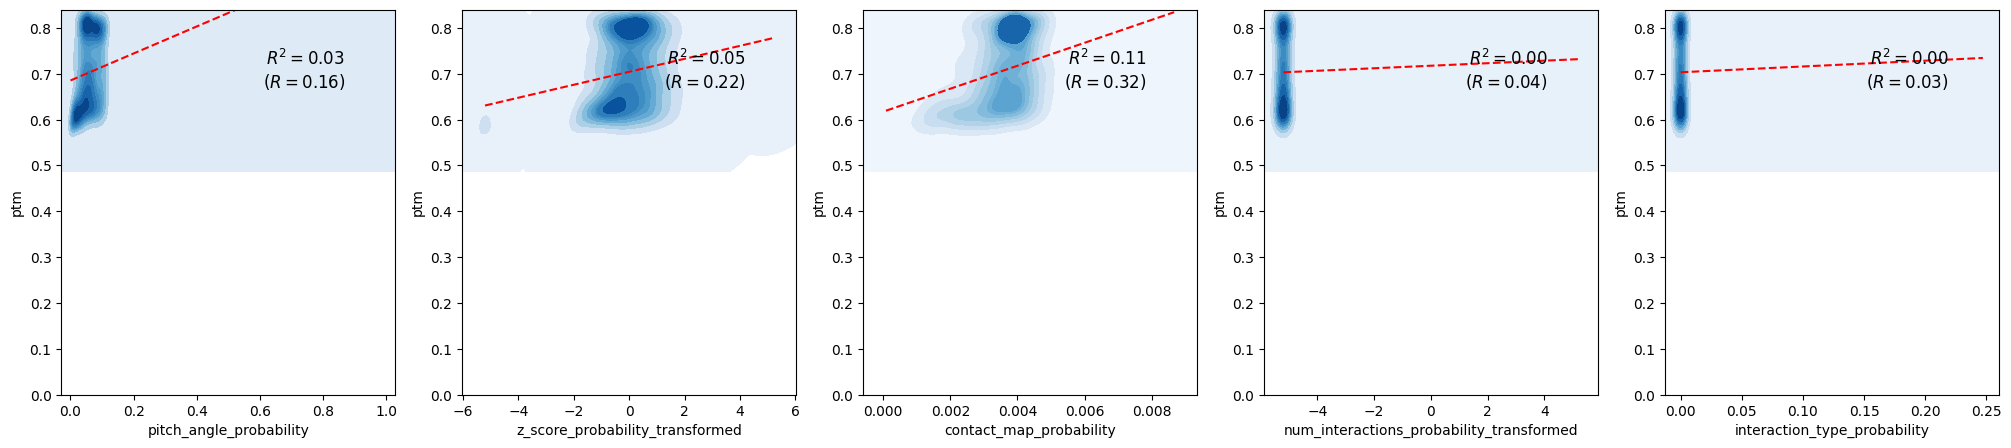

Best results: antigen_chain_alpha_chain_iptm R^2: 0.14299995622154127


In [41]:
ptm_confidence_columns = sorted(structure_scores.filter(regex='ptm').columns.tolist())

best_r_squared = 0
best_reg = None
best_name = None

X = structure_scores[structure_probability_names]
X = sm.add_constant(X)

for confidence_column in ptm_confidence_columns:
    y = structure_scores[confidence_column]
    y_max = structure_scores[confidence_column].max()

    model = sm.OLS(y, X)
    reg = model.fit()
    pred_y = reg.fittedvalues

    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', scipy.stats.ConstantInputWarning)
            corr_coef, _ = scipy.stats.pearsonr(y, pred_y)

    except scipy.stats.ConstantInputWarning:
        print('Skipping', confidence_column)
        continue

    print(confidence_column)
    print('==============================================================================================')
    print(f"Pearson's correlation: {corr_coef:.2f}")
    print(reg.summary())
    print('\n\n')

    r_squared = reg.rsquared

    coefficients = pd.concat([reg.params[1:], reg.bse[1:]], axis=1)
    coefficients.columns = ['parameter', 'standard_error']

    coefficients['t_stat'] = coefficients['parameter'] / coefficients['standard_error']

    coefficients['probability'] = coefficients['t_stat'].apply(
        lambda t_stat, dof=reg.df_resid: 1 - scipy.stats.t.cdf(t_stat, df=dof)
    )
    coefficients['significant'] = coefficients['probability'] < SIGNIFICANCE_LEVEL

    display(coefficients)

    fig, axes = plt.subplots(1, len(structure_probability_names), figsize=(5 * len(structure_probability_names), 5))

    axes[0].set_ylabel(confidence_column)
    for i, column in enumerate(structure_probability_names):
        x = structure_scores[column]
        sns.kdeplot(x=x, y=y, cmap='Blues', fill=True, thresh=0, levels=10, ax=axes[i])

        reg = scipy.stats.linregress(x, y)
        x = np.linspace(x.min(), x.max())
        y_pred = reg.slope * x + reg.intercept

        axes[i].plot(x, y_pred, 'r--')
        axes[i].text(
            0.85,
            0.90,
            f'$R^2={reg.rvalue**2: .2f}$\n($R={reg.rvalue: .2f}$)',
            transform=axes[i].transAxes,
            horizontalalignment='right',
            verticalalignment='top',
            fontsize=12,
        )

        axes[i].set_xlabel(column)
        axes[i].set_ylim(0, y_max)

    plt.show()

    if r_squared > best_r_squared:
        best_r_squared = r_squared
        best_reg = reg
        best_name = confidence_column


print('==============================================================================================')
print('Best results:', best_name, 'R^2:', best_r_squared)
print('==============================================================================================')

cdr_pmhc_plddt_score
Pearson's correlation: 0.30
                             OLS Regression Results                             
Dep. Variable:     cdr_pmhc_plddt_score   R-squared:                       0.090
Model:                              OLS   Adj. R-squared:                  0.090
Method:                   Least Squares   F-statistic:                     146.3
Date:                  Wed, 24 Sep 2025   Prob (F-statistic):          1.53e-148
Time:                          12:48:07   Log-Likelihood:                -22356.
No. Observations:                  7375   AIC:                         4.472e+04
Df Residuals:                      7369   BIC:                         4.476e+04
Df Model:                             5                                         
Covariance Type:              nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.283286,1.426154,0.198637,0.421276,False
z_score_probability_transformed,0.145044,0.052005,2.789042,0.002650,True
contact_map_probability,1492.374327,62.542574,23.861735,0.000000,True
num_interactions_probability_transformed,0.332186,0.182904,1.816177,0.034692,True
interaction_type_probability,-12.947564,9.640663,-1.343016,0.910346,False


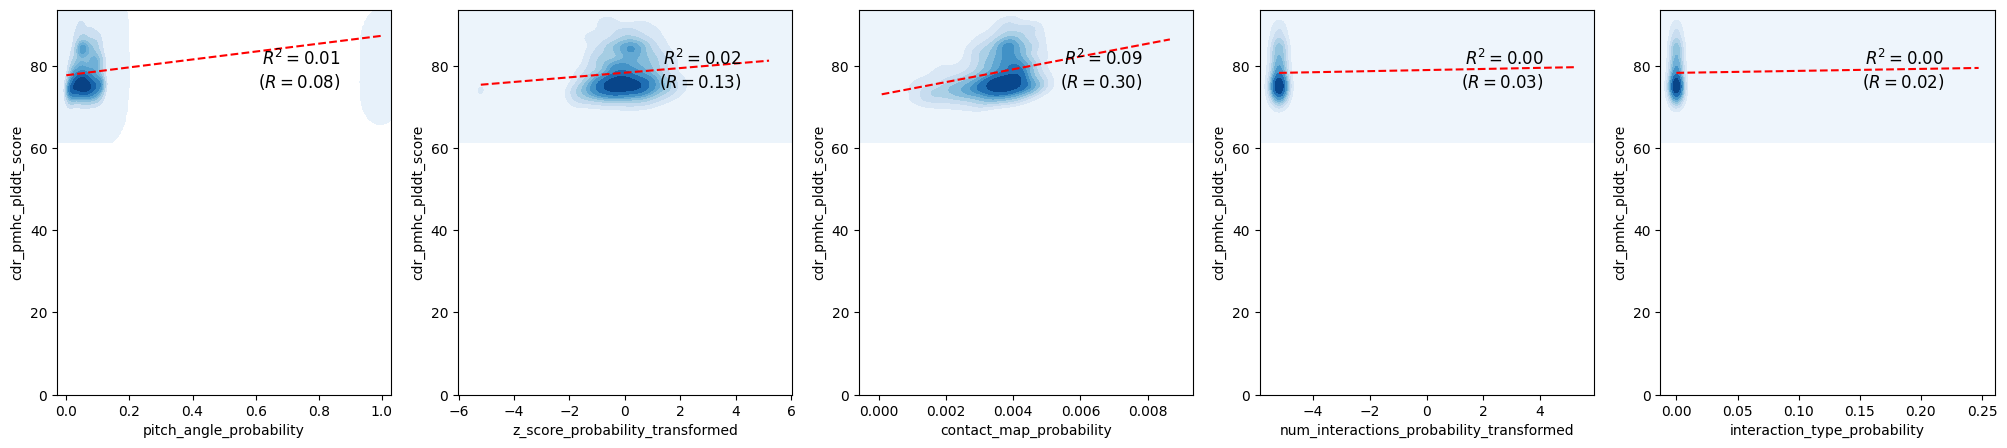

tcr_pmhc_plddt_score
Pearson's correlation: 0.17
                             OLS Regression Results                             
Dep. Variable:     tcr_pmhc_plddt_score   R-squared:                       0.028
Model:                              OLS   Adj. R-squared:                  0.027
Method:                   Least Squares   F-statistic:                     42.18
Date:                  Wed, 24 Sep 2025   Prob (F-statistic):           5.57e-43
Time:                          12:48:25   Log-Likelihood:                -11663.
No. Observations:                  7375   AIC:                         2.334e+04
Df Residuals:                      7369   BIC:                         2.338e+04
Df Model:                             5                                         
Covariance Type:              nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-1.202933,0.334572,-3.595439,0.999837,False
z_score_probability_transformed,0.026935,0.012200,2.207726,0.013647,True
contact_map_probability,187.495749,14.672328,12.778868,0.000000,True
num_interactions_probability_transformed,0.080795,0.042909,1.882936,0.029874,True
interaction_type_probability,-2.693931,2.261675,-1.191122,0.883178,False


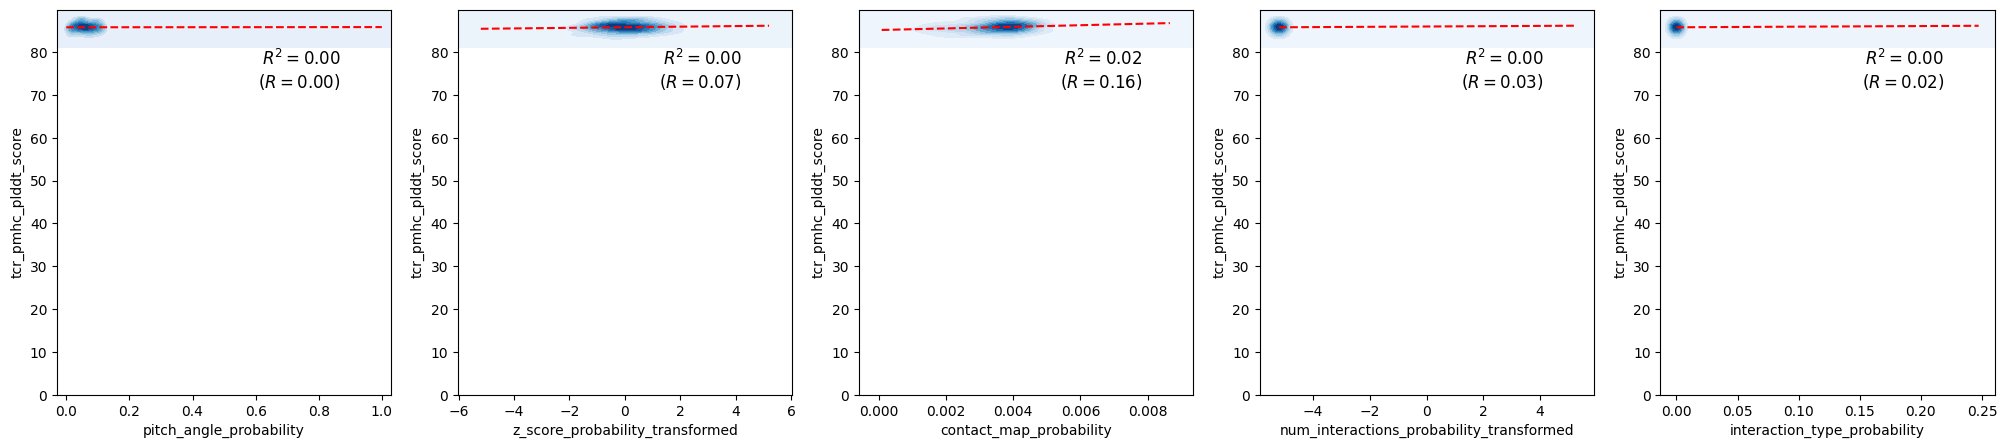

Best results: cdr_pmhc_plddt_score R^2: 0.09032109298758884


In [42]:
plddt_confidence_columns = sorted(structure_scores.filter(regex='plddt').columns.tolist())

best_r_squared = 0
best_reg = None
best_name = None

X = structure_scores[structure_probability_names]
X = sm.add_constant(X)

for confidence_column in plddt_confidence_columns:
    y = structure_scores[confidence_column]
    y_max = structure_scores[confidence_column].max()

    model = sm.OLS(y, X)
    reg = model.fit()
    pred_y = reg.fittedvalues

    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', scipy.stats.ConstantInputWarning)
            corr_coef, _ = scipy.stats.pearsonr(y, pred_y)

    except scipy.stats.ConstantInputWarning:
        print('Skipping', confidence_column)
        continue

    print(confidence_column)
    print('==============================================================================================')
    print(f"Pearson's correlation: {corr_coef:.2f}")
    print(reg.summary())
    print('\n\n')

    r_squared = reg.rsquared

    coefficients = pd.concat([reg.params[1:], reg.bse[1:]], axis=1)
    coefficients.columns = ['parameter', 'standard_error']

    coefficients['t_stat'] = coefficients['parameter'] / coefficients['standard_error']

    coefficients['probability'] = coefficients['t_stat'].apply(
        lambda t_stat, dof=reg.df_resid: 1 - scipy.stats.t.cdf(t_stat, df=dof)
    )
    coefficients['significant'] = coefficients['probability'] < SIGNIFICANCE_LEVEL

    display(coefficients)

    fig, axes = plt.subplots(1, len(structure_probability_names), figsize=(5 * len(structure_probability_names), 5))

    axes[0].set_ylabel(confidence_column)
    for i, column in enumerate(structure_probability_names):
        x = structure_scores[column]
        sns.kdeplot(x=x, y=y, cmap='Blues', fill=True, thresh=0, levels=10, ax=axes[i])

        reg = scipy.stats.linregress(x, y)
        x = np.linspace(x.min(), x.max())
        y_pred = reg.slope * x + reg.intercept

        axes[i].plot(x, y_pred, 'r--')
        axes[i].text(
            0.85,
            0.90,
            f'$R^2={reg.rvalue**2: .2f}$\n($R={reg.rvalue: .2f}$)',
            transform=axes[i].transAxes,
            horizontalalignment='right',
            verticalalignment='top',
            fontsize=12,
        )

        axes[i].set_xlabel(column)
        axes[i].set_ylim(0, y_max)

    plt.show()

    if r_squared > best_r_squared:
        best_r_squared = r_squared
        best_reg = reg
        best_name = confidence_column


print('==============================================================================================')
print('Best results:', best_name, 'R^2:', best_r_squared)
print('==============================================================================================')

alpha_chain_antigen_chain_ipsae
Pearson's correlation: 0.26
                                   OLS Regression Results                                  
Dep. Variable:     alpha_chain_antigen_chain_ipsae   R-squared:                       0.069
Model:                                         OLS   Adj. R-squared:                  0.068
Method:                              Least Squares   F-statistic:                     108.7
Date:                             Wed, 24 Sep 2025   Prob (F-statistic):          3.84e-111
Time:                                     12:48:44   Log-Likelihood:                 11544.
No. Observations:                             7375   AIC:                        -2.308e+04
Df Residuals:                                 7369   BIC:                        -2.304e+04
Df Model:                                        5                                         
Covariance Type:                         nonrobust                                         
                    

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.049959,0.014384,3.473194,0.000259,True
z_score_probability_transformed,0.001192,0.000525,2.272903,0.011530,True
contact_map_probability,12.349316,0.630797,19.577313,0.000000,True
num_interactions_probability_transformed,0.003147,0.001845,1.705849,0.044039,True
interaction_type_probability,-0.158521,0.097235,-1.630293,0.948459,False


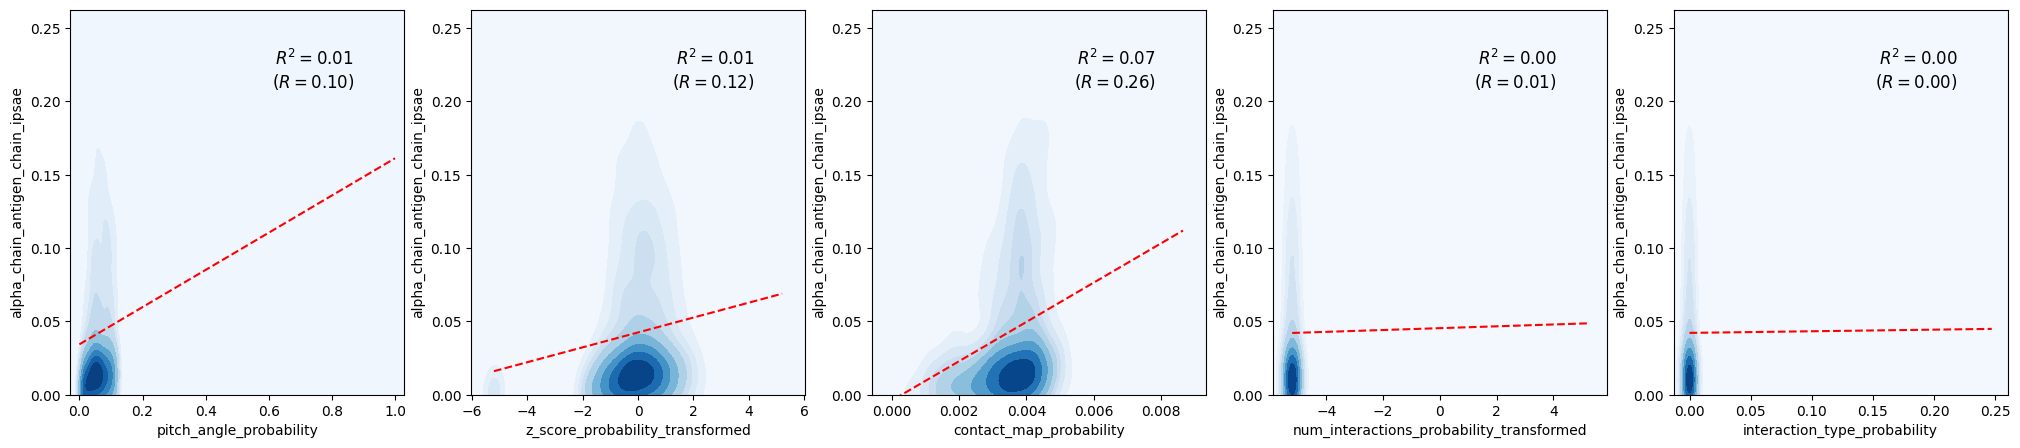

alpha_chain_beta_chain_ipsae
Pearson's correlation: 0.07
                                 OLS Regression Results                                 
Dep. Variable:     alpha_chain_beta_chain_ipsae   R-squared:                       0.006
Model:                                      OLS   Adj. R-squared:                  0.005
Method:                           Least Squares   F-statistic:                     8.269
Date:                          Wed, 24 Sep 2025   Prob (F-statistic):           8.40e-08
Time:                                  12:49:02   Log-Likelihood:                 16323.
No. Observations:                          7375   AIC:                        -3.263e+04
Df Residuals:                              7369   BIC:                        -3.259e+04
Df Model:                                     5                                         
Covariance Type:                      nonrobust                                         
                                               coef  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.022393,0.007524,-2.976018,9.985352e-01,False
z_score_probability_transformed,-0.000642,0.000274,-2.339921,9.903428e-01,False
contact_map_probability,1.637595,0.329973,4.962820,3.551751e-07,True
num_interactions_probability_transformed,0.002084,0.000965,2.159869,1.540747e-02,True
interaction_type_probability,-0.069050,0.050864,-1.357546,9.126753e-01,False


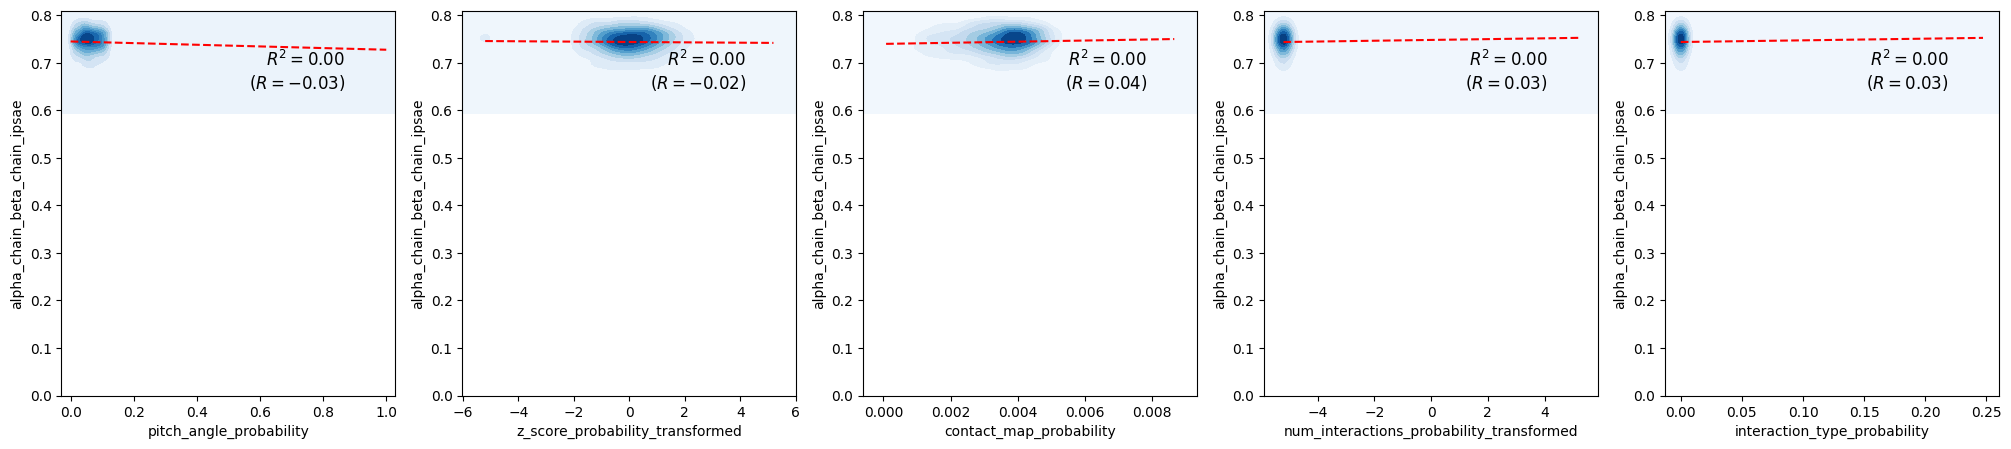

alpha_chain_mhc_chain1_ipsae
Pearson's correlation: 0.28
                                 OLS Regression Results                                 
Dep. Variable:     alpha_chain_mhc_chain1_ipsae   R-squared:                       0.079
Model:                                      OLS   Adj. R-squared:                  0.078
Method:                           Least Squares   F-statistic:                     125.6
Date:                          Wed, 24 Sep 2025   Prob (F-statistic):          4.59e-128
Time:                                  12:49:21   Log-Likelihood:                 101.84
No. Observations:                          7375   AIC:                            -191.7
Df Residuals:                              7369   BIC:                            -150.2
Df Model:                                     5                                         
Covariance Type:                      nonrobust                                         
                                               coef  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.330092,0.067874,4.863297,5.891976e-07,True
z_score_probability_transformed,0.011488,0.002475,4.641443,1.759843e-06,True
contact_map_probability,57.988918,2.976555,19.481892,0.000000e+00,True
num_interactions_probability_transformed,0.006523,0.008705,0.749321,2.268439e-01,False
interaction_type_probability,-0.178256,0.458823,-0.388507,6.511738e-01,False


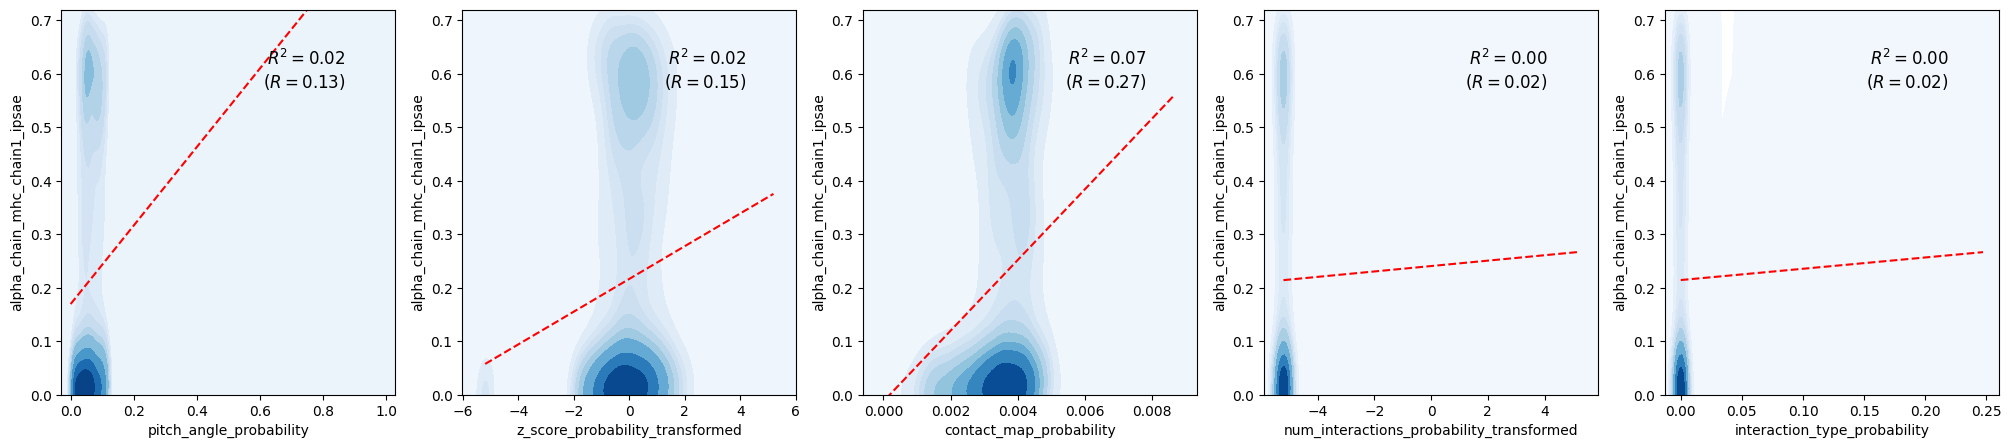

alpha_chain_mhc_chain2_ipsae
Pearson's correlation: 0.24
                                 OLS Regression Results                                 
Dep. Variable:     alpha_chain_mhc_chain2_ipsae   R-squared:                       0.057
Model:                                      OLS   Adj. R-squared:                  0.057
Method:                           Least Squares   F-statistic:                     89.41
Date:                          Wed, 24 Sep 2025   Prob (F-statistic):           1.30e-91
Time:                                  12:49:39   Log-Likelihood:                 9089.8
No. Observations:                          7375   AIC:                        -1.817e+04
Df Residuals:                              7369   BIC:                        -1.813e+04
Df Model:                                     5                                         
Covariance Type:                      nonrobust                                         
                                               coef  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.068888,0.020064,3.433345,0.000300,True
z_score_probability_transformed,0.001065,0.000732,1.455042,0.072850,False
contact_map_probability,15.776870,0.879907,17.930154,0.000000,True
num_interactions_probability_transformed,0.002461,0.002573,0.956376,0.169457,False
interaction_type_probability,-0.086928,0.135634,-0.640904,0.739198,False


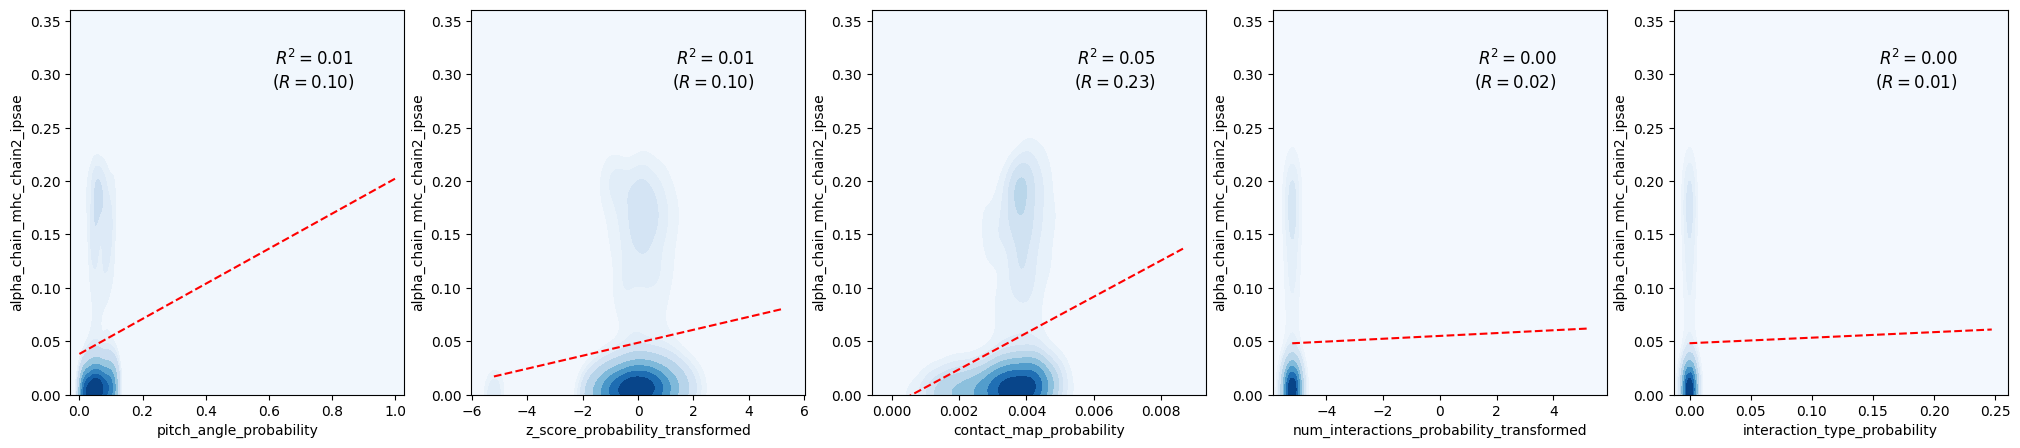

antigen_chain_alpha_chain_ipsae
Pearson's correlation: 0.25
                                   OLS Regression Results                                  
Dep. Variable:     antigen_chain_alpha_chain_ipsae   R-squared:                       0.060
Model:                                         OLS   Adj. R-squared:                  0.059
Method:                              Least Squares   F-statistic:                     94.25
Date:                             Wed, 24 Sep 2025   Prob (F-statistic):           1.62e-96
Time:                                     12:49:57   Log-Likelihood:                 2772.7
No. Observations:                             7375   AIC:                            -5533.
Df Residuals:                                 7369   BIC:                            -5492.
Df Model:                                        5                                         
Covariance Type:                         nonrobust                                         
                    

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.145160,0.047252,3.072011,0.001067,True
z_score_probability_transformed,0.006559,0.001723,3.806846,0.000071,True
contact_map_probability,36.297606,2.072208,17.516394,0.000000,True
num_interactions_probability_transformed,0.003889,0.006060,0.641695,0.260546,False
interaction_type_probability,-0.194583,0.319422,-0.609173,0.728786,False


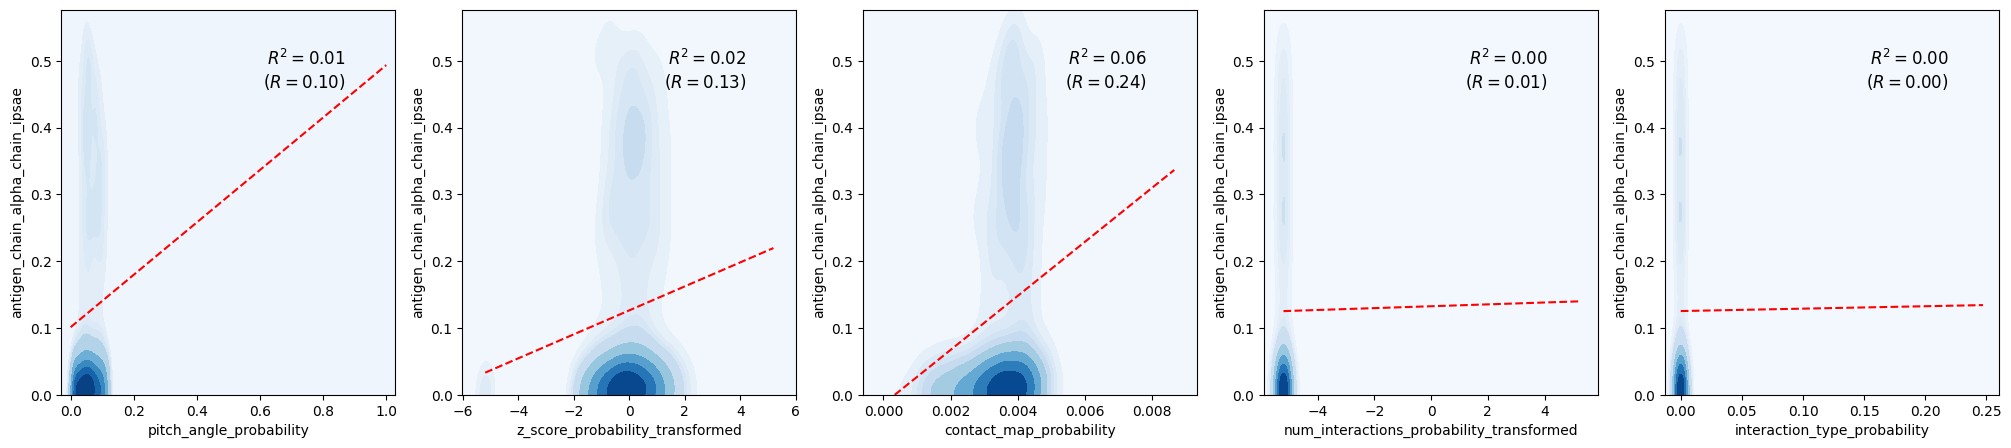

antigen_chain_beta_chain_ipsae
Pearson's correlation: 0.24
                                  OLS Regression Results                                  
Dep. Variable:     antigen_chain_beta_chain_ipsae   R-squared:                       0.060
Model:                                        OLS   Adj. R-squared:                  0.059
Method:                             Least Squares   F-statistic:                     93.32
Date:                            Wed, 24 Sep 2025   Prob (F-statistic):           1.41e-95
Time:                                    12:50:15   Log-Likelihood:                 2292.0
No. Observations:                            7375   AIC:                            -4572.
Df Residuals:                                7369   BIC:                            -4531.
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.096237,0.050435,1.908146,0.028206,True
z_score_probability_transformed,0.008554,0.001839,4.651171,0.000002,True
contact_map_probability,38.455497,2.211773,17.386727,0.000000,True
num_interactions_probability_transformed,0.004515,0.006468,0.697985,0.242604,False
interaction_type_probability,-0.226575,0.340935,-0.664569,0.746827,False


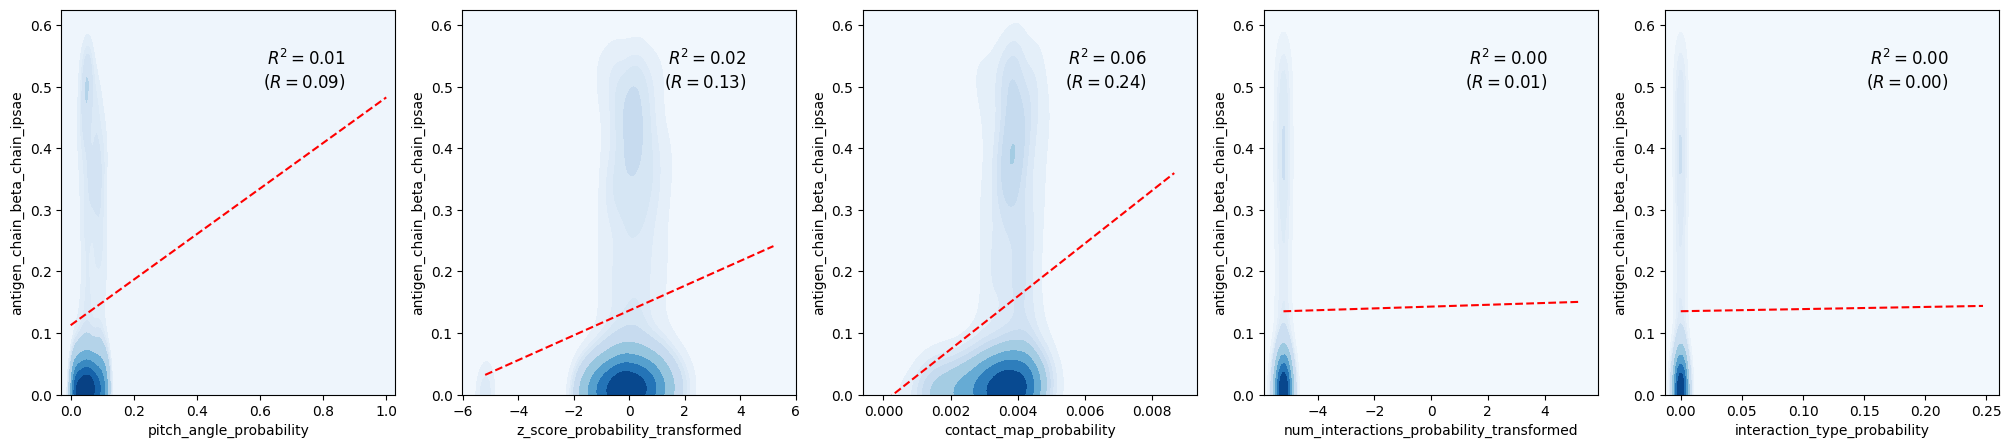

antigen_chain_mhc_chain1_ipsae
Pearson's correlation: 0.06
                                  OLS Regression Results                                  
Dep. Variable:     antigen_chain_mhc_chain1_ipsae   R-squared:                       0.004
Model:                                        OLS   Adj. R-squared:                  0.003
Method:                             Least Squares   F-statistic:                     5.909
Date:                            Wed, 24 Sep 2025   Prob (F-statistic):           1.86e-05
Time:                                    12:50:33   Log-Likelihood:                 8305.3
No. Observations:                            7375   AIC:                        -1.660e+04
Df Residuals:                                7369   BIC:                        -1.656e+04
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.063654,0.022316,-2.852361,0.997824,False
z_score_probability_transformed,0.000291,0.000814,0.357702,0.360288,False
contact_map_probability,3.336234,0.978659,3.408986,0.000328,True
num_interactions_probability_transformed,0.005221,0.002862,1.824208,0.034081,True
interaction_type_probability,-0.397624,0.150856,-2.635785,0.995794,False


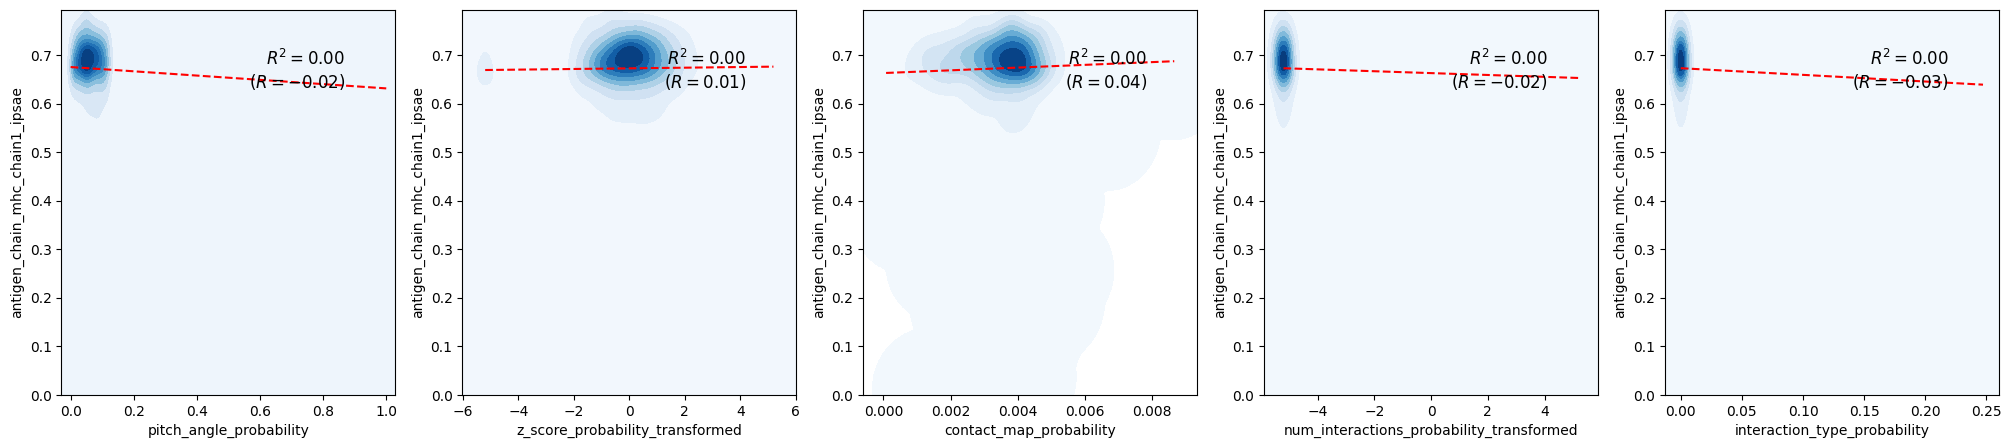

antigen_chain_mhc_chain2_ipsae
Pearson's correlation: 0.09
                                  OLS Regression Results                                  
Dep. Variable:     antigen_chain_mhc_chain2_ipsae   R-squared:                       0.009
Model:                                        OLS   Adj. R-squared:                  0.008
Method:                             Least Squares   F-statistic:                     12.64
Date:                            Wed, 24 Sep 2025   Prob (F-statistic):           2.99e-12
Time:                                    12:50:55   Log-Likelihood:                 9444.1
No. Observations:                            7375   AIC:                        -1.888e+04
Df Residuals:                                7369   BIC:                        -1.883e+04
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.104365,0.019123,-5.457453,1.000000,False
z_score_probability_transformed,0.000199,0.000697,0.284705,0.387939,False
contact_map_probability,3.884543,0.838638,4.631965,0.000002,True
num_interactions_probability_transformed,0.002785,0.002453,1.135422,0.128118,False
interaction_type_probability,-0.307636,0.129272,-2.379753,0.991325,False


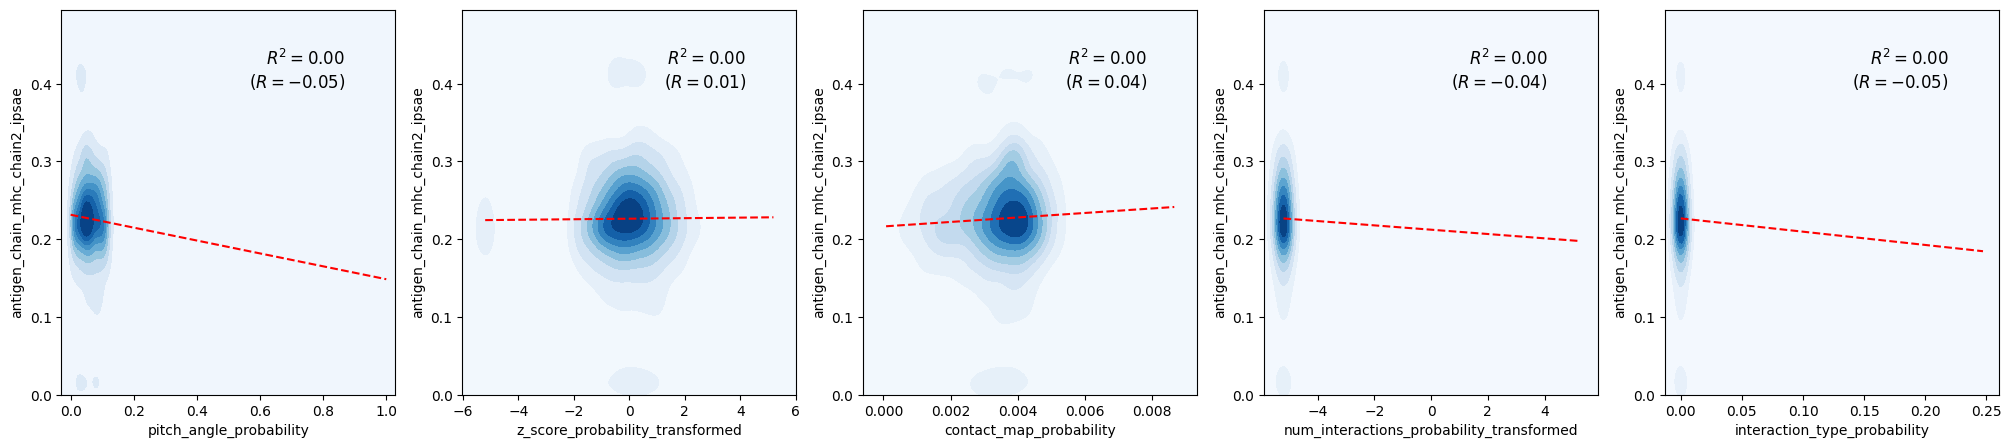

beta_chain_alpha_chain_ipsae
Pearson's correlation: 0.09
                                 OLS Regression Results                                 
Dep. Variable:     beta_chain_alpha_chain_ipsae   R-squared:                       0.008
Model:                                      OLS   Adj. R-squared:                  0.008
Method:                           Least Squares   F-statistic:                     12.20
Date:                          Wed, 24 Sep 2025   Prob (F-statistic):           8.45e-12
Time:                                  12:51:14   Log-Likelihood:                 18122.
No. Observations:                          7375   AIC:                        -3.623e+04
Df Residuals:                              7369   BIC:                        -3.619e+04
Df Model:                                     5                                         
Covariance Type:                      nonrobust                                         
                                               coef  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.019364,0.005896,-3.284399,0.999487,False
z_score_probability_transformed,-0.000890,0.000215,-4.139621,0.999982,False
contact_map_probability,-0.505561,0.258553,-1.955349,0.974710,False
num_interactions_probability_transformed,0.002030,0.000756,2.684942,0.003635,True
interaction_type_probability,-0.087398,0.039855,-2.192921,0.985828,False


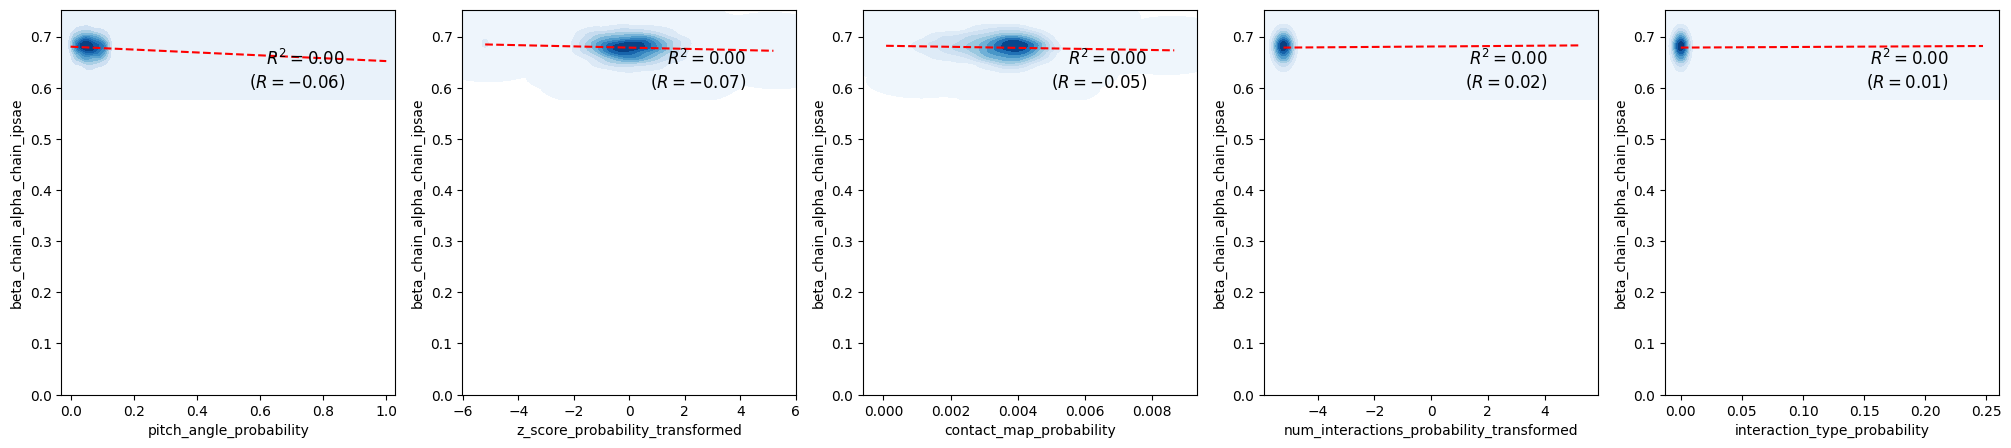

beta_chain_antigen_chain_ipsae
Pearson's correlation: 0.24
                                  OLS Regression Results                                  
Dep. Variable:     beta_chain_antigen_chain_ipsae   R-squared:                       0.058
Model:                                        OLS   Adj. R-squared:                  0.057
Method:                             Least Squares   F-statistic:                     90.59
Date:                            Wed, 24 Sep 2025   Prob (F-statistic):           8.28e-93
Time:                                    12:51:32   Log-Likelihood:                 11367.
No. Observations:                            7375   AIC:                        -2.272e+04
Df Residuals:                                7369   BIC:                        -2.268e+04
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.023551,0.014734,1.598384,0.055000,False
z_score_probability_transformed,0.002311,0.000537,4.301736,0.000009,True
contact_map_probability,11.224558,0.646143,17.371632,0.000000,True
num_interactions_probability_transformed,0.001073,0.001890,0.567923,0.285052,False
interaction_type_probability,-0.031110,0.099600,-0.312350,0.622608,False


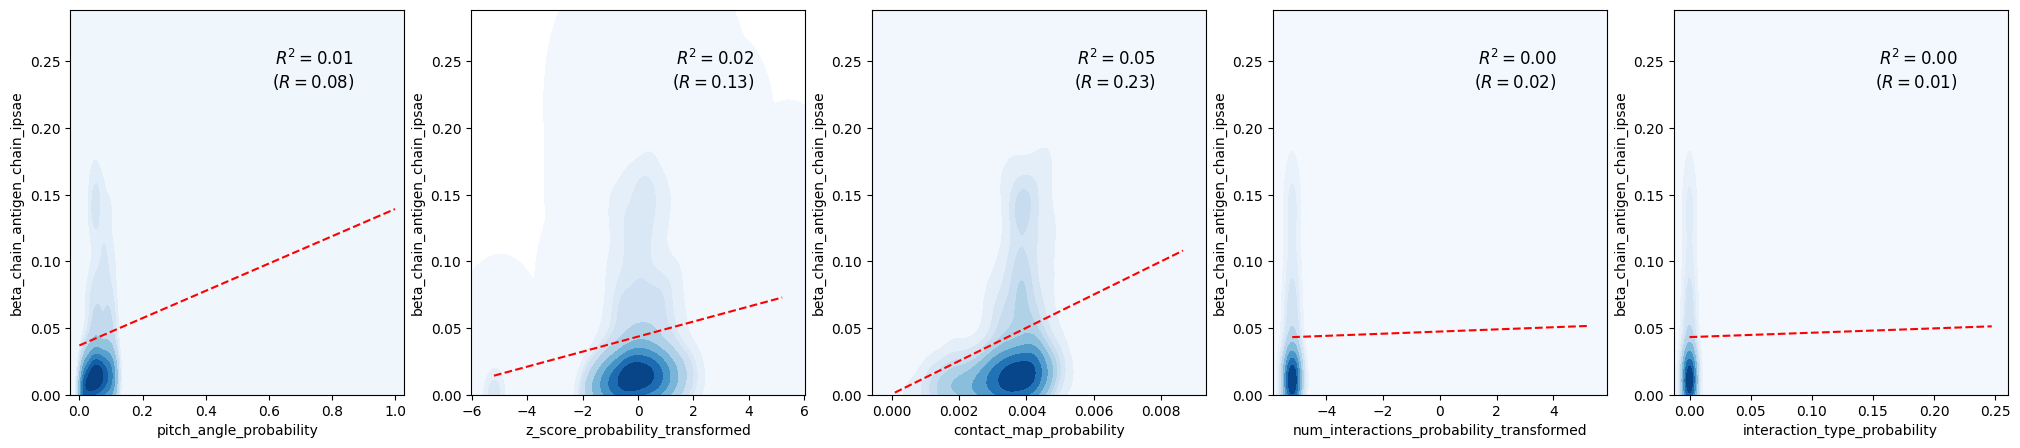

beta_chain_mhc_chain1_ipsae
Pearson's correlation: 0.27
                                 OLS Regression Results                                
Dep. Variable:     beta_chain_mhc_chain1_ipsae   R-squared:                       0.075
Model:                                     OLS   Adj. R-squared:                  0.074
Method:                          Least Squares   F-statistic:                     119.1
Date:                         Wed, 24 Sep 2025   Prob (F-statistic):          1.41e-121
Time:                                 12:51:51   Log-Likelihood:                 172.61
No. Observations:                         7375   AIC:                            -333.2
Df Residuals:                             7369   BIC:                            -291.8
Df Model:                                    5                                         
Covariance Type:                     nonrobust                                         
                                               coef    std err  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.267350,0.067226,3.976894,3.524468e-05,True
z_score_probability_transformed,0.013345,0.002451,5.443750,2.692514e-08,True
contact_map_probability,55.383092,2.948126,18.785861,0.000000e+00,True
num_interactions_probability_transformed,0.004411,0.008622,0.511627,3.044637e-01,False
interaction_type_probability,-0.067161,0.454441,-0.147788,5.587428e-01,False


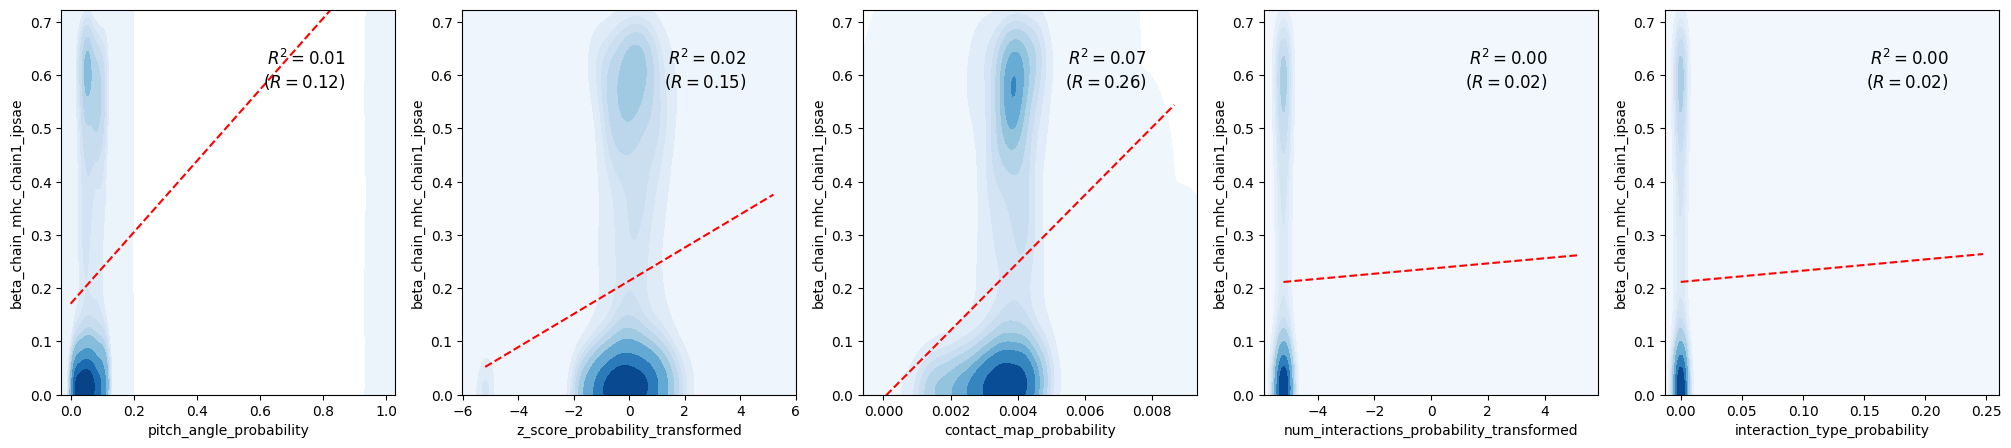

beta_chain_mhc_chain2_ipsae
Pearson's correlation: 0.24
                                 OLS Regression Results                                
Dep. Variable:     beta_chain_mhc_chain2_ipsae   R-squared:                       0.056
Model:                                     OLS   Adj. R-squared:                  0.055
Method:                          Least Squares   F-statistic:                     86.62
Date:                         Wed, 24 Sep 2025   Prob (F-statistic):           9.01e-89
Time:                                 12:52:09   Log-Likelihood:                 8417.5
No. Observations:                         7375   AIC:                        -1.682e+04
Df Residuals:                             7369   BIC:                        -1.678e+04
Df Model:                                    5                                         
Covariance Type:                     nonrobust                                         
                                               coef    std err  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.046646,0.021980,2.122237,0.016926,True
z_score_probability_transformed,0.002564,0.000801,3.199163,0.000692,True
contact_map_probability,16.694772,0.963892,17.320172,0.000000,True
num_interactions_probability_transformed,0.000885,0.002819,0.314044,0.376748,False
interaction_type_probability,0.001725,0.148580,0.011611,0.495368,False


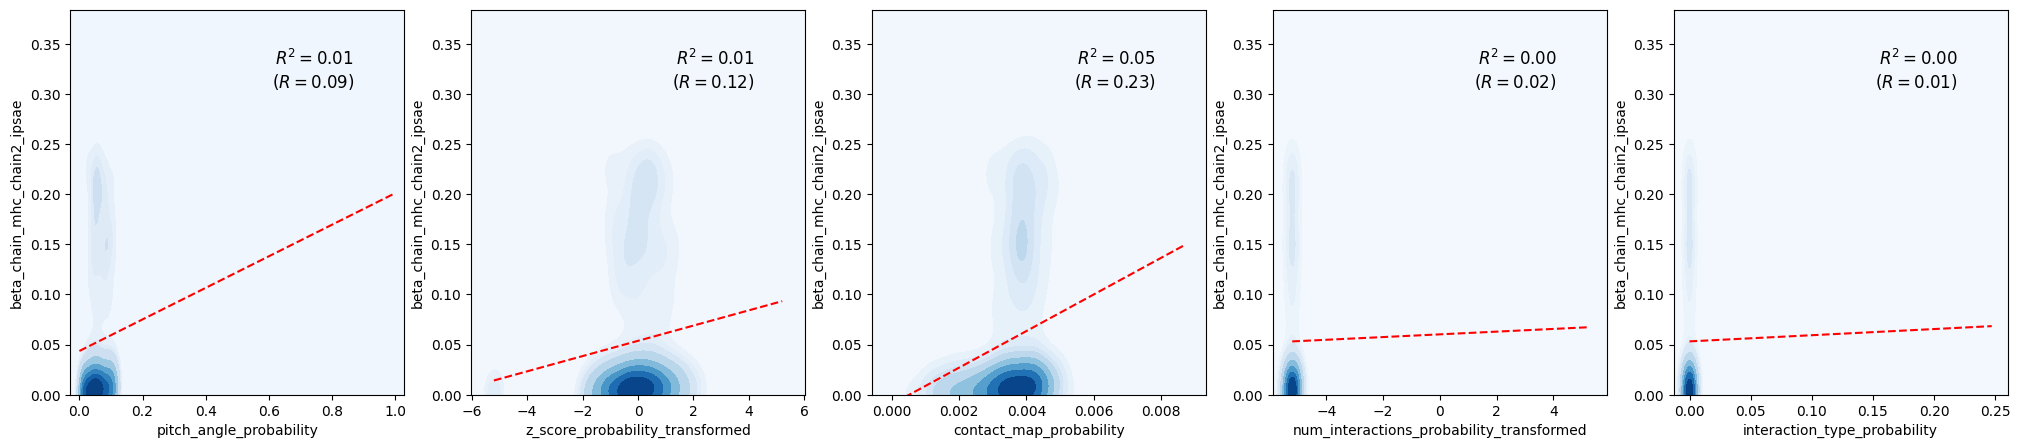

combined_ipsaes
Pearson's correlation: 0.25
                            OLS Regression Results                            
Dep. Variable:        combined_ipsaes   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     97.59
Date:                Wed, 24 Sep 2025   Prob (F-statistic):          6.70e-100
Time:                        12:52:27   Log-Likelihood:                 5822.5
No. Observations:                7375   AIC:                        -1.163e+04
Df Residuals:                    7369   BIC:                        -1.159e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.078727,0.031248,2.519378,0.005889,True
z_score_probability_transformed,0.004654,0.001139,4.084521,0.000022,True
contact_map_probability,24.581744,1.370368,17.938061,0.000000,True
num_interactions_probability_transformed,0.003156,0.004008,0.787473,0.215515,False
interaction_type_probability,-0.152697,0.211236,-0.722874,0.765110,False


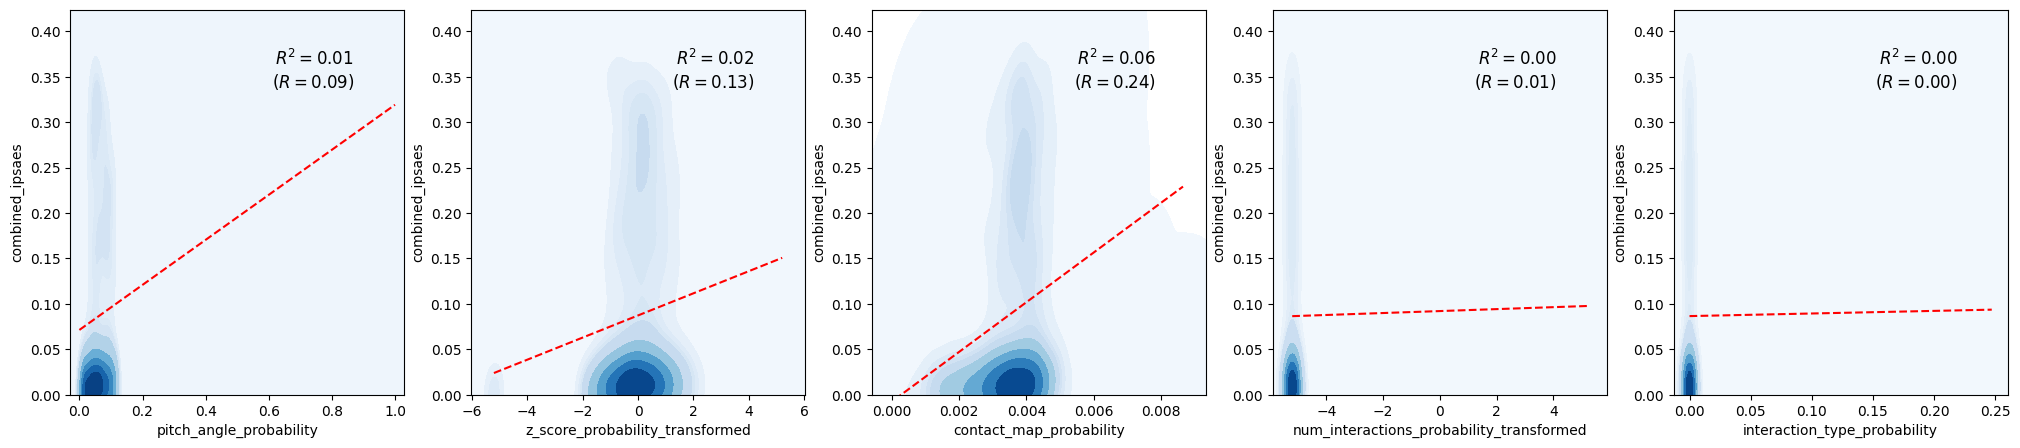

mhc_chain1_alpha_chain_ipsae
Pearson's correlation: 0.27
                                 OLS Regression Results                                 
Dep. Variable:     mhc_chain1_alpha_chain_ipsae   R-squared:                       0.071
Model:                                      OLS   Adj. R-squared:                  0.070
Method:                           Least Squares   F-statistic:                     112.1
Date:                          Wed, 24 Sep 2025   Prob (F-statistic):          1.69e-114
Time:                                  12:52:46   Log-Likelihood:                 1041.7
No. Observations:                          7375   AIC:                            -2071.
Df Residuals:                              7369   BIC:                            -2030.
Df Model:                                     5                                         
Covariance Type:                      nonrobust                                         
                                               coef  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.281281,0.059753,4.707391,0.000001,True
z_score_probability_transformed,0.008733,0.002179,4.008162,0.000031,True
contact_map_probability,48.656796,2.620408,18.568401,0.000000,True
num_interactions_probability_transformed,0.004803,0.007663,0.626764,0.265417,False
interaction_type_probability,-0.139374,0.403924,-0.345050,0.634967,False


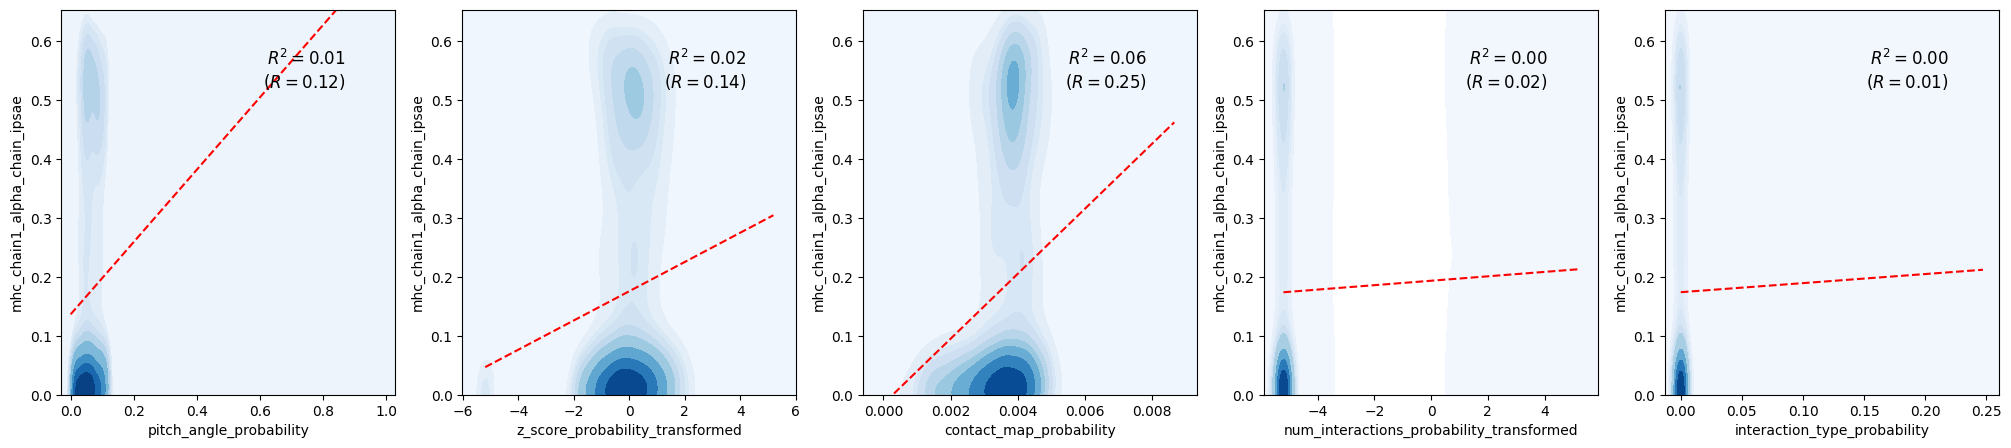

mhc_chain1_antigen_chain_ipsae
Pearson's correlation: 0.10
                                  OLS Regression Results                                  
Dep. Variable:     mhc_chain1_antigen_chain_ipsae   R-squared:                       0.009
Model:                                        OLS   Adj. R-squared:                  0.008
Method:                             Least Squares   F-statistic:                     13.59
Date:                            Wed, 24 Sep 2025   Prob (F-statistic):           3.12e-13
Time:                                    12:53:06   Log-Likelihood:                 9661.1
No. Observations:                            7375   AIC:                        -1.931e+04
Df Residuals:                                7369   BIC:                        -1.927e+04
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.077298,0.018569,-4.162736,9.999841e-01,False
z_score_probability_transformed,0.001332,0.000677,1.967209,2.459831e-02,True
contact_map_probability,4.636362,0.814322,5.693521,6.461419e-09,True
num_interactions_probability_transformed,0.001817,0.002381,0.763084,2.227190e-01,False
interaction_type_probability,-0.242597,0.125524,-1.932670,9.733424e-01,False


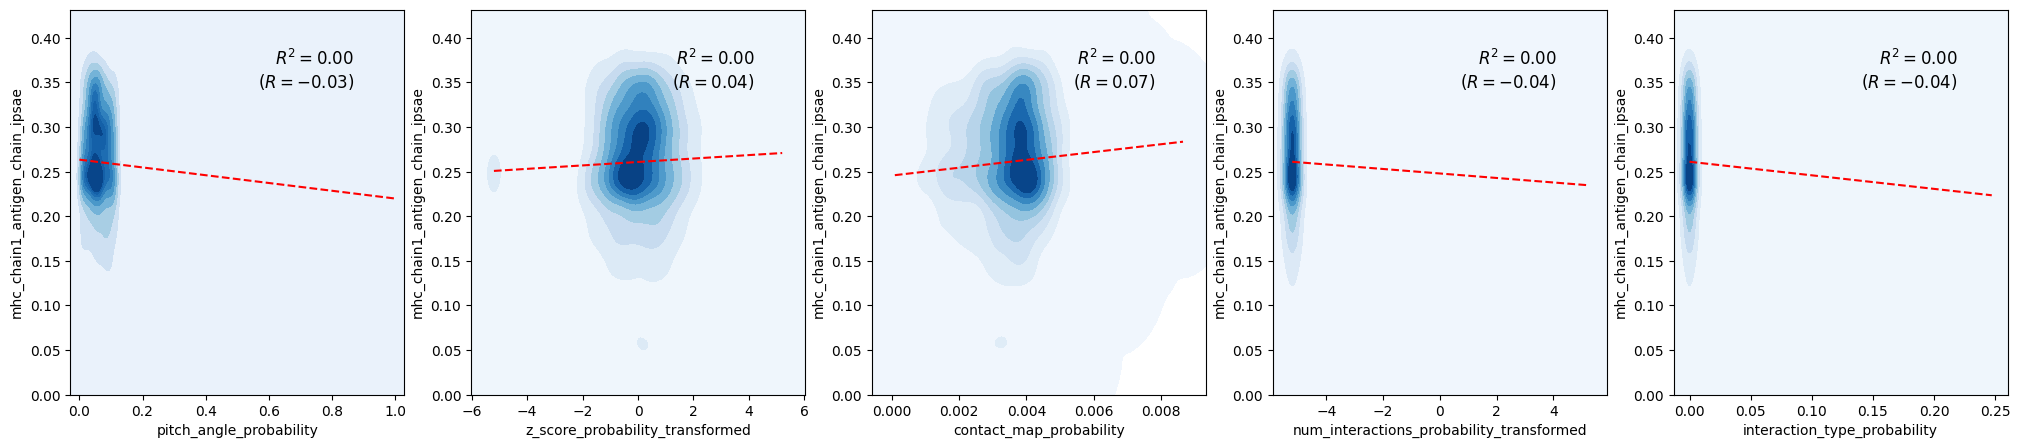

mhc_chain1_beta_chain_ipsae
Pearson's correlation: 0.27
                                 OLS Regression Results                                
Dep. Variable:     mhc_chain1_beta_chain_ipsae   R-squared:                       0.073
Model:                                     OLS   Adj. R-squared:                  0.072
Method:                          Least Squares   F-statistic:                     116.2
Date:                         Wed, 24 Sep 2025   Prob (F-statistic):          1.28e-118
Time:                                 12:53:24   Log-Likelihood:                 583.76
No. Observations:                         7375   AIC:                            -1156.
Df Residuals:                             7369   BIC:                            -1114.
Df Model:                                    5                                         
Covariance Type:                     nonrobust                                         
                                               coef    std err  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.239995,0.063581,3.774653,8.074460e-05,True
z_score_probability_transformed,0.011412,0.002318,4.922263,4.370360e-07,True
contact_map_probability,52.656806,2.788269,18.885121,0.000000e+00,True
num_interactions_probability_transformed,0.005034,0.008154,0.617343,2.685137e-01,False
interaction_type_probability,-0.130116,0.429799,-0.302737,6.189507e-01,False


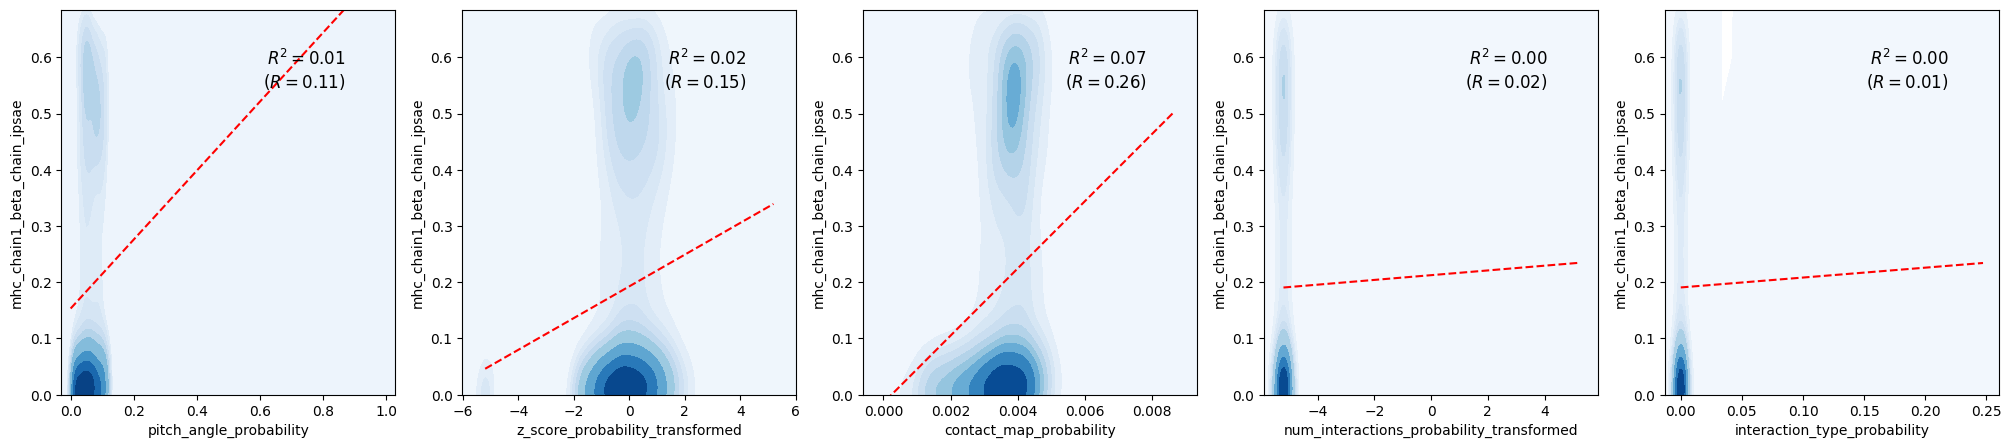

mhc_chain1_mhc_chain2_ipsae
Pearson's correlation: 0.11
                                 OLS Regression Results                                
Dep. Variable:     mhc_chain1_mhc_chain2_ipsae   R-squared:                       0.011
Model:                                     OLS   Adj. R-squared:                  0.011
Method:                          Least Squares   F-statistic:                     16.71
Date:                         Wed, 24 Sep 2025   Prob (F-statistic):           1.89e-16
Time:                                 12:53:44   Log-Likelihood:                 10475.
No. Observations:                         7375   AIC:                        -2.094e+04
Df Residuals:                             7369   BIC:                        -2.090e+04
Df Model:                                    5                                         
Covariance Type:                     nonrobust                                         
                                               coef    std err  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.099257,0.016628,-5.969226,1.000000e+00,False
z_score_probability_transformed,0.000037,0.000606,0.060884,4.757265e-01,False
contact_map_probability,5.448484,0.729207,7.471792,4.407585e-14,True
num_interactions_probability_transformed,-0.002137,0.002133,-1.002067,8.418279e-01,False
interaction_type_probability,0.052163,0.112404,0.464069,3.213059e-01,False


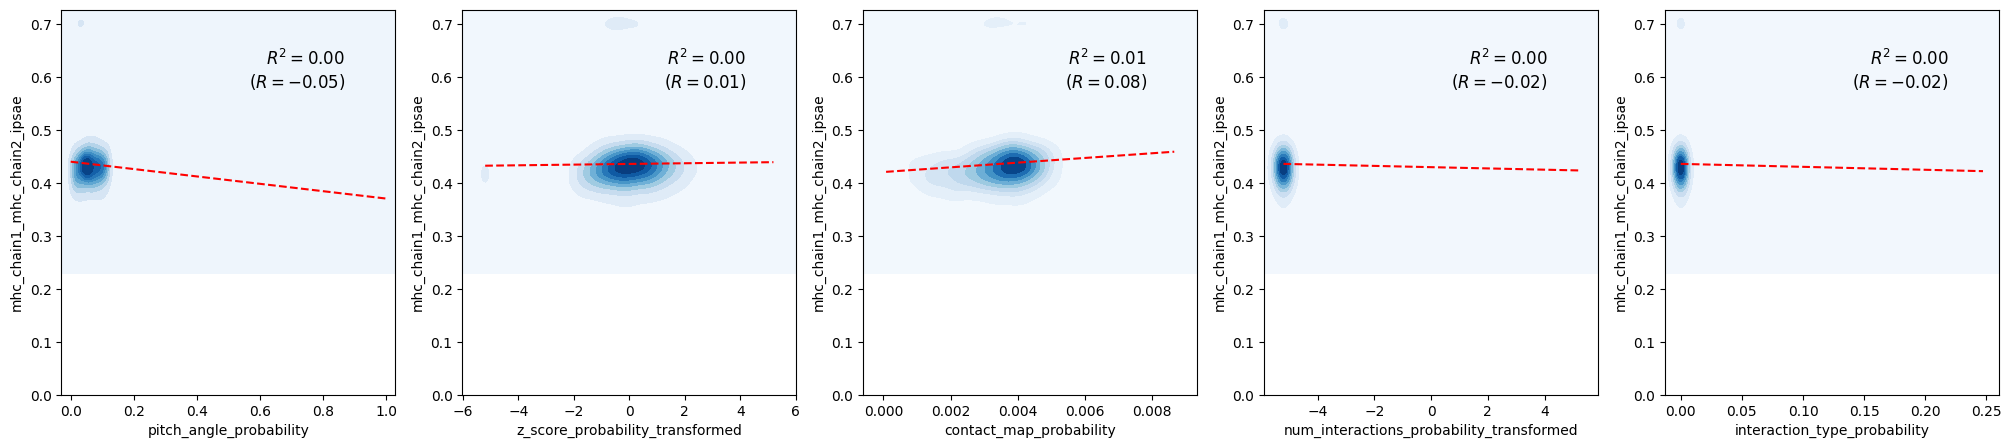

mhc_chain2_alpha_chain_ipsae
Pearson's correlation: 0.25
                                 OLS Regression Results                                 
Dep. Variable:     mhc_chain2_alpha_chain_ipsae   R-squared:                       0.064
Model:                                      OLS   Adj. R-squared:                  0.063
Method:                           Least Squares   F-statistic:                     100.3
Date:                          Wed, 24 Sep 2025   Prob (F-statistic):          1.17e-102
Time:                                  12:54:02   Log-Likelihood:                 4915.9
No. Observations:                          7375   AIC:                            -9820.
Df Residuals:                              7369   BIC:                            -9778.
Df Model:                                     5                                         
Covariance Type:                      nonrobust                                         
                                               coef  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.154583,0.035336,4.374699,0.000006,True
z_score_probability_transformed,0.004829,0.001289,3.747460,0.000090,True
contact_map_probability,27.284128,1.549616,17.607025,0.000000,True
num_interactions_probability_transformed,0.003279,0.004532,0.723459,0.234710,False
interaction_type_probability,-0.088379,0.238866,-0.369992,0.644301,False


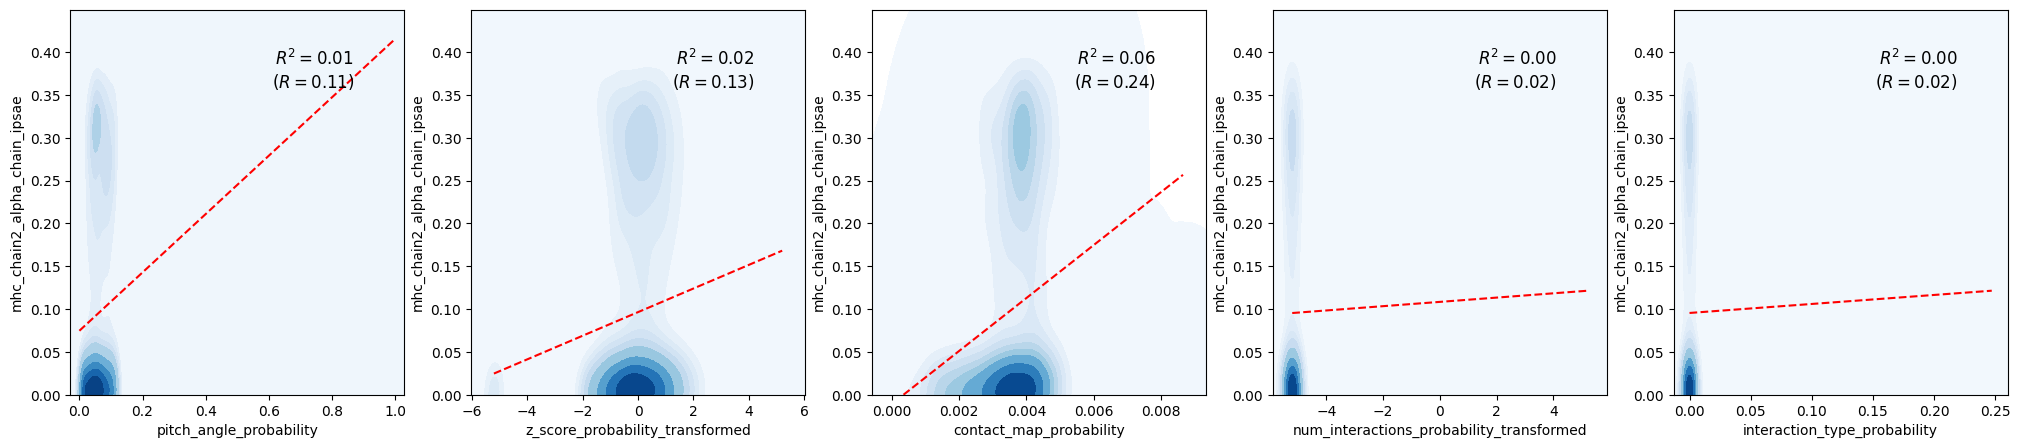

mhc_chain2_antigen_chain_ipsae
Pearson's correlation: 0.08
                                  OLS Regression Results                                  
Dep. Variable:     mhc_chain2_antigen_chain_ipsae   R-squared:                       0.007
Model:                                        OLS   Adj. R-squared:                  0.006
Method:                             Least Squares   F-statistic:                     10.26
Date:                            Wed, 24 Sep 2025   Prob (F-statistic):           8.17e-10
Time:                                    12:54:21   Log-Likelihood:                 17002.
No. Observations:                            7375   AIC:                        -3.399e+04
Df Residuals:                                7369   BIC:                        -3.395e+04
Df Model:                                       5                                         
Covariance Type:                        nonrobust                                         
                               

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.030953,0.006863,-4.510355,0.999997,False
z_score_probability_transformed,0.000611,0.000250,2.442643,0.007302,True
contact_map_probability,1.297193,0.300959,4.310195,0.000008,True
num_interactions_probability_transformed,0.000707,0.000880,0.802886,0.211033,False
interaction_type_probability,-0.076544,0.046392,-1.649965,0.950504,False


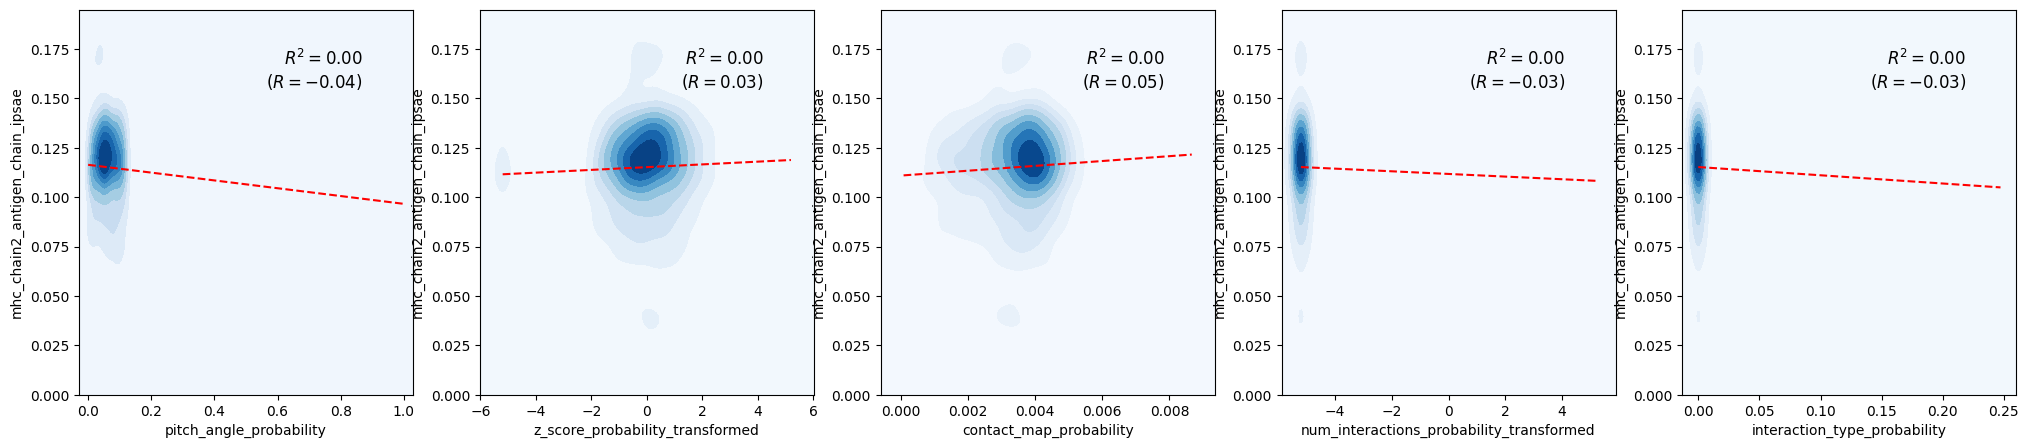

mhc_chain2_beta_chain_ipsae
Pearson's correlation: 0.25
                                 OLS Regression Results                                
Dep. Variable:     mhc_chain2_beta_chain_ipsae   R-squared:                       0.065
Model:                                     OLS   Adj. R-squared:                  0.064
Method:                          Least Squares   F-statistic:                     101.8
Date:                         Wed, 24 Sep 2025   Prob (F-statistic):          3.70e-104
Time:                                 12:54:41   Log-Likelihood:                 4022.5
No. Observations:                         7375   AIC:                            -8033.
Df Residuals:                             7369   BIC:                            -7991.
Df Model:                                    5                                         
Covariance Type:                     nonrobust                                         
                                               coef    std err  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,0.118221,0.039887,2.963916,0.001524,True
z_score_probability_transformed,0.006841,0.001454,4.703722,0.000001,True
contact_map_probability,31.168394,1.749198,17.818680,0.000000,True
num_interactions_probability_transformed,0.004475,0.005115,0.874859,0.190840,False
interaction_type_probability,-0.119734,0.269631,-0.444066,0.671496,False


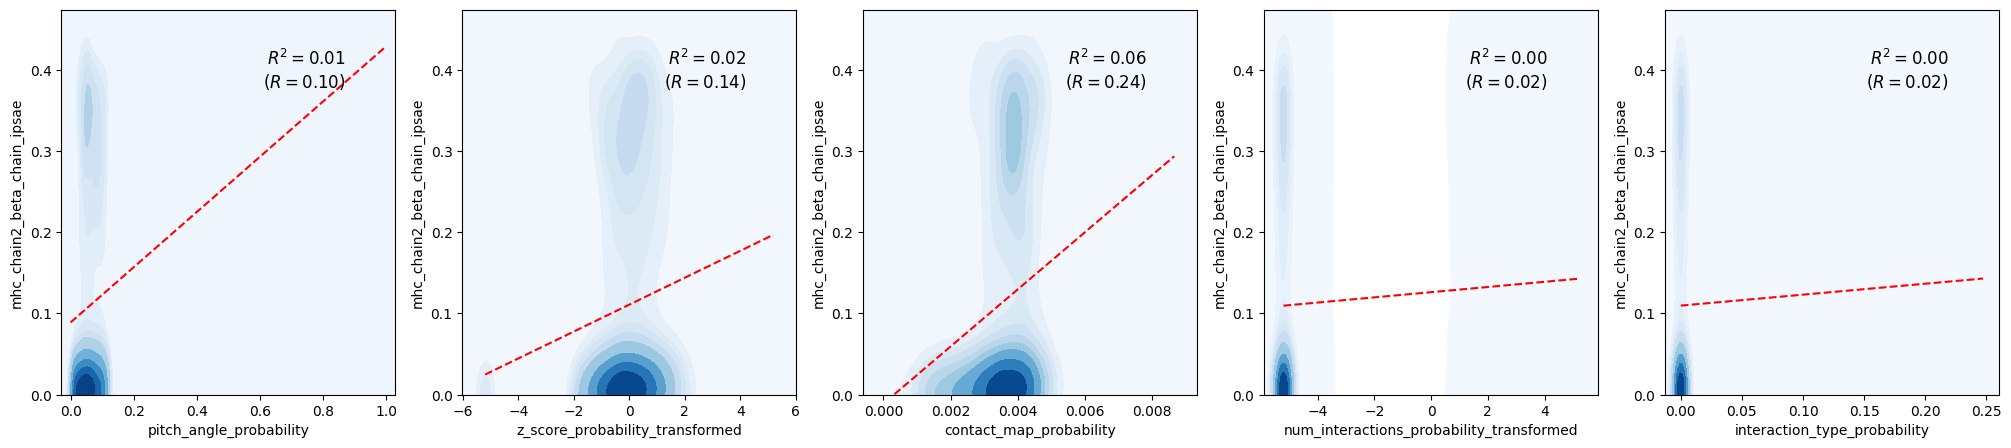

mhc_chain2_mhc_chain1_ipsae
Pearson's correlation: 0.07
                                 OLS Regression Results                                
Dep. Variable:     mhc_chain2_mhc_chain1_ipsae   R-squared:                       0.006
Model:                                     OLS   Adj. R-squared:                  0.005
Method:                          Least Squares   F-statistic:                     8.166
Date:                         Wed, 24 Sep 2025   Prob (F-statistic):           1.07e-07
Time:                                 12:55:00   Log-Likelihood:                 15778.
No. Observations:                         7375   AIC:                        -3.154e+04
Df Residuals:                             7369   BIC:                        -3.150e+04
Df Model:                                    5                                         
Covariance Type:                     nonrobust                                         
                                               coef    std err  

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-0.025853,0.008102,-3.191049,0.999288,False
z_score_probability_transformed,0.000882,0.000295,2.987043,0.001413,True
contact_map_probability,1.431279,0.355291,4.028464,0.000028,True
num_interactions_probability_transformed,0.001355,0.001039,1.303974,0.096142,False
interaction_type_probability,-0.047873,0.054767,-0.874127,0.808961,False


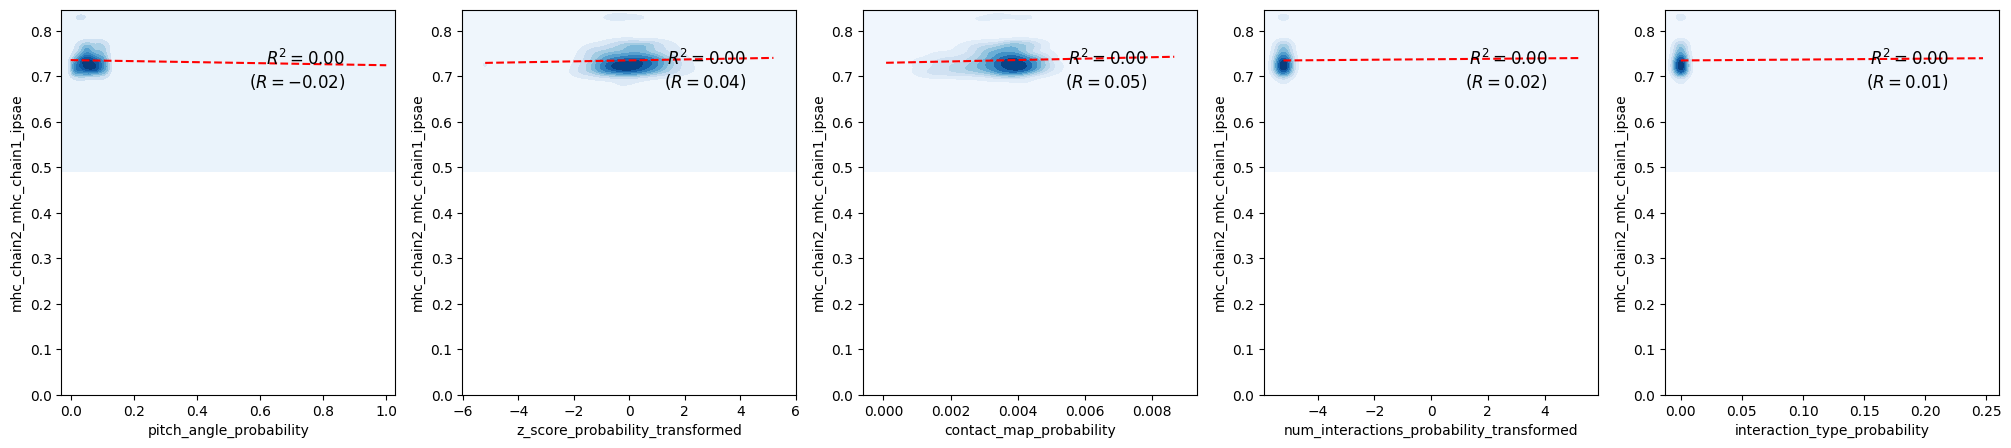

Best results: alpha_chain_mhc_chain1_ipsae R^2: 0.07855313117435303


In [43]:
ipsae_confidence_columns = sorted(structure_scores.filter(regex='ipsae').columns.tolist())

best_r_squared = 0
best_reg = None
best_name = None

X = structure_scores[structure_probability_names]
X = sm.add_constant(X)

for confidence_column in ipsae_confidence_columns:
    y = structure_scores[confidence_column]
    y_max = structure_scores[confidence_column].max()

    model = sm.OLS(y, X)
    reg = model.fit()
    pred_y = reg.fittedvalues

    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', scipy.stats.ConstantInputWarning)
            corr_coef, _ = scipy.stats.pearsonr(y, pred_y)

    except scipy.stats.ConstantInputWarning:
        print('Skipping', confidence_column)
        continue

    print(confidence_column)
    print('==============================================================================================')
    print(f"Pearson's correlation: {corr_coef:.2f}")
    print(reg.summary())
    print('\n\n')

    r_squared = reg.rsquared

    coefficients = pd.concat([reg.params[1:], reg.bse[1:]], axis=1)
    coefficients.columns = ['parameter', 'standard_error']

    coefficients['t_stat'] = coefficients['parameter'] / coefficients['standard_error']

    coefficients['probability'] = coefficients['t_stat'].apply(
        lambda t_stat, dof=reg.df_resid: 1 - scipy.stats.t.cdf(t_stat, df=dof)
    )
    coefficients['significant'] = coefficients['probability'] < SIGNIFICANCE_LEVEL

    display(coefficients)

    fig, axes = plt.subplots(1, len(structure_probability_names), figsize=(5 * len(structure_probability_names), 5))

    axes[0].set_ylabel(confidence_column)
    for i, column in enumerate(structure_probability_names):
        x = structure_scores[column]
        sns.kdeplot(x=x, y=y, cmap='Blues', fill=True, thresh=0, levels=10, ax=axes[i])

        reg = scipy.stats.linregress(x, y)
        x = np.linspace(x.min(), x.max())
        y_pred = reg.slope * x + reg.intercept

        axes[i].plot(x, y_pred, 'r--')
        axes[i].text(
            0.85,
            0.90,
            f'$R^2={reg.rvalue**2: .2f}$\n($R={reg.rvalue: .2f}$)',
            transform=axes[i].transAxes,
            horizontalalignment='right',
            verticalalignment='top',
            fontsize=12,
        )

        axes[i].set_xlabel(column)
        axes[i].set_ylim(0, y_max)

    plt.show()

    if r_squared > best_r_squared:
        best_r_squared = r_squared
        best_reg = reg
        best_name = confidence_column


print('==============================================================================================')
print('Best results:', best_name, 'R^2:', best_r_squared)
print('==============================================================================================')